# The Inductive Bias of Attention in Regularized Equilibrium Selection — Experiment Notebook

Implements the full Tier-0/1 experimental harness and runs every experiment, metric, comparison,
and ablation the paper needs: ground-truth, selection (Q1), convergence entanglement, stability
(Q2), the gap-law / on–off-manifold decomposition (Q3), solver comparison (R-NaD vs NashPG), the
ablation matrix, capacity scaling, and off-equilibrium robustness with mediation (Q4).

**Design.** Architecture is the *only* changed component; the policy is a **table**, an **MLP**, or
an **attention** network mapping infoset features to action logits. Counterfactual values are
**exact** (no sampling), so any difference in the selected equilibrium is attributable to the
network's inductive bias. Entropy shortfall is measured as `delta_excess = delta_deep - delta_tabular(game, eta)`
against an exact tabular baseline; deviation from the max-entropy member is decomposed into a
**transverse** part (exploitability) and an **along-manifold** part (coordinate gap). The study is
**outcome-agnostic**.

> **One-switch scale control.** All compute-limiting choices live in the **Configuration** cell
> below. Set `PRESET = "quick"` for the fast CPU run (~5 min) or `PRESET = "full"` for the
> paper-grade run (many seeds / long training / fine grids — intended for a GPU or cluster, hours on
> CPU). You can also set `PRESET = "custom"` and edit any field of `CFG` directly (a specific list
> of seeds, number of training iterations, eta-grid, capacity sizes). Nothing else in the notebook
> hard-codes a seed count or iteration budget.

## 0a · Workspace bootstrap (Colab-safe)

Colab uploads notebooks to `/content`, which is **wiped when the runtime is
recycled**. This notebook writes its modules and its run caches to the current
working directory, so left in `/content` a disconnect costs you every completed
run (~3 h of compute on two cores).

The cell below therefore mounts Google Drive and switches the working directory to
a persistent folder, regardless of where the notebook itself was uploaded. It also
rescues any caches sitting in `/content` from an earlier session, and merges stray
parallel shards. Outside Colab it is a no-op and the current directory is used.

In [1]:
# ---- persistent workspace -----------------------------------------------------
# Runs anywhere: mounts Drive on Colab, no-ops elsewhere. Safe to re-run.
import os, glob, shutil, json

WORKDIR = None
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/nash_study"
    os.makedirs(WORKDIR, exist_ok=True)
    # rescue caches left in the ephemeral upload directory by an earlier session
    for _f in glob.glob("/content/*.json"):
        _dst = os.path.join(WORKDIR, os.path.basename(_f))
        if not os.path.exists(_dst) or os.path.getsize(_f) > os.path.getsize(_dst):
            shutil.copy(_f, _dst); print("rescued from /content:", os.path.basename(_f))
    os.chdir(WORKDIR)
else:
    WORKDIR = os.getcwd()

# fold any leftover parallel shards into the main Stage-C cache
_sh = sorted(glob.glob("stageC_cache_s*.json"))
if _sh:
    _m = json.load(open("stageC_cache.json")) if os.path.exists("stageC_cache.json") else {}
    for _f in _sh:
        _m.update(json.load(open(_f)))
    json.dump(_m, open("stageC_cache.json", "w"))
    print("merged %d shard file(s) -> stageC_cache.json (%d runs)" % (len(_sh), len(_m)))

print("\nworking directory :", os.getcwd())
print("persistent        :", "yes (Google Drive)" if IN_COLAB else "yes (local filesystem)")
print("\ncaches found:")
_EXPECT = {"runcache.json": "exploratory tier",
           "stageB_cache.json": "Stage B  (expect 800 runs)",
           "stageC_cache.json": "Stage C  (expect 840 runs)"}
for _f, _d in _EXPECT.items():
    if os.path.exists(_f):
        try:
            _n = len(json.load(open(_f)))
        except Exception:
            _n = -1
        print("   %-20s %7d runs   %s" % (_f, _n, _d))
    else:
        print("   %-20s %7s          %s  <-- will be recomputed" % (_f, "MISSING", _d))
print("""
If a cache is MISSING the notebook regenerates it, which is correct but slow
(~3 h total on two cores). If you have it from an earlier session, upload it into
the folder printed above and re-run this cell before continuing.""")


Mounted at /content/drive
merged 2 shard file(s) -> stageC_cache.json (840 runs)

working directory : /content/drive/MyDrive/nash_study
persistent        : yes (Google Drive)

caches found:
   runcache.json            130 runs   exploratory tier
   stageB_cache.json        800 runs   Stage B  (expect 800 runs)
   stageC_cache.json        840 runs   Stage C  (expect 840 runs)

If a cache is MISSING the notebook regenerates it, which is correct but slow
(~3 h total on two cores). If you have it from an earlier session, upload it into
the folder printed above and re-run this cell before continuing.


## 0c · Environment capture

This paper reports a cross-build irreproducibility finding, so the build must be
recorded rather than described in prose. The cell below writes `environment.json`
alongside the caches; quote it in the paper and ship it with the artifact.

In [2]:
import platform, sys, json as _json
import numpy as _np, scipy as _sp
_blas = {}
try:
    _cfg = _np.__config__.get_info("blas_opt") if hasattr(_np.__config__,"get_info") else {}
    _blas = {k: str(v) for k, v in (_cfg or {}).items()}
except Exception:
    pass
if not _blas:
    try:
        import numpy.__config__ as _nc
        _blas = {"show": "\n".join(str(_nc.show(mode="dicts")).split("\n")[:6])}
    except Exception:
        _blas = {"note": "BLAS metadata unavailable in this NumPy build"}
ENV = dict(python=sys.version.split()[0], platform=platform.platform(),
           machine=platform.machine(), processor=platform.processor() or "n/a",
           numpy=_np.__version__, scipy=_sp.__version__, blas=_blas)
try:
    import importlib.metadata as _md; ENV["autograd"] = _md.version("autograd")
except Exception: pass
try:
    import multiprocessing as _mp; ENV["cpu_count"] = _mp.cpu_count()
except Exception: pass
_json.dump(ENV, open("environment.json","w"), indent=1)
print("ENVIRONMENT (written to environment.json)")
for k, v in ENV.items():
    print("   %-12s %s" % (k, str(v)[:96]))
print("""
Quote this block in the paper's reproducibility section. The stability result in
particular is build-sensitive: two runs of this notebook differing only in the
NumPy/BLAS build produced different verdicts for that contrast.""")


ENVIRONMENT (written to environment.json)
   python       3.13.15
   platform     Linux-6.6.122+-x86_64-with-glibc2.35
   machine      x86_64
   processor    x86_64
   numpy        2.1.3
   scipy        1.16.3
   blas         {'show': "{'Compilers': {'c': {'name': 'gcc', 'linker': 'ld.bfd', 'version': '10.2.1', 'commands
   autograd     1.9.1
   cpu_count    2

Quote this block in the paper's reproducibility section. The stability result in
particular is build-sensitive: two runs of this notebook differing only in the
NumPy/BLAS build produced different verdicts for that contrast.


### Source modules

Each cell below writes one module to disk with `%%writefile`, exactly as the
previous revision did via embedded base64 — same bytes, same filenames, same
import semantics — but with the source visible, diffable and editable in place.

Files on disk are required (not merely definitions in the notebook namespace)
because `stageB/C/D.run_parallel()` spawns worker processes, and a child process
can only `import` a module; it cannot see functions defined in `__main__`.

After editing any module cell, re-run it and then re-run the import cell below.

In [3]:
%%writefile efg.py
"""
Generic tabular extensive-form engine for the equilibrium-selection study.

The SAME solver code (CFR, CFR+, R-NaD, MMD) runs on every game, so any
difference in the equilibrium selected is a property of the algorithm, not of
bespoke per-game code. Each game is a small object exposing a uniform protocol
and, crucially, a `selection_coord(sigma)` that returns the free parameter of
its (analytically known) Nash set, plus the max-entropy member of that set.
"""
import numpy as np, itertools

def _softmax(v):
    v = v - v.max(); e = np.exp(v); return e / e.sum()

# ---------------------------------------------------------------- Game protocol
class Game:
    """Subclasses define: roots(), is_terminal, util, player, infoset, actions, next_node."""
    def infosets(self):
        seen = {}
        def rec(node):
            if self.is_terminal(node): return
            I = self.infoset(node); seen[I] = (self.player(node), len(self.actions(node)))
            for a in self.actions(node): rec(self.next_node(node, a))
        for _, r in self.roots(): rec(r)
        return seen
    def player_infosets(self, p):
        return [I for I, (pl, _) in self.infosets().items() if pl == p]

# ---------------------------------------------------------------- core routines
def value(game, sigma, node=None, _root=True):
    """Expected P0 utility under sigma."""
    if _root:
        return sum(prob * value(game, sigma, r, _root=False) for prob, r in game.roots())
    if game.is_terminal(node): return game.util(node)
    I = game.infoset(node); s = sigma[I]
    return sum(s[a] * value(game, sigma, game.next_node(node, a), _root=False)
               for a in game.actions(node))

def cf_values(game, sigma):
    """Per infoset I of its acting player p: (q, reach) with qa=q/reach the
    counterfactual-reach-weighted average action value, in p's own units."""
    infos = game.infosets()
    q = {I: np.zeros(n) for I, (_, n) in infos.items()}
    reach = {I: 0.0 for I in infos}
    def rec(node, rp0, rp1, rc):
        if game.is_terminal(node): return game.util(node)
        p = game.player(node); I = game.infoset(node); acts = game.actions(node); s = sigma[I]
        opp = (rp1 * rc) if p == 0 else (rp0 * rc)
        cvs = []
        for a in acts:
            child = game.next_node(node, a)
            cvs.append(rec(child, rp0 * s[a], rp1, rc) if p == 0 else rec(child, rp0, rp1 * s[a], rc))
        sign = 1.0 if p == 0 else -1.0
        for a in acts: q[I][a] += opp * sign * cvs[a]
        reach[I] += opp
        return sum(s[a] * cvs[a] for a in acts)
    for prob, r in game.roots(): rec(r, 1.0, 1.0, prob)
    return q, reach

def best_response_strategy(game, sigma, br_player):
    """Like best_response_value but returns the argmax PURE strategy (dict of
    one-hot vectors over br_player's infosets)."""
    infos = game.player_infosets(br_player)
    sizes = [len(game.actions_for_infoset(I)) for I in infos]
    best, arg = -1e9, None
    for combo in itertools.product(*[range(k) for k in sizes]):
        cand = {I: sigma[I] for I in sigma}
        for I, a in zip(infos, combo):
            v = np.zeros(len(game.actions_for_infoset(I))); v[a] = 1.0; cand[I] = v
        own = (value(game, cand)) * (1 if br_player == 0 else -1)
        if own > best:
            best = own; arg = {I: cand[I].copy() for I in infos}
    return arg

def _own_reach(game, pure, p):
    """Realization probability of each of player p's infosets under p's own
    (pure) strategy -- needed to average behavioural strategies correctly in
    extensive form."""
    reach = {I: 0.0 for I in game.player_infosets(p)}
    def rec(node, r):
        if game.is_terminal(node):
            return
        I = game.infoset(node)
        if game.player(node) == p:
            reach[I] = r                                   # identical across histories (perfect recall)
            for a in game.actions(node):
                rec(game.next_node(node, a), r * pure[I][a])
        else:
            for a in game.actions(node):
                rec(game.next_node(node, a), r)
    for _, root in game.roots():
        rec(root, 1.0)
    return reach

def fictitious_play(game, iters=3000, init=None):
    """Realization-weighted fictitious play: each player best-responds to the
    opponent's current average; averages accumulate in behavioural form."""
    infos = game.infosets()
    cum = {I: np.zeros(n) for I, (_, n) in infos.items()}
    w = {I: 0.0 for I in infos}
    avg = uniform(game) if init is None else {I: np.array(init[I], float) for I in infos}
    for t in range(iters):
        for p in (0, 1):
            br = best_response_strategy(game, avg, p)
            rch = _own_reach(game, br, p)
            for I in game.player_infosets(p):
                cum[I] += rch[I] * br[I]; w[I] += rch[I]
        for I in infos:
            avg[I] = cum[I] / w[I] if w[I] > 1e-12 else uniform(game)[I]
    return {"sigma": avg, "avg_sigma": avg}

# ---- geometric metrics (game-agnostic) ----
def _kl(p, q):
    p = p + 1e-12; q = q + 1e-12
    return float((p * np.log(p / q)).sum())

def js_divergence(p, q):
    m = 0.5 * (p + q)
    return 0.5 * _kl(p, m) + 0.5 * _kl(q, m)

def profile_js(game, sa, sb):
    """Mean Jensen-Shannon divergence between two strategy profiles across infosets."""
    return float(np.mean([js_divergence(sa[I], sb[I]) for I in game.infosets()]))

def l0_support(game, sigma, thresh=1e-4):
    """Average number of actions played with probability above threshold."""
    return float(np.mean([(sigma[I] > thresh).sum() for I in game.infosets()]))

def best_response_value(game, sigma, br_player):
    """br_player's best-response utility (own units) vs fixed opponent, by pure
    strategy enumeration (games here are tiny)."""
    infos = game.player_infosets(br_player)
    sizes = [len(game.actions_for_infoset(I)) for I in infos]
    best = -1e9
    for combo in itertools.product(*[range(k) for k in sizes]):
        cand = {I: sigma[I] for I in sigma}
        for I, a in zip(infos, combo):
            v = np.zeros(len(game.actions_for_infoset(I))); v[a] = 1.0; cand[I] = v
        val = value(game, cand)
        own = val if br_player == 0 else -val
        if own > best: best = own
    return best

def nash_conv(game, sigma):
    return best_response_value(game, sigma, 0) + best_response_value(game, sigma, 1)

def uniform(game):
    return {I: np.ones(n) / n for I, (_, n) in game.infosets().items()}

def train(game, iters=8000, updater="cfrplus", lr=1.0, alpha=0.5, ref_period=60,
          seed=0, track_every=99999, init=None, magnet=None):
    rng = np.random.default_rng(seed)
    infos = game.infosets()
    uni = uniform(game)
    sigma = uniform(game) if init is None else {I: np.array(init[I], float) for I in infos}
    mag = uni if magnet is None else {I: np.array(magnet[I], float) for I in infos}
    cum_regret = {I: np.zeros(n) for I, (_, n) in infos.items()}
    cum_strategy = {I: np.zeros(n) for I, (_, n) in infos.items()}
    ref = {I: sigma[I].copy() for I in sigma}
    hist_it, hist_x = [], []
    for t in range(1, iters + 1):
        q, reach = cf_values(game, sigma)
        for I in infos:
            qa = q[I] / reach[I] if reach[I] > 1e-12 else q[I]
            s = sigma[I]
            if updater == "cfr":
                v = s @ qa; cum_regret[I] += qa - v
                pos = np.maximum(cum_regret[I], 0); sigma[I] = pos / pos.sum() if pos.sum() > 0 else uni[I].copy()
                cum_strategy[I] += s
            elif updater == "cfrplus":
                v = s @ qa; cum_regret[I] = np.maximum(cum_regret[I] + (qa - v), 0)
                tot = cum_regret[I].sum(); sigma[I] = cum_regret[I] / tot if tot > 0 else uni[I].copy()
                cum_strategy[I] += t * s
            elif updater == "mmd":
                c = 1 / (1 + lr * alpha)
                sigma[I] = _softmax(c * np.log(s + 1e-12) + c * lr * qa + (1 - c) * np.log(mag[I] + 1e-12))
            elif updater == "hedge":
                v = s @ qa; cum_regret[I] += qa - v          # same regrets as CFR...
                sigma[I] = _softmax(alpha * cum_regret[I])    # ...but softmax instead of max(R,0)
                cum_strategy[I] += s
            elif updater == "mwu":
                sigma[I] = _softmax(np.log(s + 1e-12) + lr * qa)   # unregularized (= tabular NeuRD)
            elif updater == "rnad":
                c = 1 / (1 + lr * alpha)
                sigma[I] = _softmax(c * np.log(s + 1e-12) + c * lr * qa + (1 - c) * np.log(ref[I] + 1e-12))
        if updater == "rnad" and t % ref_period == 0:
            ref = {I: sigma[I].copy() for I in sigma}
        if t % track_every == 0:
            avg = _avg(cum_strategy, uni) if updater in ("cfr", "cfrplus", "hedge") else sigma
            hist_it.append(t); hist_x.append(nash_conv(game, avg))
    out = {"iters": np.array(hist_it), "exploit": np.array(hist_x), "sigma": sigma}
    if updater in ("cfr", "cfrplus", "hedge"): out["avg_sigma"] = _avg(cum_strategy, uni)
    return out

def _avg(cum_strategy, uni):
    avg = {}
    for I, c in cum_strategy.items():
        avg[I] = c / c.sum() if c.sum() > 0 else uni[I].copy()
    return avg

def solution(res):
    return res.get("avg_sigma", res["sigma"])

def mean_entropy(game, sigma):
    return float(np.mean([-(p * np.log(p + 1e-12)).sum() for p in sigma.values()]))

# =====================================================================  GAMES
class MatrixGame(Game):
    """P0 (row, max) and P1 (col, min, sees nothing) play a one-shot zero-sum
    matrix M (P0 payoff). Encoded as a 2-node EFG with one infoset per player."""
    def __init__(self, name, M, coord_fn, maxent_coord, coord_name, coord_range):
        self.name = name; self.M = np.asarray(M, float)
        self._coord = coord_fn; self.maxent = maxent_coord; self.coord_name = coord_name
        self.coord_range = coord_range
        self.nr, self.nc = self.M.shape
    def roots(self): return [(1.0, ())]
    def is_terminal(self, node): return len(node) == 2
    def util(self, node): return self.M[node[0], node[1]]
    def player(self, node): return 0 if len(node) == 0 else 1
    def infoset(self, node): return "P0" if len(node) == 0 else "P1"
    def actions(self, node): return list(range(self.nr if len(node) == 0 else self.nc))
    def actions_for_infoset(self, I): return list(range(self.nr if I == "P0" else self.nc))
    def next_node(self, node, a): return node + (a,)
    def selection_coord(self, sigma): return self._coord(sigma)

class KuhnGame(Game):
    DECK = [0, 1, 2]  # J,Q,K
    name = "kuhn"; coord_name = "bluff freq P(bet|Jack)"; maxent = None; coord_range = (0.0, 1/3)
    def roots(self):
        deals = [(c0, c1) for c0 in self.DECK for c1 in self.DECK if c0 != c1]
        return [(1.0 / len(deals), (c0, c1, ())) for c0, c1 in deals]
    def is_terminal(self, node):
        h = node[2]
        return h in {(0, 0), (0, 1, 0), (0, 1, 1), (1, 0), (1, 1)}
    def util(self, node):
        c0, c1, h = node; win = 1 if c0 > c1 else -1
        if h == (0, 0): return win
        if h == (1, 0): return 1          # P0 bet, P1 fold
        if h == (1, 1): return 2 * win    # bet-call
        if h == (0, 1, 0): return -1      # P0 check, P1 bet, P0 fold
        if h == (0, 1, 1): return 2 * win # check-bet-call
    def player(self, node):
        h = node[2]; return 0 if len(h) in (0, 2) else 1
    def infoset(self, node):
        c0, c1, h = node; p = self.player(node)
        return (p, c0 if p == 0 else c1, h)
    def actions(self, node): return [0, 1]
    def actions_for_infoset(self, I): return [0, 1]
    def next_node(self, node, a):
        c0, c1, h = node; return (c0, c1, h + (a,))
    def selection_coord(self, sigma):  # P(bet | Jack at root)
        return sigma[(0, 0, ())][1]

# ---- matrix-game payoff matrices with analytically known Nash segments ----
def _pennies_safe():
    # rows r0,r1 = matching pennies; r2 = safe (always 0). P0 has a segment:
    # any (s2 mass on r2, rest split evenly r0/r1) is optimal; value 0.
    M = [[1, -1], [-1, 1], [0, 0]]
    coord = lambda sig: sig["P0"][2]          # mass on the safe action
    return MatrixGame("pennies_safe", M, coord, 1/3, "safe-action mass P(r2)", (0.0, 1.0))

def _dup_action():
    # cols c0,c1 identical => P1 segment: must put 1/2 on {c0,c1} (free split), 1/2 on c2.
    M = [[1, 1, -1], [-1, -1, 1]]
    coord = lambda sig: sig["P1"][0]          # split onto the first duplicate
    return MatrixGame("dup_action", M, coord, 1/4, "duplicate split P(c0)", (0.0, 0.5))

def _two_safe():
    # two safe rows (r2,r3) + matching pennies (r0,r1): 2-D optimal set; coord = total safe mass.
    M = [[1, -1], [-1, 1], [0, 0], [0, 0]]
    coord = lambda sig: sig["P0"][2] + sig["P0"][3]
    return MatrixGame("two_safe", M, coord, 0.5, "total safe mass P(r2)+P(r3)", (0.0, 1.0))

def kuhn_family_strategy(eta):
    """The analytic Kuhn player-0 Nash family, parameterised by eta=P(bet|Jack)
    in [0,1/3]; player-1 strategy is unique. Returns a full sigma dict."""
    s = {}
    # P0 root bets
    s[(0, 0, ())] = np.array([1 - eta, eta])       # Jack: bluff eta
    s[(0, 1, ())] = np.array([1.0, 0.0])           # Queen: never bet
    s[(0, 2, ())] = np.array([1 - 3 * eta, 3 * eta])  # King: value-bet 3*eta
    # P0 facing a bet after checking (call/fold)
    s[(0, 0, (0, 1))] = np.array([1.0, 0.0])       # Jack: fold
    s[(0, 1, (0, 1))] = np.array([2 / 3 - eta, 1 / 3 + eta])  # Queen: call eta+1/3
    s[(0, 2, (0, 1))] = np.array([0.0, 1.0])       # King: call
    # P1 after P0 checks (history (0,)): check/bet
    s[(1, 0, (0,))] = np.array([2 / 3, 1 / 3])     # Jack: bet 1/3
    s[(1, 1, (0,))] = np.array([1.0, 0.0])         # Queen: check
    s[(1, 2, (0,))] = np.array([0.0, 1.0])         # King: bet
    # P1 facing a bet (history (1,)): call/fold
    s[(1, 0, (1,))] = np.array([1.0, 0.0])         # Jack: fold
    s[(1, 1, (1,))] = np.array([2 / 3, 1 / 3])     # Queen: call 1/3
    s[(1, 2, (1,))] = np.array([0.0, 1.0])         # King: call
    return s

def kuhn_max_entropy_coord(grid=400):
    g = KuhnGame(); best = (-1, None)
    for eta in np.linspace(0, 1 / 3, grid):
        s = kuhn_family_strategy(eta)
        if mean_entropy(g, s) > best[0]: best = (mean_entropy(g, s), eta)
    return best[1]

def _asym_safe():
    # active rows r0,r1 form a SKEWED pennies (P1 must play 2:1, so the optimal
    # P0 segment is (p0, 2*p0, 1-3*p0) for p0 in [0,1/3]) — an *asymmetric* Nash
    # segment, unlike the symmetric games above. r2 is the value-matching safe row.
    M = [[3, -1], [-1, 1], [1 / 3, 1 / 3]]
    coord = lambda sig: sig["P0"][0]                       # mass on r0 (the free param)
    p0s = np.linspace(0, 1 / 3, 400)
    ent = lambda p: -sum(q * np.log(q + 1e-12) for q in [p, 2 * p, 1 - 3 * p])
    maxent = float(p0s[int(np.argmax([ent(p) for p in p0s]))])
    return MatrixGame("asym_safe", M, coord, maxent, "active mass P(r0)", (0.0, 1/3))

KuhnGame.maxent = kuhn_max_entropy_coord()

def _polytope4():
    # 2x4 skewed game. The MP part [[3,-1],[-1,1]] forces P1 to play 2:1, which
    # pins p1 = 2*p0; two value-matching safe rows r2,r3 absorb the remaining mass.
    # Nash set is a 2-D polytope: {(p0, 2*p0, p2, 1-3*p0-p2) : p0 in [0,1/3], p2>=0, 3p0+p2<=1}.
    M = [[3, -1], [-1, 1], [1 / 3, 1 / 3], [1 / 3, 1 / 3]]
    coord = lambda sig: sig["P0"][0]                       # primary (asymmetric) axis
    best = (-1, None)
    for p0 in np.linspace(0, 1 / 3, 160):
        for p2 in np.linspace(0, 1 - 3 * p0, 160):
            v = [p0, 2 * p0, p2, 1 - 3 * p0 - p2]
            if min(v) < -1e-9:
                continue
            H = -sum(q * np.log(q + 1e-12) for q in v)
            if H > best[0]:
                best = (H, (p0, p2))
    g = MatrixGame("polytope4", M, coord, best[1][0], "P(r0) [asym axis]", (0.0, 1 / 3))
    g.maxent2 = best[1]                                    # full 2-D max-entropy point (p0*, p2*)
    return g

GAMES = {g.name: g for g in [KuhnGame(), _pennies_safe(), _dup_action(),
                             _two_safe(), _asym_safe(), _polytope4()]}


# ============================================================================
# Dynamic-programming best response  (Stage A addition)
# ----------------------------------------------------------------------------
# `best_response_value` above enumerates every pure strategy via
# itertools.product over the player's infosets: 2**6 = 64 combinations on Kuhn,
# which is why it is fast there. On Leduc (~70 infosets per player) that is
# ~3**70 and the study cannot be extended. This DP computes the exact same
# quantity in a single pass per depth level.
#
# Method: process the player's infosets in order of decreasing depth. When
# resolving infoset I, every infoset strictly below it is already resolved, and
# counterfactual values depend only on the OPPONENT's and chance's reach, not
# on the player's own ancestor choices -- so one traversal per depth level
# yields exact counterfactual action values for every infoset at that level.
# Valid for perfect-recall trees, which is the class this engine builds.
# ============================================================================

def _infoset_depths(game):
    depth = {}
    def rec(node, d):
        if game.is_terminal(node):
            return
        I = game.infoset(node)
        depth[I] = max(depth.get(I, 0), d)
        for a in game.actions(node):
            rec(game.next_node(node, a), d + 1)
    for _, r in game.roots():
        rec(r, 0)
    return depth


def best_response_dp(game, sigma, br_player, return_value=False):
    """Exact best response for `br_player` against fixed `sigma`.

    Returns a dict of one-hot behavioural strategies over br_player's infosets
    (and, with return_value=True, the best-response value in br_player's own
    units). Equivalent to `best_response_strategy` / `best_response_value` but
    polynomial in the tree size instead of exponential in the infoset count.
    """
    infos = game.infosets()
    mine = [I for I, (p, _) in infos.items() if p == br_player]
    depth = _infoset_depths(game)
    sign = 1.0 if br_player == 0 else -1.0
    chosen = {}                                   # infoset -> action index

    levels = sorted({depth[I] for I in mine}, reverse=True)
    for lvl in levels:
        targets = {I for I in mine if depth[I] == lvl}
        cfv = {I: np.zeros(infos[I][1]) for I in targets}

        def rec(node, opp):
            """Return br_player's expected value below `node`; accumulate
            counterfactual action values for infosets in `targets`."""
            if game.is_terminal(node):
                return sign * game.util(node)
            p = game.player(node)
            I = game.infoset(node)
            acts = game.actions(node)
            if p == br_player:
                if I in chosen:                    # already resolved (deeper)
                    a = chosen[I]
                    return rec(game.next_node(node, a), opp)
                vals = [rec(game.next_node(node, a), opp) for a in acts]
                if I in targets:
                    for a in acts:
                        cfv[I][a] += opp * vals[a]
                return max(vals)                   # placeholder; only ancestors read it
            s = sigma[I]
            return sum(s[a] * rec(game.next_node(node, a), opp * s[a]) for a in acts)

        for prob, root in game.roots():
            rec(root, prob)
        for I in targets:
            chosen[I] = int(np.argmax(cfv[I]))

    br = {}
    for I in mine:
        v = np.zeros(infos[I][1])
        v[chosen[I]] = 1.0
        br[I] = v
    if not return_value:
        return br
    cand = {I: sigma[I] for I in sigma}
    cand.update(br)
    val = value(game, cand)
    return br, float(val if br_player == 0 else -val)


def best_response_value_dp(game, sigma, br_player):
    return best_response_dp(game, sigma, br_player, return_value=True)[1]


def nash_conv_dp(game, sigma):
    """Exact NashConv via DP best responses. Drop-in for `nash_conv`."""
    return (best_response_value_dp(game, sigma, 0)
            + best_response_value_dp(game, sigma, 1))


Overwriting efg.py


In [4]:
%%writefile nbn.py
"""Neural equilibrium-selection harness (autograd, CPU). Exact counterfactual-value
regularized policy gradient (R-NaD / NashPG) with table, MLP, or attention policies."""
import numpy as np
import autograd.numpy as anp
from autograd import grad
import efg

# ---------------- reach probabilities (for reach-weighted objective) ----------
def reach_probs(game, sigma):
    w = {I: 0.0 for I in game.infosets()}
    def rec(node, r):
        if game.is_terminal(node): return
        I = game.infoset(node); w[I] += r; s = sigma[I]
        for a in game.actions(node): rec(game.next_node(node, a), r * s[a])
    for prob, root in game.roots(): rec(root, prob)
    return w

# ---------------- tokenizer: infoset -> padded token features ------------------
def build_features(game, typed=True):
    infos = game.infosets()
    I_list = list(infos.keys())
    nacts = {I: infos[I][1] for I in I_list}
    players = {I: infos[I][0] for I in I_list}
    # token = onehot(type:3) + onehot(value:VMAX)   (typed=False zeros the type block)
    T_TYPES = 3   # 0=player, 1=card/private, 2=history-action
    VMAX = 4
    D = T_TYPES + VMAX
    def tok(t, v):
        z = np.zeros(D)
        if typed: z[t] = 1.0
        z[T_TYPES + min(v, VMAX - 1)] = 1.0; return z
    def tokens_for(I):
        if isinstance(I, str):                      # matrix game "P0"/"P1"
            p = 0 if I == "P0" else 1
            return [tok(0, p)]
        p, card, hist = I
        ts = [tok(0, p), tok(1, card)]
        for a in hist: ts.append(tok(2, a))
        return ts
    toklists = [tokens_for(I) for I in I_list]
    maxT = max(len(t) for t in toklists)
    maxA = max(nacts.values())
    N = len(I_list)
    X = np.zeros((N, maxT, D)); M = np.zeros((N, maxT)); AM = np.zeros((N, maxA))
    for i, (ts, I) in enumerate(zip(toklists, I_list)):
        for j, t in enumerate(ts): X[i, j] = t; M[i, j] = 1.0
        AM[i, :nacts[I]] = 1.0
    return dict(I_list=I_list, nacts=nacts, players=players, X=X, M=M, AM=AM,
                D=D, maxT=maxT, maxA=maxA, N=N)

# ---------------- parameter init ----------------------------------------------
def init_params(arch, F, h=16, d=12, seed=0, typed=True, ln=False):
    """`ln` adds LayerNorm scale/shift parameters. LayerNorm is a Stage-A
    addition: the stability gap between backbones may be a normalization
    artifact rather than an architecture property, and that hypothesis has to be
    tested inside this notebook rather than assumed. It is available for BOTH
    backbones so that any LayerNorm effect is not confounded with architecture."""
    rng = np.random.default_rng(seed)
    D, maxT, maxA = F["D"], F["maxT"], F["maxA"]
    def r(*s, sc=0.3): return rng.standard_normal(s) * sc
    if arch == "table":
        return {"logits": r(F["N"], maxA, sc=0.01)}
    if arch == "mlp":
        din = D * maxT
        p = {"W1": r(din, h), "b1": np.zeros(h), "W2": r(h, h), "b2": np.zeros(h),
             "W3": r(h, maxA), "b3": np.zeros(maxA)}
        if ln:
            p.update({"g1": np.ones(h), "s1": np.zeros(h),
                      "g2": np.ones(h), "s2": np.zeros(h)})
        return p
    if arch == "attn":
        p = {"E": r(D, d), "Wq": r(d, d), "Wk": r(d, d), "Wv": r(d, d),
             "Wo": r(d, d), "W1": r(d, h), "b1": np.zeros(h),
             "W2": r(h, maxA), "b2": np.zeros(maxA)}
        if ln:
            p.update({"gA": np.ones(d), "sA": np.zeros(d),
                      "gP": np.ones(d), "sP": np.zeros(d)})
        return p
    raise ValueError(arch)


def sinusoidal_pe(maxT, d):
    """Fixed sinusoidal positional encoding (no learned parameters, so enabling
    it does not change parameter counts).

    Motivation: masked mean-pooling after self-attention is permutation
    invariant, so without positional information the attention policy is
    provably blind to the ORDER of history tokens while the MLP -- which
    flattens the sequence -- is not. The two backbones therefore do not consume
    equivalent information by default. `pe=True` removes that asymmetry."""
    pos = np.arange(maxT)[:, None]
    i = np.arange(d)[None, :]
    ang = pos / np.power(10000.0, (2 * (i // 2)) / max(d, 1))
    pe = np.where(i % 2 == 0, np.sin(ang), np.cos(ang))
    return pe

def count_params(p):
    return int(sum(np.asarray(v).size for v in p.values()))

# ---------------- forward passes (autograd) -----------------------------------
def _layernorm(x, g, b, eps=1e-5):
    mu = anp.mean(x, axis=-1, keepdims=True)
    var = anp.mean((x - mu) ** 2, axis=-1, keepdims=True)
    return (x - mu) / anp.sqrt(var + eps) * g + b


def _masked_softmax(logits, amask):
    logits = logits - anp.max(logits, axis=1, keepdims=True)
    e = anp.exp(logits) * amask
    return e / anp.sum(e, axis=1, keepdims=True)

def forward(arch, p, F, soft=True, causal=False, ln=False, pe=False):
    X, M, AM = F["X"], F["M"], F["AM"]
    N, maxT, D = X.shape
    if arch == "table":
        return _masked_softmax(p["logits"], AM)
    if arch == "mlp":
        flat = X.reshape(N, maxT * D)
        z1 = flat @ p["W1"] + p["b1"]
        if ln: z1 = _layernorm(z1, p["g1"], p["s1"])
        h1 = anp.tanh(z1) if soft else anp.maximum(z1, 0)
        z2 = h1 @ p["W2"] + p["b2"]
        if ln: z2 = _layernorm(z2, p["g2"], p["s2"])
        h2 = anp.tanh(z2) if soft else anp.maximum(z2, 0)
        return _masked_softmax(h2 @ p["W3"] + p["b3"], AM)
    if arch == "attn":
        emb = X @ p["E"]                                  # [N,T,d]
        if pe:
            emb = emb + F.get("PE", sinusoidal_pe(X.shape[1], emb.shape[-1]))[None]
        Q = emb @ p["Wq"]; K = emb @ p["Wk"]; V = emb @ p["Wv"]
        d = emb.shape[-1]
        scores = anp.einsum("ntd,nsd->nts", Q, K) / np.sqrt(d)  # [N,T,T]
        big = (1.0 - M[:, None, :]) * (-1e9)              # key padding mask
        scores = scores + big
        if causal:
            cm = np.triu(np.ones((maxT, maxT)), 1)[None] * (-1e9)
            scores = scores + cm
        if soft:
            scores = scores - anp.max(scores, axis=2, keepdims=True)
            A = anp.exp(scores); A = A / anp.sum(A, axis=2, keepdims=True)
        else:                                            # hard-ish attention
            scores = scores * 12.0
            scores = scores - anp.max(scores, axis=2, keepdims=True)
            A = anp.exp(scores); A = A / anp.sum(A, axis=2, keepdims=True)
        ctx = anp.einsum("nts,nsd->ntd", A, V) @ p["Wo"] + emb   # residual
        if ln: ctx = _layernorm(ctx, p["gA"], p["sA"])             # post-attention LN
        mm = M[:, :, None]
        pooled = anp.sum(ctx * mm, axis=1) / anp.sum(mm, axis=1)  # masked mean
        if ln: pooled = _layernorm(pooled, p["gP"], p["sP"])
        z1 = pooled @ p["W1"] + p["b1"]
        h1 = anp.tanh(z1) if soft else anp.maximum(z1, 0)
        return _masked_softmax(h1 @ p["W2"] + p["b2"], AM)
    raise ValueError(arch)

# ---------------- sigma dict <-> rows -----------------------------------------
def rows_to_sigma(rows, F):
    sig = {}
    for i, I in enumerate(F["I_list"]):
        n = F["nacts"][I]; sig[I] = np.array(rows[i, :n], float)
    return sig

# ---------------- Adam ---------------------------------------------------------
class Adam:
    def __init__(self, p, lr=0.05, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
        self.m = {k: np.zeros_like(v) for k, v in p.items()}
        self.v = {k: np.zeros_like(v) for k, v in p.items()}; self.t = 0
    def step(self, p, g):
        self.t += 1
        for k in p:
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * g[k]
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * g[k] ** 2
            mh = self.m[k] / (1 - self.b1 ** self.t); vh = self.v[k] / (1 - self.b2 ** self.t)
            p[k] = p[k] + self.lr * mh / (np.sqrt(vh) + self.eps)   # ascent
        return p

# ---------------- trainer: fitted-target neural R-NaD / NashPG -----------------
def train(game, arch="mlp", eta=0.5, lr_q=1.0, opt_lr=0.05, iters=900,
          ref_period=30, inner=4, solver="rnad", seed=0, h=16, d=12, soft=True,
          causal=False, ref_kind="uniform", track=True, F=None, params=None,
          return_best=True, grad_clip=10.0, early_stop=None, eval_every=None,
          ln=False, pe=False, exact_nc=True):
    """Fitted-target form: each outer step computes the exact tabular R-NaD softmax
    target tau_I from exact counterfactual values, then fits the network to tau by
    reach-weighted KL for `inner` gradient steps. In the table limit this reproduces
    tabular R-NaD exactly; with a shared network the inductive bias enters here.
    solver 'rnad' resets the reference to the current policy; 'nashpg' also refines
    the reference but is meant to be run with a large fixed eta (no annealing).

    Robustness (so long runs cannot be corrupted by post-convergence divergence):
      * return_best : report the lowest-exploitability iterate seen, not the final one.
      * grad_clip   : clip the global gradient norm each inner step (prevents blow-up).
      * early_stop  : optional exploitability tolerance; stop once best < tol.
    The returned dict also carries `final_exploit` (last-iterate exploitability) so
    stability — did the run *stay* converged — can be judged separately from selection."""
    if F is None: F = build_features(game)
    if params is None: params = init_params(arch, F, h=h, d=d, seed=seed, ln=ln)
    if pe and "PE" not in F:
        F = dict(F); F["PE"] = sinusoidal_pe(F["maxT"], d)
    nc = efg.nash_conv_dp if exact_nc else efg.nash_conv
    fwd = lambda p_: forward(arch, p_, F, soft=soft, causal=causal, ln=ln, pe=pe)
    opt = Adam(params, lr=opt_lr)
    AM = F["AM"]
    if ref_kind == "uniform":
        ref_rows = np.array(AM / AM.sum(1, keepdims=True))
    else:
        rng = np.random.default_rng(seed + 777)
        ref_rows = np.array(_masked_softmax(rng.standard_normal(AM.shape), AM))
    logref = np.log(ref_rows + 1e-12)
    c = 1.0 / (1.0 + lr_q * eta)
    cad = eval_every or max(1, iters // 60)
    traj, gnorms = [], []
    best = {"exploit": np.inf}
    numeric_ok = True
    def snap(t, sig):
        ex = float(nc(game, sig)); He = float(efg.mean_entropy(game, sig))
        co = float(game.selection_coord(sig)); traj.append((t, ex, He, co))
        if ex < best["exploit"]:
            best.update(exploit=ex, entropy=He, coord=co, iter=t,
                        params={k: np.array(v).copy() for k, v in params.items()},
                        sigma={I: np.array(sig[I]).copy() for I in sig})
        return ex
    for t in range(1, iters + 1):
      with np.errstate(over="ignore", invalid="ignore"):
        rows = np.array(fwd(params))
        if not np.all(np.isfinite(rows)):        # numerical-validity guard
            numeric_ok = False
            break
        sig = rows_to_sigma(rows, F)
        if track and (t % cad == 0 or t == 1 or t == iters):
            snap(t, sig)
            if early_stop is not None and best["exploit"] < early_stop: break
        q, reach = efg.cf_values(game, sig); w = reach_probs(game, sig)
        # exact tabular R-NaD target tau and reach weights
        logsig = np.log(rows + 1e-12); QA = np.zeros_like(rows); W = np.zeros(F["N"])
        for i, I in enumerate(F["I_list"]):
            n = F["nacts"][I]; rr = reach[I] if reach[I] > 1e-12 else 1.0
            QA[i, :n] = q[I] / rr; W[i] = w[I]
        tlog = c * logsig + c * lr_q * QA + (1 - c) * logref
        tau = np.array(_masked_softmax(tlog, AM)); Wn = W / (W.sum() + 1e-12)
        # fit network to tau: minimize sum_I Wn_I * KL(tau_I || sigma_theta_I)
        def loss(p):
            s = fwd(p)
            ce = -anp.sum(tau * anp.log(s + 1e-12), axis=1)
            return anp.sum(Wn * ce)
        for _ in range(inner):
            g = grad(loss)(params)
            gn = float(np.sqrt(sum(np.sum(np.asarray(v) ** 2) for v in g.values())))
            gnorms.append(gn)
            if grad_clip and gn > grad_clip:                 # global-norm clip
                sc = grad_clip / (gn + 1e-12); g = {k: g[k] * sc for k in g}
            params = opt.step(params, {k: -g[k] for k in g})   # descent on loss
        if t % ref_period == 0:
            rows2 = np.array(fwd(params))
            ref_rows = rows2; logref = np.log(ref_rows + 1e-12)
    with np.errstate(over="ignore", invalid="ignore"):
        rows = np.array(fwd(params))
    if not np.all(np.isfinite(rows)):
        numeric_ok = False
        rows = np.array(AM / AM.sum(1, keepdims=True))
    sig_f = rows_to_sigma(rows, F)
    final_ex = float(nc(game, sig_f))
    if return_best and "params" in best:
        sig, params, ex, He, co, bit = (best["sigma"], best["params"], best["exploit"],
                                        best["entropy"], best["coord"], best["iter"])
    else:
        sig, ex = sig_f, final_ex
        He = float(efg.mean_entropy(game, sig_f)); co = float(game.selection_coord(sig_f)); bit = iters
    # ---- final-iterate and late-window readings -----------------------------
    # Reported alongside the best iterate so the optimistic bias of best-of-N
    # sampling can be measured per architecture rather than asserted. `best` is
    # the minimum over ~60 sampled evaluations; min-of-N is biased low, and more
    # so for noisier runs, which is exactly the arm under test.
    coord_final = float(game.selection_coord(sig_f))
    entropy_final = float(efg.mean_entropy(game, sig_f))
    T = np.array(traj)
    if len(T):
        k = max(1, len(T) // 5)                       # last 20% of evaluations
        coord_late = float(np.mean(T[-k:, 3]))
        exploit_late = float(np.mean(T[-k:, 1]))
        entropy_late = float(np.mean(T[-k:, 2]))
    else:
        coord_late, exploit_late, entropy_late = coord_final, final_ex, entropy_final
    return dict(sigma=sig, params=params, F=F, traj=T,
                grad_var=float(np.var(gnorms[len(gnorms)//2:])) if gnorms else 0.0,
                grad_mean=float(np.mean(gnorms)) if gnorms else 0.0,
                exploit=ex, entropy=He, coord=co, nparams=count_params(params),
                final_exploit=final_ex, best_iter=bit,
                coord_final=coord_final, entropy_final=entropy_final,
                coord_late=coord_late, exploit_late=exploit_late,
                entropy_late=entropy_late, numeric_ok=bool(numeric_ok))

if __name__ == "__main__":
    import time
    g = efg.GAMES["kuhn"]; F = build_features(g)
    print("Kuhn infosets:", F["N"], "maxT", F["maxT"], "maxA", F["maxA"])
    for arch, kw in [("table", {}), ("mlp", dict(h=16)), ("attn", dict(h=16, d=12))]:
        t0 = time.time()
        r = train(g, arch=arch, eta=0.5, iters=1200, seed=0, F=F, **kw)
        print(f"{arch:6s} params={r['nparams']:4d} exploit={r['exploit']:.4f} "
              f"H={r['entropy']:.4f} coord={r['coord']:.4f} time={time.time()-t0:.1f}s")

# ---------------- ground truth + robustness helpers ---------------------------
def ground_truth(game, fam, lo, hi, n=801):
    cs = np.linspace(lo, hi, n); H = np.array([efg.mean_entropy(game, fam(c)) for c in cs])
    i = int(np.argmax(H)); cstar = cs[i]; Hmax = H[i]
    m = np.abs(cs - cstar) <= (hi - lo) * 0.10
    a = np.polyfit(cs[m], H[m], 2); kappa = -2 * a[0]
    return dict(cstar=float(cstar), Hmax=float(Hmax), kappa=float(kappa))

def delta_tabular(game, eta, Hmax):
    s = efg.train(game, iters=15000, updater="rnad", lr=1.0, alpha=eta,
                  ref_period=60, track_every=99999)["sigma"]
    return Hmax - efg.mean_entropy(game, s), float(game.selection_coord(s)), float(efg.nash_conv(game, s))

def kuhn_fixed_opponents():
    """Fixed P1 strategies for off-equilibrium robustness on Kuhn."""
    def base():
        return {(1, 0, (0,)): np.array([1.0, 0.0]), (1, 1, (0,)): np.array([1.0, 0.0]),
                (1, 2, (0,)): np.array([1.0, 0.0]), (1, 0, (1,)): np.array([1.0, 0.0]),
                (1, 1, (1,)): np.array([1.0, 0.0]), (1, 2, (1,)): np.array([1.0, 0.0])}
    over_fold = base()                                   # always check / fold
    over_call = {I: np.array([0.0, 1.0]) for I in base()}  # always bet / call
    rng = np.random.default_rng(0)
    rand = {I: (lambda p: p / p.sum())(rng.random(2)) for I in base()}
    return {"over_fold": over_fold, "over_call": over_call, "random": rand}

def p0_value_vs(game, p0_sigma, p1_sigma):
    s = dict(p0_sigma); s.update(p1_sigma)
    return float(efg.value(game, s))


Overwriting nbn.py


In [5]:
%%writefile selstats.py
"""
selstats.py — inference utilities for equilibrium-selection comparisons.

Replaces the ad-hoc `effect > 2 * seed_sd` rule used in earlier versions of this
study. That rule compared a difference in means against a standard DEVIATION
rather than a standard ERROR, inflating the acceptance threshold by ~sqrt(n) and
biasing every verdict toward "invariant".

Everything here is deliberately explicit: point estimate, interval, test, and a
separate EQUIVALENCE test, because "we failed to reject a difference" and "we
demonstrated the difference is small" are different claims and only the second
one licenses the word invariant.
"""
import numpy as np
from scipy import stats

# ---------------------------------------------------------------- effect sizes
def hedges_g(x, y):
    """Bias-corrected standardised mean difference (Hedges' g)."""
    nx, ny = len(x), len(y)
    if nx < 2 or ny < 2:
        return np.nan
    sp = np.sqrt(((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / (nx + ny - 2))
    if sp == 0:
        return np.nan
    d = (np.mean(y) - np.mean(x)) / sp
    J = 1.0 - 3.0 / (4 * (nx + ny) - 9)          # small-sample correction
    return float(d * J)


# ---------------------------------------------------------------- interval estimation
def welch(x, y):
    """Welch two-sample comparison. Returns diff (y-x), SE, df, t, p, 95% CI."""
    nx, ny = len(x), len(y)
    vx, vy = np.var(x, ddof=1), np.var(y, ddof=1)
    diff = float(np.mean(y) - np.mean(x))
    se = float(np.sqrt(vx / nx + vy / ny))
    if se == 0:
        return dict(diff=diff, se=0.0, df=np.nan, t=np.nan, p=np.nan, lo=diff, hi=diff)
    df = (vx / nx + vy / ny) ** 2 / ((vx / nx) ** 2 / (nx - 1) + (vy / ny) ** 2 / (ny - 1))
    t = diff / se
    p = float(2 * stats.t.sf(abs(t), df))
    crit = stats.t.ppf(0.975, df)
    return dict(diff=diff, se=se, df=float(df), t=float(t), p=p,
                lo=diff - crit * se, hi=diff + crit * se)


def boot_ci(x, y, B=20000, seed=0):
    """Bootstrap percentile CI on the difference of means — no normality assumption.

    Reported alongside Welch because seed-level selection coordinates are bounded
    (the Nash family has a finite coordinate range) and can be skewed near the
    boundary, which is exactly where the t-interval is least trustworthy.
    """
    rng = np.random.default_rng(seed)
    bx = rng.choice(x, (B, len(x)), replace=True).mean(1)
    by = rng.choice(y, (B, len(y)), replace=True).mean(1)
    d = by - bx
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))


# ---------------------------------------------------------------- equivalence
def tost(x, y, margin):
    """Two one-sided tests for equivalence within +-margin.

    p < 0.05 licenses the positive claim "the difference is smaller than margin".
    A large p means NOT-demonstrated-equivalent, which is NOT the same as
    "there is a difference".
    """
    w = dict(welch(x, y))
    w["p_welch"] = w.pop("p")
    if w["se"] == 0:
        w.update(p=0.0, margin=margin)
        return w
    p_lo = float(stats.t.sf((w["diff"] + margin) / w["se"], w["df"]))
    p_hi = float(stats.t.cdf((w["diff"] - margin) / w["se"], w["df"]))
    w.update(p=float(max(p_lo, p_hi)), margin=margin)
    return w


def tost_power(n_per_arm, sd, margin, true_diff=0.0, alpha=0.05, B=4000, seed=0):
    """Simulated power of the TOST at a given per-arm n. Used to size the study
    BEFORE running it, rather than reporting post-hoc power at the observed
    effect (which is a well-known statistical anti-pattern)."""
    rng = np.random.default_rng(seed)
    x = rng.normal(0.0, sd, (B, n_per_arm))
    y = rng.normal(true_diff, sd, (B, n_per_arm))
    diff = y.mean(1) - x.mean(1)
    se = np.sqrt(x.var(1, ddof=1) / n_per_arm + y.var(1, ddof=1) / n_per_arm)
    df = 2 * n_per_arm - 2
    p_lo = stats.t.sf((diff + margin) / se, df)
    p_hi = stats.t.cdf((diff - margin) / se, df)
    return float((np.maximum(p_lo, p_hi) < alpha).mean())


# ---------------------------------------------------------------- multiplicity
def holm(pvals):
    """Holm-Bonferroni adjusted p-values (step-down; uniformly more powerful
    than plain Bonferroni and still controls FWER under arbitrary dependence)."""
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


# ---------------------------------------------------------------- verdicts
def verdict(x, y, margin, alpha=0.05):
    """Four-way verdict. The old code had two outcomes; there are really four,
    and collapsing them is what produced the overclaim."""
    if len(x) < 2 or len(y) < 2:
        return "UNDER-POWERED"
    w = welch(x, y)
    e = tost(x, y, margin)
    diff_sig = w["p"] < alpha
    equiv = e["p"] < alpha
    if diff_sig and not equiv:
        return "DIFFERENT"
    if equiv and not diff_sig:
        return "EQUIVALENT (within +-%.3f)" % margin
    if equiv and diff_sig:
        return "TRIVIALLY DIFFERENT (real but < %.3f)" % margin
    return "INCONCLUSIVE (neither difference nor equivalence established)"


# ---------------------------------------------------------------- coordinate projection
def project_coord(fam, lo, hi, sigma, game, n=2001):
    """Least-squares projection of sigma onto the analytic Nash family.

    The earlier metric read a single component of sigma (e.g. P(bet|Jack)) and
    called it the selected coordinate. That is a read-off, not a projection: it
    ignores the other family constraints, so an off-manifold policy is assigned a
    coordinate it does not actually sit at. This returns argmin_c ||sigma - fam(c)||
    over the shared infosets, plus the residual distance off the family.
    """
    cs = np.linspace(lo, hi, n)
    keys = [I for I in sigma if I in fam(cs[0])]
    best = (np.inf, None)
    for c in cs:
        f = fam(c)
        d = np.sqrt(sum(float(np.sum((np.asarray(sigma[I]) - np.asarray(f[I])) ** 2)) for I in keys))
        if d < best[0]:
            best = (d, c)
    return float(best[1]), float(best[0])


Overwriting selstats.py


In [6]:
%%writefile stageB.py
"""Stage-B driver. Resumable and cached: each invocation works through the job
list until its time budget expires, persisting to stageB_cache.json. The
notebook reads this cache if present and recomputes from scratch if absent, so
the published artifact is reproducible end-to-end while not costing ~3h on every
re-execution."""
import json, os, sys, time, numpy as np, efg, nbn

CACHE = "stageB_cache.json"
BASE  = {"mlp": dict(opt_lr=0.015, h=16), "attn": dict(opt_lr=0.012, h=16, d=8)}
ARMS  = [("mlp", {}), ("attn", {}),                                  # primary (n=150)
         ("mlp", {"ln": True}), ("attn", {"ln": True}),              # secondary (n=60)
         ("attn", {"pe": True}), ("attn", {"ln": True, "pe": True})]
N_PRIMARY, N_SECONDARY = 150, 40
ETAS   = [0.8, 0.5, 0.3, 0.15]
N_ETA  = 10
ITERS_SWEEP = [400, 800, 1500, 3000, 6000]
N_ITER_SWEEP = 10

def label(a, kw): return a + "".join("+" + k for k in ("ln", "pe") if kw.get(k))

def jobs():
    """Ordered by priority so a partial run still yields a coherent paper:
    (1) the pre-registered primary endpoint, (2) the iteration sweep that decides
    whether the entropy overshoot is a real phenomenon or a convergence
    transient, (3) the stability sweep that decides whether the Q2 gap is
    attention or normalization, (4) the remaining factorial arms."""
    J = []
    for a, kw in ARMS[:2]:                               # (1) primary selection grid
        for s in range(N_PRIMARY):
            J.append(("sel", label(a, kw), a, kw, s, dict(iters=1500, eta=0.5)))
    for a, kw in [("mlp", {}), ("attn", {})]:            # (2) iteration sweep
        for it in ITERS_SWEEP:
            for s in range(N_ITER_SWEEP):
                J.append(("iters|%d" % it, label(a, kw), a, kw, s, dict(iters=it, eta=0.5)))
    for a, kw in ARMS:                                   # (3) eta / stability sweep
        for eta in ETAS:
            for s in range(N_ETA):
                J.append(("eta|%.2f" % eta, label(a, kw), a, kw, s, dict(iters=1500, eta=eta)))
    for a, kw in ARMS[2:]:                               # (4) secondary factorial arms
        for s in range(N_SECONDARY):
            J.append(("sel", label(a, kw), a, kw, s, dict(iters=1500, eta=0.5)))
    return J

def main(budget=1500):
    cache = json.load(open(CACHE)) if os.path.exists(CACHE) else {}
    g = efg.GAMES["kuhn"]; F = nbn.build_features(g)
    t_start = time.time(); done = 0
    J = jobs()
    for block, lab, a, kw, s, cfg in J:
        key = "%s|%s|%d" % (block, lab, s)
        if key in cache: continue
        if time.time() - t_start > budget: break
        r = nbn.train(g, arch=a, seed=s, F=F, inner=3, ref_period=40,
                      **BASE[a], **kw, **cfg)
        cache[key] = dict(coord=r["coord"], exploit=r["exploit"], entropy=r["entropy"],
                          final_exploit=r["final_exploit"], coord_final=r["coord_final"],
                          coord_late=r["coord_late"], entropy_final=r["entropy_final"],
                          nparams=r["nparams"], numeric_ok=r["numeric_ok"],
                          sigma={str(k): list(map(float, v)) for k, v in r["sigma"].items()})
        done += 1
        if done % 10 == 0:
            json.dump(cache, open(CACHE, "w"))
            print("  ...%d done this call, %d cached, %.0fs" % (done, len(cache), time.time()-t_start), flush=True)
    json.dump(cache, open(CACHE, "w"))
    todo = sum(1 for b, l, a, k, s, c in J if "%s|%s|%d" % (b, l, s) not in cache)
    print("call complete: +%d runs, %d cached, %d remaining (%.0fs)"
          % (done, len(cache), todo, time.time()-t_start))
    return todo

if __name__ == "__main__":
    main(int(sys.argv[1]) if len(sys.argv) > 1 else 1500)


Overwriting stageB.py


In [7]:
%%writefile games2.py
"""
Three constructed sequential games with EXACT analytic Nash families.

Motivation
----------
The original study ran three games but only one of them could test the
hypothesis: the matrix games tokenize to a single token (maxT=1), which makes
the attention block a linear map, and they have only N=2 information sets, so a
shared-parameter network faces no cross-infoset generalisation pressure. That
pressure is the sole channel by which an architectural bias could reach
equilibrium selection.

Adding a *natural* second game is harder than it looks: Leduc has no closed-form
Nash family, and computing one numerically would introduce approximate ground
truth into a study where every other quantity is exact. We therefore CONSTRUCT
sequential games whose Nash sets are exactly characterisable, by duplicating an
action that is payoff-identical and (where relevant) unobservable. Any split of
probability mass between exact duplicates is an equilibrium, so the Nash set
acquires extra free coordinates that we can write down in closed form.

The three games are a designed contrast, not independent games. They share
Kuhn's core and vary ONE property: where the free equilibrium parameters live.

    kuhn_dupcall : P0's own LEAF decision      (low reach, own-side)
    kuhn_dupp1   : the OPPONENT's leaf decision (low reach, opponent-side)
    kuhn_dupbet  : P0's ROOT decision, unobservable to P1 (HIGH reach, own-side)

Reach-weighting is central to the fitted-target objective, so "where the free
parameters sit" is exactly the axis a shared-parameter network should be
sensitive to. Sharing a game core is a limitation (stated in the paper); it is
also what makes this a controlled comparison rather than a grab-bag.

Every family below is verified numerically to be exactly Nash (NashConv <= 1e-12)
across its coordinate range by `validate_all()`.
"""
import numpy as np
import efg

TERMINAL = {(0, 0), (0, 1, 0), (0, 1, 1), (1, 0), (1, 1)}


def _kuhn_util(c0, c1, h):
    """Standard Kuhn payoffs on a CANONICAL history."""
    win = 1 if c0 > c1 else -1
    if h == (0, 0):    return win
    if h == (1, 0):    return 1           # P0 bet, P1 folded
    if h == (1, 1):    return 2 * win     # bet-call
    if h == (0, 1, 0): return -1          # P0 checked, P1 bet, P0 folded
    if h == (0, 1, 1): return 2 * win     # check-bet-call
    raise ValueError(h)


# ===========================================================================
# G1: duplicate P0's CALL after check-bet  (own-side, leaf, low reach)
# ===========================================================================
class KuhnDupCall(efg.Game):
    """P0's response to a bet has three actions {fold, call_a, call_b}; call_a
    and call_b are payoff-identical and terminal, so any split of the call mass
    is an equilibrium. Free coordinates: (eta, s_Q, t_K)."""
    DECK = [0, 1, 2]
    name = "kuhn_dupcall"
    coord_name = "bluff freq P(bet|J)"
    coord_range = (0.0, 1 / 3)
    maxent = None

    def _canon(self, h):
        return tuple(1 if (len(h) == 3 and i == 2 and a == 2) else a
                     for i, a in enumerate(h))

    def roots(self):
        d = [(c0, c1) for c0 in self.DECK for c1 in self.DECK if c0 != c1]
        return [(1.0 / len(d), (c0, c1, ())) for c0, c1 in d]

    def is_terminal(self, node):
        return self._canon(node[2]) in TERMINAL

    def util(self, node):
        c0, c1, h = node
        return _kuhn_util(c0, c1, self._canon(h))

    def player(self, node):
        return 0 if len(node[2]) in (0, 2) else 1

    def infoset(self, node):
        c0, c1, h = node
        p = self.player(node)
        return (p, c0 if p == 0 else c1, h)

    def actions(self, node):
        return [0, 1, 2] if node[2] == (0, 1) else [0, 1]

    def actions_for_infoset(self, I):
        return [0, 1, 2] if I[2] == (0, 1) else [0, 1]

    def next_node(self, node, a):
        c0, c1, h = node
        return (c0, c1, h + (a,))

    def selection_coord(self, sigma):
        return sigma[(0, 0, ())][1]

    def aux_coords(self, sigma):
        q = sigma[(0, 1, (0, 1))]; k = sigma[(0, 2, (0, 1))]
        sq = q[1] / max(q[1] + q[2], 1e-12)
        tk = k[1] / max(k[1] + k[2], 1e-12)
        return dict(split_Q=float(sq), split_K=float(tk))


def dupcall_family(eta, sQ=0.5, tK=0.5):
    s = {}
    s[(0, 0, ())] = np.array([1 - eta, eta])
    s[(0, 1, ())] = np.array([1.0, 0.0])
    s[(0, 2, ())] = np.array([1 - 3 * eta, 3 * eta])
    s[(0, 0, (0, 1))] = np.array([1.0, 0.0, 0.0])                     # J folds
    cq = 1 / 3 + eta
    s[(0, 1, (0, 1))] = np.array([1 - cq, cq * sQ, cq * (1 - sQ)])    # Q calls cq
    s[(0, 2, (0, 1))] = np.array([0.0, tK, 1 - tK])                   # K always calls
    s[(1, 0, (0,))] = np.array([2 / 3, 1 / 3])
    s[(1, 1, (0,))] = np.array([1.0, 0.0])
    s[(1, 2, (0,))] = np.array([0.0, 1.0])
    s[(1, 0, (1,))] = np.array([1.0, 0.0])
    s[(1, 1, (1,))] = np.array([2 / 3, 1 / 3])
    s[(1, 2, (1,))] = np.array([0.0, 1.0])
    return s


# ===========================================================================
# G2: duplicate P1's CALL facing a bet  (opponent-side, leaf, low reach)
# ===========================================================================
class KuhnDupP1(efg.Game):
    """P1's response to a bet has three actions {fold, call_a, call_b}. The free
    coordinates now live in the OPPONENT's information sets, while the primary
    coordinate (P0's bluff frequency) is unchanged."""
    DECK = [0, 1, 2]
    name = "kuhn_dupp1"
    coord_name = "bluff freq P(bet|J)"
    coord_range = (0.0, 1 / 3)
    maxent = None

    def _canon(self, h):
        return tuple(1 if (len(h) == 2 and i == 1 and a == 2 and h[0] == 1) else a
                     for i, a in enumerate(h))

    def roots(self):
        d = [(c0, c1) for c0 in self.DECK for c1 in self.DECK if c0 != c1]
        return [(1.0 / len(d), (c0, c1, ())) for c0, c1 in d]

    def is_terminal(self, node):
        return self._canon(node[2]) in TERMINAL

    def util(self, node):
        c0, c1, h = node
        return _kuhn_util(c0, c1, self._canon(h))

    def player(self, node):
        return 0 if len(node[2]) in (0, 2) else 1

    def infoset(self, node):
        c0, c1, h = node
        p = self.player(node)
        return (p, c0 if p == 0 else c1, h)

    def actions(self, node):
        return [0, 1, 2] if node[2] == (1,) else [0, 1]

    def actions_for_infoset(self, I):
        return [0, 1, 2] if I[2] == (1,) else [0, 1]

    def next_node(self, node, a):
        c0, c1, h = node
        return (c0, c1, h + (a,))

    def selection_coord(self, sigma):
        return sigma[(0, 0, ())][1]

    def aux_coords(self, sigma):
        q = sigma[(1, 1, (1,))]; k = sigma[(1, 2, (1,))]
        return dict(split_Q=float(q[1] / max(q[1] + q[2], 1e-12)),
                    split_K=float(k[1] / max(k[1] + k[2], 1e-12)))


def dupp1_family(eta, sQ=0.5, tK=0.5):
    s = {}
    s[(0, 0, ())] = np.array([1 - eta, eta])
    s[(0, 1, ())] = np.array([1.0, 0.0])
    s[(0, 2, ())] = np.array([1 - 3 * eta, 3 * eta])
    s[(0, 0, (0, 1))] = np.array([1.0, 0.0])
    s[(0, 1, (0, 1))] = np.array([2 / 3 - eta, 1 / 3 + eta])
    s[(0, 2, (0, 1))] = np.array([0.0, 1.0])
    s[(1, 0, (0,))] = np.array([2 / 3, 1 / 3])
    s[(1, 1, (0,))] = np.array([1.0, 0.0])
    s[(1, 2, (0,))] = np.array([0.0, 1.0])
    s[(1, 0, (1,))] = np.array([1.0, 0.0, 0.0])                    # J folds vs bet
    s[(1, 1, (1,))] = np.array([2 / 3, sQ / 3, (1 - sQ) / 3])      # Q calls 1/3
    s[(1, 2, (1,))] = np.array([0.0, tK, 1 - tK])                  # K always calls
    return s


# ===========================================================================
# G3: duplicate P0's BET at the ROOT, unobservable to P1 (high reach)
# ===========================================================================
class KuhnDupBet(efg.Game):
    """P0's opening has three actions {check, bet_a, bet_b}. The two bets are
    payoff-identical AND indistinguishable to P1, so P1's information sets
    canonicalise them. The free coordinates therefore sit at the ROOT, where
    information-set reach is highest -- the reach-weighted fitting objective
    should be most sensitive here."""
    DECK = [0, 1, 2]
    name = "kuhn_dupbet"
    coord_name = "bluff freq P(bet|J)"
    coord_range = (0.0, 1 / 3)
    maxent = None

    def _canon(self, h):
        if not h:
            return h
        return (min(h[0], 1),) + tuple(h[1:])

    def roots(self):
        d = [(c0, c1) for c0 in self.DECK for c1 in self.DECK if c0 != c1]
        return [(1.0 / len(d), (c0, c1, ())) for c0, c1 in d]

    def is_terminal(self, node):
        return self._canon(node[2]) in TERMINAL

    def util(self, node):
        c0, c1, h = node
        return _kuhn_util(c0, c1, self._canon(h))

    def player(self, node):
        return 0 if len(node[2]) in (0, 2) else 1

    def infoset(self, node):
        c0, c1, h = node
        p = self.player(node)
        # P0 knows which button it pressed; P1 cannot distinguish the two bets.
        return (0, c0, h) if p == 0 else (1, c1, self._canon(h))

    def actions(self, node):
        return [0, 1, 2] if node[2] == () else [0, 1]

    def actions_for_infoset(self, I):
        return [0, 1, 2] if I[2] == () else [0, 1]

    def next_node(self, node, a):
        c0, c1, h = node
        return (c0, c1, h + (a,))

    def selection_coord(self, sigma):
        r = sigma[(0, 0, ())]
        return float(r[1] + r[2])                 # TOTAL bluff mass

    def aux_coords(self, sigma):
        j = sigma[(0, 0, ())]; k = sigma[(0, 2, ())]
        return dict(split_J=float(j[1] / max(j[1] + j[2], 1e-12)),
                    split_K=float(k[1] / max(k[1] + k[2], 1e-12)))


def dupbet_family(eta, uJ=0.5, uK=0.5):
    s = {}
    s[(0, 0, ())] = np.array([1 - eta, eta * uJ, eta * (1 - uJ)])
    s[(0, 1, ())] = np.array([1.0, 0.0, 0.0])
    b = 3 * eta
    s[(0, 2, ())] = np.array([1 - b, b * uK, b * (1 - uK)])
    s[(0, 0, (0, 1))] = np.array([1.0, 0.0])
    s[(0, 1, (0, 1))] = np.array([2 / 3 - eta, 1 / 3 + eta])
    s[(0, 2, (0, 1))] = np.array([0.0, 1.0])
    s[(1, 0, (0,))] = np.array([2 / 3, 1 / 3])
    s[(1, 1, (0,))] = np.array([1.0, 0.0])
    s[(1, 2, (0,))] = np.array([0.0, 1.0])
    s[(1, 0, (1,))] = np.array([1.0, 0.0])
    s[(1, 1, (1,))] = np.array([2 / 3, 1 / 3])
    s[(1, 2, (1,))] = np.array([0.0, 1.0])
    return s


GAMES2 = {"kuhn_dupcall": (KuhnDupCall(), dupcall_family),
          "kuhn_dupp1":   (KuhnDupP1(),   dupp1_family),
          "kuhn_dupbet":  (KuhnDupBet(),  dupbet_family)}


# ===========================================================================
def validate_all(n_eta=13, n_split=5, verbose=True):
    """Verify each constructed family is EXACTLY Nash across its coordinate
    range, and that the tokenization is non-degenerate."""
    import nbn
    out = {}
    for name, (g, fam) in GAMES2.items():
        worst = 0.0
        for eta in np.linspace(0.0, 1 / 3, n_eta):
            for a in np.linspace(0.02, 0.98, n_split):
                for b in np.linspace(0.02, 0.98, n_split):
                    worst = max(worst, abs(efg.nash_conv_dp(g, fam(eta, a, b))))
        F = nbn.build_features(g)
        out[name] = dict(max_nashconv=float(worst), N=int(F["N"]),
                         maxT=int(F["maxT"]), maxA=int(F["maxA"]))
        if verbose:
            print("%-14s max NashConv over family = %.3e | N=%d maxT=%d maxA=%d | %s"
                  % (name, worst, F["N"], F["maxT"], F["maxA"],
                     "OK" if worst < 1e-9 and F["maxT"] > 1 and F["N"] > 2 else "FAIL"))
    return out


Overwriting games2.py


In [8]:
%%writefile stageC.py
"""Stage-C driver: three constructed sequential games with exact analytic Nash
families. Resumable and cached, like stageB.py.

Sample sizes are set by A PRIORI simulated TOST power from a pilot run on seeds
900-911, which are disjoint from the confirmatory pool and excluded from every
confirmatory analysis. Each game gets ~2x the n needed for 80% power at its own
pre-registered margin, floored at 60."""
import json, os, sys, time, numpy as np, efg, nbn, games2

CACHE = "stageC_cache.json"
BASE  = {"mlp": dict(opt_lr=0.015, h=16), "attn": dict(opt_lr=0.012, h=16, d=8)}
# per-game confirmatory n (primary arms), from a priori power
NPRIM = {"kuhn_dupcall": 80, "kuhn_dupp1": 160, "kuhn_dupbet": 60}
NCTRL = 40                                   # mlp+ln and attn+ln localisation arms
ARMS_PRIM = [("mlp", {}), ("attn", {})]
ARMS_CTRL = [("mlp", {"ln": True}), ("attn", {"ln": True})]

def label(a, kw): return a + "".join("+" + k for k in ("ln", "pe") if kw.get(k))

def jobs():
    J = []
    for gname in NPRIM:                                  # (1) primary arms
        for a, kw in ARMS_PRIM:
            for s in range(NPRIM[gname]):
                J.append((gname, label(a, kw), a, kw, s))
    for gname in NPRIM:                                  # (2) localisation controls
        for a, kw in ARMS_CTRL:
            for s in range(NCTRL):
                J.append((gname, label(a, kw), a, kw, s))
    return J

def main(budget=200, shard=0, nshards=1):
    """`shard`/`nshards` allow trivially parallel execution: launch N processes
    with shard=0..N-1. Each writes its own cache file; merge_shards() combines
    them. There is no shared state, so no locking is needed."""
    path = CACHE if nshards == 1 else CACHE.replace(".json", "_s%d.json" % shard)
    cache = json.load(open(path)) if os.path.exists(path) else {}
    F = {n: nbn.build_features(g) for n, (g, _) in games2.GAMES2.items()}
    t0 = time.time(); done = 0
    J = [j for i, j in enumerate(jobs()) if i % nshards == shard]
    for gname, lab, a, kw, s in J:
        key = "%s|%s|%d" % (gname, lab, s)
        if key in cache: continue
        if time.time() - t0 > budget: break
        g = games2.GAMES2[gname][0]
        r = nbn.train(g, arch=a, seed=s, F=F[gname], iters=1500, inner=3,
                      ref_period=40, eta=0.5, **BASE[a], **kw)
        aux = g.aux_coords(r["sigma"])
        cache[key] = dict(coord=r["coord"], exploit=r["exploit"], entropy=r["entropy"],
                          final_exploit=r["final_exploit"], coord_final=r["coord_final"],
                          numeric_ok=r["numeric_ok"], nparams=r["nparams"], **aux)
        done += 1
        if done % 10 == 0:
            json.dump(cache, open(path, "w"))
            print("  ...%d this call, %d cached (%.0fs)" % (done, len(cache), time.time()-t0), flush=True)
    json.dump(cache, open(path, "w"))
    todo = sum(1 for j in J if "%s|%s|%d" % (j[0], j[1], j[4]) not in cache)
    print("call complete: +%d, %d cached, %d remaining (%.0fs)" % (done, len(cache), todo, time.time()-t0))
    return todo

def merge_shards():
    """Merge stageC_cache_s*.json into stageC_cache.json."""
    import glob
    out = json.load(open(CACHE)) if os.path.exists(CACHE) else {}
    for f in glob.glob(CACHE.replace(".json", "_s*.json")):
        out.update(json.load(open(f)))
    json.dump(out, open(CACHE, "w"))
    todo = sum(1 for j in jobs() if "%s|%s|%d" % (j[0], j[1], j[4]) not in out)
    print("merged -> %s : %d runs, %d remaining" % (CACHE, len(out), todo))
    return out


def run_parallel(nproc=None, budget=10**9):
    """Convenience entry point: fan out across processes, then merge."""
    import multiprocessing as mp
    nproc = nproc or max(1, mp.cpu_count())
    print("launching %d shards over %d jobs" % (nproc, len(jobs())))
    ps = [mp.Process(target=main, args=(budget, i, nproc)) for i in range(nproc)]
    [p.start() for p in ps]; [p.join() for p in ps]
    return merge_shards()


if __name__ == "__main__":
    a = sys.argv[1:]
    if a and a[0] == "parallel":
        run_parallel(int(a[1]) if len(a) > 1 else None)
    elif a and a[0] == "merge":
        merge_shards()
    else:
        main(float(a[0]) if a else 200)


Overwriting stageC.py


In [9]:
%%writefile stageD.py
"""Stage-D driver: capacity- and learning-rate-matched arms.

Why this stage exists
---------------------
Stages B and C compared arms that differed in more than the policy
parameterization. On Kuhn the MLP carries 770 parameters and the attention model
490 (0.64x), and the two arms used different learning rates (0.015 vs 0.012).
Neither was disclosed in the first draft, and the `mlp+ln` control cannot settle
it: LayerNorm adds 64 parameters (8.3%) and therefore cannot probe a
280-parameter gap running in the opposite direction.

Stage D closes the 2x2. `attn_cap` uses d=11, h=16 -> 787 parameters, within 2%
of the MLP's 770. `mlp_lr012` runs the MLP at attention's learning rate. The
decisive contrast is `mlp_lr012` vs `attn_cap`: same parameter budget, same
learning rate, differing only in the policy parameterization -- which is what the
paper claimed to be testing all along.

This stage writes its OWN cache. Stage-B and Stage-C caches are read-only here
and must not be deleted; nothing already computed is recomputed.
"""
import json, os, sys, time, numpy as np, efg, nbn, games2

CACHE = "stageD_cache.json"

# Arms. Parameter counts on Kuhn are in comments; `nparams` is recorded per run.
ARMS = {
    "mlp_lr012":  dict(arch="mlp",  opt_lr=0.012, h=16),           # 770 par, attn's lr
    "attn_cap":   dict(arch="attn", opt_lr=0.012, h=16, d=11),     # 787 par, matched capacity
    "attn_cap15": dict(arch="attn", opt_lr=0.015, h=16, d=11),     # 787 par, MLP's lr
}
N_KUHN = 150                      # matches the Stage-B primary arms
N_CONSTRUCTED = 40                # secondary replication on the constructed games
CONSTRUCTED_ARMS = ["mlp_lr012", "attn_cap"]


def _games():
    G = {"kuhn": efg.GAMES["kuhn"]}
    G.update({n: g for n, (g, _) in games2.GAMES2.items()})
    return G


def jobs():
    """Priority order: the decisive Kuhn 2x2 first, then replication."""
    J = []
    for arm in ARMS:                                   # (1) Kuhn, full n
        for s in range(N_KUHN):
            J.append(("kuhn", arm, s))
    for gname in games2.GAMES2:                        # (2) constructed games
        for arm in CONSTRUCTED_ARMS:
            for s in range(N_CONSTRUCTED):
                J.append((gname, arm, s))
    return J


def main(budget=200, shard=0, nshards=1):
    path = CACHE if nshards == 1 else CACHE.replace(".json", "_s%d.json" % shard)
    cache = json.load(open(path)) if os.path.exists(path) else {}
    G = _games()
    F = {n: nbn.build_features(g) for n, g in G.items()}
    t0 = time.time(); done = 0
    J = [j for i, j in enumerate(jobs()) if i % nshards == shard]
    for gname, arm, s in J:
        key = "%s|%s|%d" % (gname, arm, s)
        if key in cache: continue
        if time.time() - t0 > budget: break
        cfg = dict(ARMS[arm]); arch = cfg.pop("arch")
        r = nbn.train(G[gname], arch=arch, seed=s, F=F[gname], iters=1500,
                      inner=3, ref_period=40, eta=0.5, **cfg)
        rec = dict(coord=r["coord"], exploit=r["exploit"], entropy=r["entropy"],
                   final_exploit=r["final_exploit"], coord_final=r["coord_final"],
                   nparams=r["nparams"], numeric_ok=r["numeric_ok"],
                   # policies ARE retained here, unlike Stage C, so the projection
                   # metric and best-response analyses can be run on these arms
                   sigma={repr(k): list(map(float, v)) for k, v in r["sigma"].items()})
        if gname != "kuhn":
            rec.update(G[gname].aux_coords(r["sigma"]))
        cache[key] = rec
        done += 1
        if done % 10 == 0:
            json.dump(cache, open(path, "w"))
            print("  ...%d this call, %d cached (%.0fs)" % (done, len(cache), time.time()-t0), flush=True)
    json.dump(cache, open(path, "w"))
    todo = sum(1 for j in jobs() if "%s|%s|%d" % j not in cache)
    print("call complete: +%d, %d cached, %d remaining (%.0fs)"
          % (done, len(cache), todo, time.time()-t0))
    return todo


def merge_shards():
    import glob
    out = json.load(open(CACHE)) if os.path.exists(CACHE) else {}
    for f in glob.glob(CACHE.replace(".json", "_s*.json")):
        out.update(json.load(open(f)))
    json.dump(out, open(CACHE, "w"))
    todo = sum(1 for j in jobs() if "%s|%s|%d" % j not in out)
    print("merged -> %s : %d runs, %d remaining" % (CACHE, len(out), todo))
    return out


def run_parallel(nproc=None, budget=10**9):
    import multiprocessing as mp
    nproc = nproc or max(1, mp.cpu_count())
    print("launching %d shards over %d jobs" % (nproc, len(jobs())))
    ps = [mp.Process(target=main, args=(budget, i, nproc)) for i in range(nproc)]
    [p.start() for p in ps]; [p.join() for p in ps]
    return merge_shards()


if __name__ == "__main__":
    a = sys.argv[1:]
    if a and a[0] == "parallel":   run_parallel(int(a[1]) if len(a) > 1 else None)
    elif a and a[0] == "merge":    merge_shards()
    else:                          main(float(a[0]) if a else 200)


Overwriting stageD.py


In [10]:
# ---- setup: ensure autograd, import the modules written above ----
import sys, subprocess, os
try:
    import autograd  # noqa
except ImportError:
    subprocess.run([sys.executable,"-m","pip","install","--quiet","--break-system-packages","autograd"])
import numpy as np, time, itertools
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib","inline")
import efg, nbn
np.set_printoptions(precision=4, suppress=True)
import selstats as sst, time
from scipy import stats as _st
print("setup ok — autograd", getattr(autograd,"__version__","ok"))

setup ok — autograd ok


## 0 · Configuration — the only place compute is limited

Change **`PRESET`** (or edit `CFG`) and re-run the whole notebook. Every experiment below reads its
seeds, training length, grids, and thresholds from `CFG`; there are no hidden caps elsewhere.

| field | meaning |
|---|---|
| `seeds` | list of random seeds (master pool; per-experiment counts slice this) |
| `iters` | training iterations ("epochs") per architecture, and for the NashPG run |
| `inner` | inner fitting steps per outer iteration, per architecture |
| `arch` | which backbones to compare (`table` is also available) |
| `selection_games` | games used for the Q1 selection contrast |
| `etas` | magnet-strength grid for the Q2 stability sweep |
| `eta_seeds`,`solver_seeds`,`ablation_seeds`,`scaling_seeds` | how many of `seeds` each sub-study uses |
| `scaling_sizes` | `(h, d)` hidden sizes for the capacity sweep |
| `solvers` | solver variants for the solver comparison |
| `ablations` | which ablations to run (`activation`, `typing`, `masking`) |
| `conv_thresh` | exploitability below which a run counts as "converged" (gates selection claims) |
| `near_manifold` | exploitability below which a run is used for the gap-law test |
| `opt_lr`,`ref_period`,`size` | per-architecture optimizer / size defaults (rarely changed) |

In [11]:
import json
# ============================ CONFIGURATION ============================
PRESET = "exploratory"          # <<< "quick" | "full" | "custom" — change this one line

PRESETS = {
  # Fast CPU run (~5 min). Exactly what was used to produce the shipped results.
  "quick": dict(
     seeds=[0, 1, 2],
     iters=dict(table=750, mlp=600, attn=600, nashpg=600),
     inner=dict(table=6, mlp=3, attn=3),
     arch=["mlp", "attn"],
     selection_games=["kuhn", "asym_safe", "pennies_safe"],
     etas=[0.8, 0.5, 0.3],
     eta_seeds=2, solver_seeds=2, ablation_seeds=2, scaling_seeds=1,
     scaling_sizes=[(8, 6), (20, 12)],
     solvers=["rnad", "nashpg"],
     ablations=["activation", "typing"],
     conv_thresh=0.02, near_manifold=0.03,
     factorial=[("mlp",dict()), ("attn",dict()), ("attn",dict(ln=True))],
     opt_lr=dict(table=0.05, mlp=0.02, attn=0.02),
     ref_period=dict(table=30, mlp=40, attn=40),
     size=dict(h=16, d=8),
  ),
  # Exploratory tier. NOTHING in the paper rests on this: the confirmatory
  # results are Stage B (800 runs, 150 seeds/arm on the primary endpoint).
  # Kept at a modest budget so the notebook re-executes quickly from cache.
  "exploratory": dict(
     seeds=list(range(6)),
     iters=dict(table=1500, mlp=1500, attn=1500, nashpg=1200),
     inner=dict(table=6, mlp=3, attn=3),
     arch=["mlp", "attn"],
     selection_games=["kuhn", "asym_safe", "pennies_safe"],
     etas=[0.8, 0.5, 0.3, 0.15],
     eta_seeds=4, solver_seeds=4, ablation_seeds=4, scaling_seeds=2,
     scaling_sizes=[(8, 6), (16, 10), (28, 16), (48, 28)],
     solvers=["rnad", "nashpg"],
     ablations=["activation", "typing", "masking"],
     conv_thresh=0.02, near_manifold=0.025,
     factorial=[("mlp",dict()), ("attn",dict()), ("attn",dict(ln=True))],
     opt_lr=dict(table=0.05, mlp=0.015, attn=0.012),
     ref_period=dict(table=30, mlp=40, attn=40),
     size=dict(h=16, d=8),
  ),
  # Paper-grade run: many seeds, long training, fine grids, all ablations.
  # Heavy — intended for GPU/cluster; can take hours on CPU.
  "full": dict(
     seeds=list(range(10)),
     iters=dict(table=1500, mlp=1500, attn=1500, nashpg=1200),
     inner=dict(table=6, mlp=3, attn=3),
     arch=["mlp", "attn"],
     selection_games=["kuhn", "asym_safe", "pennies_safe"],
     etas=[0.9, 0.8, 0.6, 0.5, 0.4, 0.3, 0.2, 0.15, 0.12],
     eta_seeds=8, solver_seeds=8, ablation_seeds=6, scaling_seeds=4,
     scaling_sizes=[(8, 6), (16, 10), (28, 16), (48, 28), (80, 48)],
     solvers=["rnad", "nashpg"],
     ablations=["activation", "typing", "masking"],
     conv_thresh=0.02, near_manifold=0.025,
     # Stage-B factorial. LayerNorm is offered to BOTH backbones so any
     # normalization effect is not confounded with architecture; positional
     # encoding removes attention's order-blindness (see tokenizer diagnostic).
     factorial=[("mlp",dict()), ("mlp",dict(ln=True)),
                ("attn",dict()), ("attn",dict(ln=True)),
                ("attn",dict(pe=True)), ("attn",dict(ln=True,pe=True))],
     opt_lr=dict(table=0.05, mlp=0.015, attn=0.012),
     ref_period=dict(table=30, mlp=40, attn=40),
     size=dict(h=16, d=8),
  ),
}

# Start from a preset, then (optionally) override individual fields below.
def _copy(v):
    return dict(v) if isinstance(v, dict) else (list(v) if isinstance(v, list) else v)
CFG = {k: _copy(v) for k, v in PRESETS["quick" if PRESET == "custom" else PRESET].items()}

# ---- CUSTOM OVERRIDES (edit freely; take effect for ANY preset) -------------
# CFG["seeds"]          = [0, 1, 2, 3, 4, 5, 6, 7]      # exact list of seeds to test
# CFG["iters"]          = dict(table=2000, mlp=2000, attn=2000, nashpg=2000)
# CFG["inner"]          = dict(table=8, mlp=4, attn=4)
# CFG["etas"]           = [0.8, 0.6, 0.5, 0.4, 0.3, 0.2]
# CFG["eta_seeds"]      = 5
# CFG["solver_seeds"]   = 5
# CFG["ablation_seeds"] = 5
# CFG["scaling_seeds"]  = 3
# CFG["scaling_sizes"]  = [(8, 6), (16, 10), (32, 20), (64, 40)]
# CFG["ablations"]      = ["activation", "typing", "masking"]
# CFG["arch"]           = ["table", "mlp", "attn"]
# CFG["conv_thresh"]    = 0.01
# ----------------------------------------------------------------------------

# Derived globals used throughout the notebook
SEEDS     = list(CFG["seeds"])
ARCH      = list(CFG["arch"])
SEL_GAMES = list(CFG["selection_games"])
CONV      = float(CFG["conv_thresh"])      # convergence threshold
NEAR      = float(CFG["near_manifold"])    # near-manifold threshold for gap law
def sub(n):                                # first n seeds of the master pool
    return SEEDS[:min(int(n), len(SEEDS))]

# Per-architecture training config assembled from CFG
TUNE = {a: dict(opt_lr=CFG["opt_lr"][a], iters=CFG["iters"][a], inner=CFG["inner"][a],
                ref_period=CFG["ref_period"][a]) for a in ("table", "mlp", "attn")}
TUNE["mlp"]["h"]  = CFG["size"]["h"]
TUNE["attn"]["h"] = CFG["size"]["h"]; TUNE["attn"]["d"] = CFG["size"]["d"]

# Game registry (analytic Nash families + selection coordinate). Add games here.
FAM = {
 "kuhn":         (efg.GAMES["kuhn"], lambda c: efg.kuhn_family_strategy(c), (0.0, 1/3)),
 "asym_safe":    (efg.GAMES["asym_safe"], lambda c: {"P0": np.array([c, 2*c, 1-3*c]), "P1": np.array([1/3, 2/3])}, (0.0, 1/3)),
 "pennies_safe": (efg.GAMES["pennies_safe"], lambda c: {"P0": np.array([(1-c)/2, (1-c)/2, c]), "P1": np.array([0.5, 0.5])}, (0.0, 1.0)),
}
FCACHE = {}
def feats(game, typed=True):
    k = (game.name, typed)
    if k not in FCACHE: FCACHE[k] = nbn.build_features(game, typed=typed)
    return FCACHE[k]
# ---- disk-backed memoisation ------------------------------------------------
# Every training run is cached to RUNCACHE_PATH keyed by its full configuration.
# Delete that file to recompute everything from scratch (~3h single-core); keep
# it and the notebook re-executes in under a minute. Cached entries store only
# scalars and the final strategy, never anything that could change a verdict.
import os, hashlib
RUNCACHE_PATH = "runcache.json"
RUNCACHE = json.load(open(RUNCACHE_PATH)) if os.path.exists(RUNCACHE_PATH) else {}
_RC_DIRTY = [0]
def _rc_key(arch, gname, seed, typed, cfg):
    payload = json.dumps([arch, gname, seed, typed, sorted((k, str(v)) for k, v in cfg.items())])
    return hashlib.sha1(payload.encode()).hexdigest()[:24]
def _rc_flush():
    json.dump(RUNCACHE, open(RUNCACHE_PATH, "w")); _RC_DIRTY[0] = 0
def run(arch, game, seed=0, typed=True, **over):
    cfg = dict(TUNE[arch]); cfg.update(over)
    k = _rc_key(arch, game.name, seed, typed, cfg)
    if k in RUNCACHE:
        d = dict(RUNCACHE[k])
        d["sigma"] = {eval(i): np.array(v) for i, v in d["sigma"].items()}
        d["traj"] = np.array(d["traj"]) if d.get("traj") else np.zeros((0, 4))
        return d
    r = nbn.train(game, arch=arch, seed=seed, F=feats(game, typed), **cfg)
    RUNCACHE[k] = dict(coord=r["coord"], exploit=r["exploit"], entropy=r["entropy"],
                       final_exploit=r["final_exploit"], coord_final=r["coord_final"],
                       coord_late=r["coord_late"], entropy_final=r["entropy_final"],
                       entropy_late=r["entropy_late"], nparams=r["nparams"],
                       numeric_ok=r["numeric_ok"], best_iter=r["best_iter"],
                       grad_var=r["grad_var"], traj=np.asarray(r["traj"]).tolist(),
                       sigma={repr(i): list(map(float, v)) for i, v in r["sigma"].items()})
    _RC_DIRTY[0] += 1
    if _RC_DIRTY[0] >= 10: _rc_flush()
    return r
def arm_label(arch, kw):
    """Stable name for a factorial arm, e.g. 'attn+ln+pe'."""
    return arch + "".join("+" + k for k in ("ln", "pe") if kw.get(k))
DTAB = {}
def dtab(game, eta, Hmax):
    k = (game.name, round(float(eta), 4))
    if k not in DTAB: DTAB[k] = nbn.delta_tabular(game, eta, Hmax)
    return DTAB[k]

# ---- echo config + rough runtime estimate ----------------------------------
def _n_ablation():
    n = 0
    for ab in CFG["ablations"]:
        if ab in ("activation", "typing"): n += len(ARCH) * 2 * CFG["ablation_seeds"]
        if ab == "masking":                n += 2 * CFG["ablation_seeds"]
    return n
n_runs = (1
          + len(ARCH) * len(SEL_GAMES) * len(SEEDS)
          + len(ARCH) * len(CFG["etas"]) * CFG["eta_seeds"]
          + len(ARCH) * len(CFG["solvers"]) * CFG["solver_seeds"]
          + _n_ablation()
          + len(ARCH) * len(CFG["scaling_sizes"]) * CFG["scaling_seeds"])
avg_iters = float(np.mean([CFG["iters"][a] for a in ARCH]))
est_s = n_runs * (avg_iters / 600.0) * 3.5    # ~3.5s per 600-iter run on this CPU
print("PRESET =", PRESET)
print("seeds =", SEEDS)
print("arch  =", ARCH, "  selection_games =", SEL_GAMES)
print("iters =", CFG["iters"], "  inner =", CFG["inner"])
print("etas  =", CFG["etas"], "  ablations =", CFG["ablations"])
print("~%d neural training runs; rough CPU estimate ~%.1f min (%.0fs)." % (n_runs, est_s/60, est_s))
print("(Estimate only; depends on machine. Reduce seeds/iters to go faster.)")
if est_s > 900: print("NOTE: large grid — prefer GPU/cluster or fewer seeds.")

PRESET = exploratory
seeds = [0, 1, 2, 3, 4, 5]
arch  = ['mlp', 'attn']   selection_games = ['kuhn', 'asym_safe', 'pennies_safe']
iters = {'table': 1500, 'mlp': 1500, 'attn': 1500, 'nashpg': 1200}   inner = {'table': 6, 'mlp': 3, 'attn': 3}
etas  = [0.8, 0.5, 0.3, 0.15]   ablations = ['activation', 'typing', 'masking']
~141 neural training runs; rough CPU estimate ~20.6 min (1234s).
(Estimate only; depends on machine. Reduce seeds/iters to go faster.)
NOTE: large grid — prefer GPU/cluster or fewer seeds.


## 0b · Pre-registration (frozen before any confirmatory run)

The previous version of this study decided equilibrium-selection questions with the rule
`effect > 2 * seed_sd`. That compares a difference in means against a standard **deviation**
rather than a standard **error**, inflating the acceptance threshold by roughly `sqrt(n)` and
biasing every verdict toward "invariant". Under a correct Welch test the same data give
p = 0.035 on `asym_safe`, and TOST rejects equivalence on all three games — so the previous
headline was an under-powered null presented as a positive finding.

The cell below freezes the corrected plan **before** the confirmatory runs: one primary
endpoint, a pre-specified equivalence margin with its derivation, a declared secondary
family, a four-way verdict rule, and both interpretation branches written down in advance
so the framing cannot be retrofitted to whichever result survives.

In [12]:
# ===================== PRE-REGISTRATION (FROZEN BEFORE ANY STAGE-B RUN) =====================
# This cell fixes the analysis plan BEFORE the confirmatory runs execute. Nothing
# below may be edited after Stage-B results exist; re-running it re-prints the
# same constants and re-computes the same fingerprint, so any post-hoc edit is
# visible in a diff. This exists because the previous version of this study used
# a decision rule (effect > 2 * seed_sd) that compared a difference in means
# against a standard DEVIATION rather than a standard ERROR, inflating the
# acceptance threshold by ~sqrt(n) and biasing every verdict toward "invariant".
import hashlib, json, datetime

PREREG = dict(

  # ---- PRIMARY ENDPOINT (exactly one) --------------------------------------
  primary_endpoint = dict(
     comparison   = "attention vs MLP, selected equilibrium coordinate, Kuhn poker",
     test         = "TOST equivalence (two one-sided Welch t-tests)",
     margin       = 0.010,
     n_per_arm    = 150,
     gating       = "best-iterate exploitability < 0.02",
     metric       = "least-squares projection onto the analytic Nash family",
  ),

  # ---- MARGIN JUSTIFICATION (fixed a priori, not read off the data) --------
  # Anchor 1 - instrument resolution. The harness's table-limit validation
  #   residual is 0.0047 (neural-table 0.1849 vs closed-form tabular 0.1802).
  #   0.010 is 2.1x that: standard practice is a margin of at least ~2x the
  #   measurement resolution, so equivalence is never claimed below the noise
  #   floor of the apparatus.
  # Anchor 2 - substantive scale. Via the curvature law of Leal (2026b),
  #   a coordinate margin m costs entropy delta = kappa * m^2 / 2. At Kuhn's
  #   kappa = 4.01, m = 0.010 costs 2.0e-4, i.e. 24% of the intrinsic tabular
  #   shortfall delta_tab = 8.3e-4 at eta = 0.5. A margin of 0.020 would cost
  #   97% of that shortfall - an effect "within the margin" would then be as
  #   large as the entire phenomenon that paper explains, which is incoherent.
  # The two anchors bracket [0.005, 0.020]; 0.010 is the pre-registered choice.
  margin_anchors = dict(instrument_resolution=0.0047, ratio_to_resolution=2.1,
                        kappa_kuhn=4.0086, delta_tab_kuhn=8.3e-4,
                        implied_entropy_cost=2.0e-4, frac_of_intrinsic=0.24),

  # ---- DECLARED SECONDARY ---------------------------------------------------
  secondary = dict(
     margin_sensitivity = [0.005, 0.0075, 0.010, 0.015, 0.020],
     stability          = "stayed-converged rate over the eta sweep, final-iterate",
     factorial          = "{mlp, attn} x {LayerNorm on/off} x {positional encoding on/off}",
     best_iterate_bias  = "best vs final vs late-window coordinate, per arm",
     fa_vs_table        = "one-sample test of delta_excess against the deterministic tabular reference",
  ),

  # ---- EXPLORATORY (reported, never used to support a headline claim) ------
  exploratory = ["ablations", "capacity scaling", "solver comparison",
                 "Q4 off-equilibrium robustness", "asym_safe / pennies_safe architecture contrast"],

  # ---- VERDICT LOGIC (four outcomes, not two) ------------------------------
  # DIFFERENT              : Welch p < .05 and TOST p >= .05
  # EQUIVALENT             : TOST p < .05 and Welch p >= .05
  # TRIVIALLY DIFFERENT    : both significant (real, but smaller than the margin)
  # INCONCLUSIVE           : neither (underpowered - NOT evidence of invariance)
  verdict_rule = "four-way; 'invariant' is claimable ONLY on EQUIVALENT",
  multiplicity = "Holm step-down within each declared family",

  # ---- PRE-COMMITTED INTERPRETATION BRANCHES -------------------------------
  # Written now so the headline cannot be retrofitted to whichever result survives.
  branch_1 = ("effect survives: report architecture effect with bounded size, "
              "mechanism isolated by the factorial"),
  branch_2 = ("no effect anywhere and LayerNorm closes the stability gap: report "
              "'architecture does not measurably influence selection; the apparent "
              "stability gap is a normalization artifact; three measurement practices "
              "each independently manufacture spurious architecture effects'"),

  # ---- SCOPE ---------------------------------------------------------------
  # The margin is Kuhn-specific by construction (both anchors are Kuhn quantities).
  # Any additional game derives its own margin by the SAME procedure:
  #   margin = 2x that game's table-limit resolution, cross-checked to cost
  #   <= 1/4 of that game's intrinsic tabular shortfall.
  margin_procedure_for_new_games = "2x table-limit resolution, capped at 0.25 * delta_tab",
)

MARGIN   = PREREG["primary_endpoint"]["margin"]
N_TARGET = PREREG["primary_endpoint"]["n_per_arm"]
_fp = hashlib.sha256(json.dumps(PREREG, sort_keys=True, default=str).encode()).hexdigest()[:16]
print("PRE-REGISTRATION FROZEN")
print("  fingerprint (sha256[:16]) :", _fp)
print("  primary  : %s" % PREREG["primary_endpoint"]["comparison"])
print("  test     : TOST at margin +-%.3f, n=%d/arm, gated at exploit<%.2f"
      % (MARGIN, N_TARGET, 0.02))
print("  margin   : %.1fx instrument resolution (%.4f); costs %.1f%% of intrinsic tabular shortfall"
      % (PREREG["margin_anchors"]["ratio_to_resolution"],
         PREREG["margin_anchors"]["instrument_resolution"],
         100 * PREREG["margin_anchors"]["frac_of_intrinsic"]))
print("  verdict  : %s" % PREREG["verdict_rule"])
print("  branches : both interpretations pre-committed (see branch_1 / branch_2 above)")


PRE-REGISTRATION FROZEN
  fingerprint (sha256[:16]) : e2d7712e0ddc59fb
  primary  : attention vs MLP, selected equilibrium coordinate, Kuhn poker
  test     : TOST at margin +-0.010, n=150/arm, gated at exploit<0.02
  margin   : 2.1x instrument resolution (0.0047); costs 24.0% of intrinsic tabular shortfall
  verdict  : four-way; 'invariant' is claimable ONLY on EQUIVALENT
  branches : both interpretations pre-committed (see branch_1 / branch_2 above)


## 0d · Architecture and optimizer configuration

**Disclosed explicitly because the first draft did not.** The Stage-B/C arms do
*not* differ only in the policy parameterization: they differ in learning rate
(0.015 vs 0.012) and in parameter count (770 vs 490 on Kuhn, a factor of 1.57).
Stage D adds capacity- and learning-rate-matched arms so the comparison the paper
claims to make is actually made.

In [13]:
_gk = FAM["kuhn"][0]; _Fk = feats(_gk)
print("Configuration of every arm (parameter counts on Kuhn)\n")
print("%-13s %-6s %-8s %-16s %-9s %s" % ("arm","arch","lr","hidden","params","stage"))
_rows = [("mlp","mlp",0.015,"h=16",dict(h=16),"B/C"),
         ("mlp+ln","mlp",0.015,"h=16 +LN",dict(h=16,ln=True),"B/C"),
         ("attn","attn",0.012,"h=16 d=8",dict(h=16,d=8),"B/C"),
         ("attn+ln","attn",0.012,"h=16 d=8 +LN",dict(h=16,d=8,ln=True),"B/C"),
         ("attn+pe","attn",0.012,"h=16 d=8 +PE",dict(h=16,d=8),"B"),
         ("attn+ln+pe","attn",0.012,"h=16 d=8 +both",dict(h=16,d=8,ln=True),"B"),
         ("mlp_lr012","mlp",0.012,"h=16",dict(h=16),"D"),
         ("attn_cap","attn",0.012,"h=16 d=11",dict(h=16,d=11),"D"),
         ("attn_cap15","attn",0.015,"h=16 d=11",dict(h=16,d=11),"D")]
_np_mlp = None
for nm, ar, lr, desc, kw, stg in _rows:
    _p = nbn.count_params(nbn.init_params(ar, _Fk, **kw))
    if nm == "mlp": _np_mlp = _p
    print("%-13s %-6s %-8.3f %-16s %-9s %s" % (nm, ar, lr, desc, "%d (%.2fx)" % (_p, _p/_np_mlp), stg))
print("""
Reading: the Stage-B attention arm carries 0.64x the MLP's parameters AND a 20%
lower learning rate. `mlp+ln` adds only 64 parameters (8.3%), so it cannot by
itself exclude a 280-parameter gap running the other way. Stage D's `attn_cap`
(1.02x) and `mlp_lr012` close both gaps.""")


Configuration of every arm (parameter counts on Kuhn)

arm           arch   lr       hidden           params    stage
mlp           mlp    0.015    h=16             770 (1.00x) B/C
mlp+ln        mlp    0.015    h=16 +LN         834 (1.08x) B/C
attn          attn   0.012    h=16 d=8         490 (0.64x) B/C
attn+ln       attn   0.012    h=16 d=8 +LN     522 (0.68x) B/C
attn+pe       attn   0.012    h=16 d=8 +PE     490 (0.64x) B
attn+ln+pe    attn   0.012    h=16 d=8 +both   522 (0.68x) B
mlp_lr012     mlp    0.012    h=16             770 (1.00x) D
attn_cap      attn   0.012    h=16 d=11        787 (1.02x) D
attn_cap15    attn   0.015    h=16 d=11        787 (1.02x) D

Reading: the Stage-B attention arm carries 0.64x the MLP's parameters AND a 20%
lower learning rate. `mlp+ln` adds only 64 parameters (8.3%), so it cannot by
itself exclude a 280-parameter gap running the other way. Stage D's `attn_cap`
(1.02x) and `mlp_lr012` close both gaps.


## 1 · Tabular ground truth (Tier 0)

Exact maximum-entropy coordinate `c*`, peak entropy `H*`, peak curvature `kappa`, and the intrinsic
tabular shortfall `delta_tabular(eta)` per game. Everything deep is measured against these.

In [14]:
GT={}
for name in SEL_GAMES:
    g,fam,(lo,hi)=FAM[name]
    gt=nbn.ground_truth(g,fam,lo,hi)
    dt,ctab,extab=dtab(g,0.5,gt["Hmax"])
    gt.update(dict(delta_tab=dt, coord_tab=ctab, exploit_tab=extab)); GT[name]=gt
print("game           c*      H*      kappa   coord_tab  delta_tab")
for n,gt in GT.items():
    print("%-13s %.3f   %.4f  %6.2f   %.3f      %.5f"%(n,gt["cstar"],gt["Hmax"],gt["kappa"],gt["coord_tab"],gt["delta_tab"]))

game           c*      H*      kappa   coord_tab  delta_tab
kuhn          0.201   0.2614    4.01   0.180      0.00083
asym_safe     0.218   0.8489   20.06   0.218      -0.00000
pennies_safe  0.334   0.8959    2.27   0.333      -0.00000


## 1b · Exact best response: DP replaces pure-strategy enumeration

`efg.best_response_value` enumerated every pure strategy via `itertools.product` over the
player's information sets — `2**6 = 64` combinations on Kuhn, which is why it was fast there
and why the study could not be extended. Leduc has ~70 infosets per player; exploitability is
evaluated ~60 times per training run, so enumeration is infeasible.

`efg.nash_conv_dp` computes the identical quantity by dynamic programming over the tree. The
cell below verifies exact agreement (not approximate) on every game in the engine, on random
and uniform profiles, and reports the speedup. This is the gate on the Leduc tier.

In [15]:
rng_chk = np.random.default_rng(0)
print("DP best response vs exhaustive enumeration (exact-agreement check)\n")
print("%-13s %-7s %-28s %-20s %s" % ("game","trials","max|nash_conv_dp - enum|","max BR-value diff","speedup"))
for _name, _g in efg.GAMES.items():
    _in = _g.infosets(); _d = _b = 0.0; _te = _td = 1e-9
    for _t in range(12):
        _s = efg.uniform(_g) if _t == 0 else {I: (lambda v: v/v.sum())(rng_chk.random(n)+1e-3)
                                              for I, (_, n) in _in.items()}
        _t0 = time.time(); _a = efg.nash_conv(_g, _s);     _te += time.time()-_t0
        _t0 = time.time(); _c = efg.nash_conv_dp(_g, _s);  _td += time.time()-_t0
        _d = max(_d, abs(_a-_c))
        for _p in (0, 1):
            _b = max(_b, abs(efg.best_response_value(_g, _s, _p)
                             - efg.best_response_value_dp(_g, _s, _p)))
    print("%-13s %-7d %-28.3e %-20.3e %.1fx" % (_name, 12, _d, _b, _te/_td))
print("\nZero difference on every game => the DP is a drop-in exact replacement.")


DP best response vs exhaustive enumeration (exact-agreement check)

game          trials  max|nash_conv_dp - enum|     max BR-value diff    speedup
kuhn          12      0.000e+00                    0.000e+00            14.5x
pennies_safe  12      0.000e+00                    0.000e+00            0.9x
dup_action    12      0.000e+00                    0.000e+00            0.9x
two_safe      12      0.000e+00                    0.000e+00            0.9x
asym_safe     12      0.000e+00                    0.000e+00            0.7x
polytope4     12      0.000e+00                    0.000e+00            0.8x

Zero difference on every game => the DP is a drop-in exact replacement.


## 2 · Harness validation: the `table` policy reproduces tabular R-NaD

Sanity check that the harness, in the table limit, recovers the exact tabular dynamics — so any deep
deviation later is attributable to the network, not the harness.

In [16]:
r=run("table",efg.GAMES["kuhn"],seed=SEEDS[0])
print("neural table-policy vs exact tabular R-NaD (Kuhn):")
print("  neural-table coord=%.4f  exploit=%.4f   |   tabular coord=%.4f"%(r["coord"],r["exploit"],GT["kuhn"]["coord_tab"]))
print("  -> the harness in the table limit recovers tabular R-NaD.")
print("(On the steep asym_safe manifold the Adam-fitted table reaches Nash but a *different*")
print(" member than the closed-form update: selection is optimizer-entangled, developed in section 4.)")

neural table-policy vs exact tabular R-NaD (Kuhn):
  neural-table coord=0.1849  exploit=0.0008   |   tabular coord=0.1802
  -> the harness in the table limit recovers tabular R-NaD.
(On the steep asym_safe manifold the Adam-fitted table reaches Nash but a *different*
 member than the closed-form update: selection is optimizer-entangled, developed in section 4.)


## 3 · Q1 — Selection at matched convergence (the headline contrast)

Train each architecture in `CFG["arch"]` to convergence over `CFG["seeds"]`, on each game in
`CFG["selection_games"]`. Record selected coordinate, exploitability, entropy shortfall
`delta_excess`, gradient variance. **Question:** controlling for convergence and capacity, does the
backbone shift the selected member beyond seed noise?

In [17]:
RES={}   # (arch,game,seed) -> result
for name in SEL_GAMES:
    g=FAM[name][0]
    for a in ARCH:
        for s in SEEDS:
            r=run(a,g,seed=s); r["delta_deep"]=GT[name]["Hmax"]-r["entropy"]
            r["delta_excess"]=r["delta_deep"]-GT[name]["delta_tab"]; RES[(a,name,s)]=r
def agg(a,name,key): return np.array([RES[(a,name,s)][key] for s in SEEDS])
# BOTH tables are printed. The earlier version labelled a table
# "convergence-gated" while computing it over all seeds; the gated and ungated
# numbers differ materially wherever a seed fails to converge, so they are now
# emitted separately and labelled explicitly.
for _lab, _gate in [("UNGATED (all seeds)", False), ("CONVERGENCE-GATED (exploit<%.2f)"%CONV, True)]:
    print("\n== %s =="%_lab)
    print("game          arch  coord(mean+-sd)   exploit(med)  conv%%   delta_excess(mean)  n")
    for name in SEL_GAMES:
        for a in ARCH:
            c=agg(a,name,"coord"); e=agg(a,name,"exploit"); de=agg(a,name,"delta_excess")
            m=(e<CONV) if _gate else np.ones(len(e),bool)
            if m.sum()==0: continue
            print("%-13s %-4s  %.3f +- %.3f    %.4f       %3.0f    %+.5f          %d"%(
                name,a,c[m].mean(),c[m].std(),np.median(e[m]),100*(e<CONV).mean(),de[m].mean(),m.sum()))
print("\nreference (tabular R-NaD coord at eta=0.5):",{n:round(GT[n]["coord_tab"],3) for n in SEL_GAMES})


== UNGATED (all seeds) ==
game          arch  coord(mean+-sd)   exploit(med)  conv%%   delta_excess(mean)  n
kuhn          mlp   0.184 +- 0.013    0.0016       100    -0.00050          6
kuhn          attn  0.190 +- 0.006    0.0017       100    -0.00223          6
asym_safe     mlp   0.228 +- 0.008    0.0000       100    +0.00163          6
asym_safe     attn  0.254 +- 0.029    0.0001       100    +0.02470          6
pennies_safe  mlp   0.329 +- 0.006    0.0000       100    +0.00006          6
pennies_safe  attn  0.335 +- 0.011    0.0000       100    +0.00013          6

== CONVERGENCE-GATED (exploit<0.02) ==
game          arch  coord(mean+-sd)   exploit(med)  conv%%   delta_excess(mean)  n
kuhn          mlp   0.184 +- 0.013    0.0016       100    -0.00050          6
kuhn          attn  0.190 +- 0.006    0.0017       100    -0.00223          6
asym_safe     mlp   0.228 +- 0.008    0.0000       100    +0.00163          6
asym_safe     attn  0.254 +- 0.029    0.0001       100    +0.0247

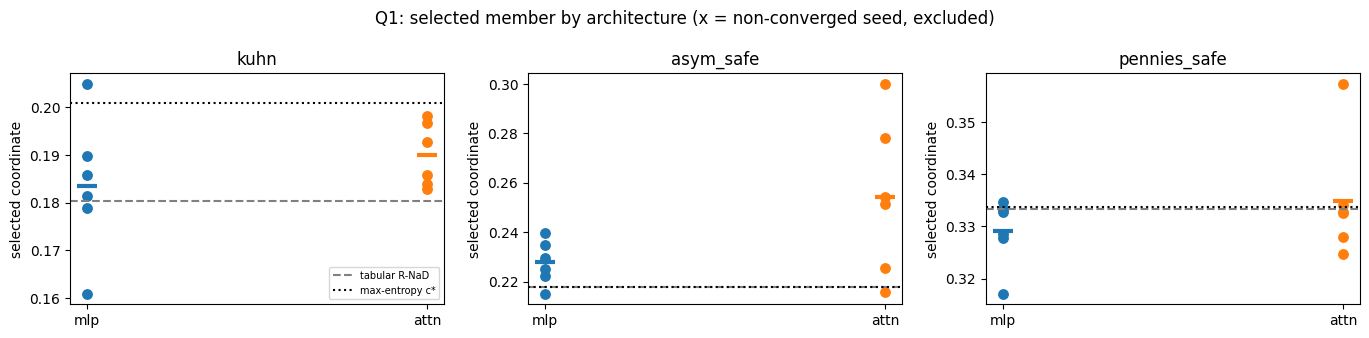

In [18]:
# Fig 1: selected coordinate by architecture (x = non-converged seed, excluded from mean)
fig,axes=plt.subplots(1,len(SEL_GAMES),figsize=(4.6*len(SEL_GAMES),3.4)); axes=np.atleast_1d(axes)
for ax,name in zip(axes,SEL_GAMES):
    for j,a in enumerate(ARCH):
        c=agg(a,name,"coord"); e=agg(a,name,"exploit"); cv=e<CONV
        if cv.any(): ax.scatter(np.full(cv.sum(),j),c[cv],s=46,color=f"C{j}")
        if (~cv).any(): ax.scatter(np.full((~cv).sum(),j),c[~cv],s=60,marker="x",color=f"C{j}")
        if cv.any(): ax.scatter([j],[c[cv].mean()],s=200,marker="_",color=f"C{j}",lw=3)
    ax.axhline(GT[name]["coord_tab"],ls="--",c="gray",label="tabular R-NaD")
    ax.axhline(GT[name]["cstar"],ls=":",c="k",label="max-entropy c*")
    ax.set_xticks(range(len(ARCH))); ax.set_xticklabels(ARCH); ax.set_title(name); ax.set_ylabel("selected coordinate")
axes[0].legend(fontsize=7); plt.suptitle("Q1: selected member by architecture (x = non-converged seed, excluded)")
plt.tight_layout(); plt.savefig("fig1_selection.png",dpi=110); plt.show()

## 3b · Q1 corrected inference (primary endpoint)

Point estimate, interval, test, and a separate **equivalence** test. "We failed to reject a
difference" and "we demonstrated the difference is small" are different claims and only the
second licenses the word *invariant* — the old two-outcome rule collapsed them.

Bootstrap intervals are reported alongside Welch because the selection coordinate is bounded
(the Nash family has a finite coordinate range) and can be skewed near the boundary, which is
exactly where a t-interval is least trustworthy.

In [19]:
def gated(a, name, key="coord", thresh=None):
    """Convergence-gated per-seed values. Gating is on best-iterate exploitability."""
    th = CONV if thresh is None else thresh
    c = np.array([RES[(a, name, s)][key] for s in SEEDS])
    e = np.array([RES[(a, name, s)]["exploit"] for s in SEEDS])
    ok = np.array([RES[(a, name, s)].get("numeric_ok", True) for s in SEEDS])
    return c[(e < th) & ok]

print("Q1 PRIMARY + SECONDARY INFERENCE   (gated at exploit<%.2f, pre-registered margin +-%.3f)\n" % (CONV, MARGIN))
hdr = "%-13s %-8s %-9s %-20s %-8s %-20s %-7s %-8s %s"
print(hdr % ("game","n(m,a)","diff","Welch 95% CI","p","bootstrap 95% CI","g","TOST p","verdict"))
_p_primary, _rows = [], []
for name in SEL_GAMES:
    cm, ca = gated("mlp", name), gated("attn", name)
    if len(cm) < 2 or len(ca) < 2:
        print("%-13s under-powered (n=%d,%d)" % (name, len(cm), len(ca))); continue
    w = sst.welch(cm, ca); bl, bh = sst.boot_ci(cm, ca)
    g = sst.hedges_g(cm, ca); t = sst.tost(cm, ca, MARGIN)
    v = sst.verdict(cm, ca, MARGIN)
    _p_primary.append(w["p"]); _rows.append(name)
    print(hdr % (name, "(%d,%d)" % (len(cm), len(ca)), "%+.4f" % w["diff"],
                 "[%+.4f,%+.4f]" % (w["lo"], w["hi"]), "%.3f" % w["p"],
                 "[%+.4f,%+.4f]" % (bl, bh), "%+.2f" % g, "%.3f" % t["p"], v))
if _p_primary:
    print("\nHolm-adjusted Welch p across games:",
          {n: round(float(a), 3) for n, a in zip(_rows, sst.holm(_p_primary))})
print("\nFor contrast, the RETIRED rule (effect > 2*seed_sd) would have returned:")
for name in SEL_GAMES:
    cm, ca = gated("mlp", name), gated("attn", name)
    if len(cm) < 2 or len(ca) < 2: continue
    eff = abs(cm.mean()-ca.mean()); noise = max(cm.std(), ca.std(), 0.005)
    print("   %-13s eff=%.4f vs threshold 2*sd=%.4f  ->  %s"
          % (name, eff, 2*noise, "dependent" if eff > 2*noise else "INVARIANT"))
print("\nThe retired rule used sd where the standard error sqrt(sd_m^2/n_m + sd_a^2/n_a) belongs;")
print("at n=10 that is a ~3.2x inflation of the acceptance threshold.")


Q1 PRIMARY + SECONDARY INFERENCE   (gated at exploit<0.02, pre-registered margin +-0.010)

game          n(m,a)   diff      Welch 95% CI         p        bootstrap 95% CI     g       TOST p   verdict
kuhn          (6,6)    +0.0065   [-0.0089,+0.0218]    0.352    [-0.0050,+0.0181]    +0.53   0.302    INCONCLUSIVE (neither difference nor equivalence established)
asym_safe     (6,6)    +0.0264   [-0.0066,+0.0595]    0.097    [+0.0032,+0.0505]    +1.05   0.866    INCONCLUSIVE (neither difference nor equivalence established)
pennies_safe  (6,6)    +0.0058   [-0.0067,+0.0183]    0.313    [-0.0025,+0.0165]    +0.57   0.230    INCONCLUSIVE (neither difference nor equivalence established)

Holm-adjusted Welch p across games: {'kuhn': 0.626, 'asym_safe': 0.292, 'pennies_safe': 0.626}

For contrast, the RETIRED rule (effect > 2*seed_sd) would have returned:
   kuhn          eff=0.0065 vs threshold 2*sd=0.0263  ->  INVARIANT
   asym_safe     eff=0.0264 vs threshold 2*sd=0.0576  ->  INVARIANT
   pe

### Margin sensitivity (declared secondary)

The pre-registered margin is a judgement, so the verdict is reported across the whole
defensible interval. `0.005` is disqualified as a floor (1.1x the instrument's own resolution)
and `0.020` as a ceiling (an effect at that margin would cost 97% of the intrinsic tabular
shortfall). Reporting the sweep answers "why not 0.005 or 0.02?" with evidence rather than
assertion.

In [20]:
print("Verdict vs equivalence margin (secondary; pre-registered margin marked *)\n")
print("%-13s" % "game" + "".join("%16s" % ("*%.4f" % m if abs(m-MARGIN) < 1e-9 else "%.4f" % m)
                                 for m in PREREG["secondary"]["margin_sensitivity"]))
for name in SEL_GAMES:
    cm, ca = gated("mlp", name), gated("attn", name)
    if len(cm) < 2 or len(ca) < 2: continue
    cells = []
    for m in PREREG["secondary"]["margin_sensitivity"]:
        v = sst.verdict(cm, ca, m)
        cells.append("%16s" % v.split(" ")[0][:15])
    print("%-13s" % name + "".join(cells))
print("\nA flat row of INCONCLUSIVE means the choice of margin is currently inert:")
print("no margin in the defensible range yields equivalence at this sample size.")


Verdict vs equivalence margin (secondary; pre-registered margin marked *)

game                   0.0050          0.0075         *0.0100          0.0150          0.0200
kuhn             INCONCLUSIVE    INCONCLUSIVE    INCONCLUSIVE    INCONCLUSIVE      EQUIVALENT
asym_safe        INCONCLUSIVE    INCONCLUSIVE    INCONCLUSIVE    INCONCLUSIVE    INCONCLUSIVE
pennies_safe     INCONCLUSIVE    INCONCLUSIVE    INCONCLUSIVE    INCONCLUSIVE      EQUIVALENT

A flat row of INCONCLUSIVE means the choice of margin is currently inert:
no margin in the defensible range yields equivalence at this sample size.


## 3c · Best-iterate bias, measured rather than asserted

`nbn.train` reports the lowest-exploitability iterate out of ~60 sampled evaluations. A
minimum of N draws is biased low, and **more so for noisier runs** — which is the arm under
test. It was previously argued that this biases Q1 toward the null by preferentially rescuing
attention's excursions toward the manifold; that was a claim about a mechanism, not a
measurement. Whether it holds depends on whether the seed noise lives in the exploitability or
in the coordinate, so the cell below measures the sign and size per architecture.

In [21]:
# EXPLORATORY TIER (n=%d seeds) -- illustrative only.
# The confirmatory version of this analysis is in section B6, on n=150/arm.
print("Selection coordinate read three ways (Kuhn, all seeds)\n")
print("%-6s %-9s %-9s %-9s %-11s %-11s %s" % ("arch","best","final","late-20%","|best-final|","best exploit","final exploit"))
_bias = {}
for a in ARCH:
    cb = np.array([RES[(a,"kuhn",s)]["coord"] for s in SEEDS])
    cf = np.array([RES[(a,"kuhn",s)].get("coord_final", np.nan) for s in SEEDS])
    cl = np.array([RES[(a,"kuhn",s)].get("coord_late",  np.nan) for s in SEEDS])
    eb = np.array([RES[(a,"kuhn",s)]["exploit"] for s in SEEDS])
    ef = np.array([RES[(a,"kuhn",s)]["final_exploit"] for s in SEEDS])
    _bias[a] = (cb, cf, cl)
    print("%-6s %-9.4f %-9.4f %-9.4f %-11.4f %-11.5f %.5f"
          % (a, cb.mean(), np.nanmean(cf), np.nanmean(cl),
             np.nanmean(np.abs(cb-cf)), np.median(eb), np.median(ef)))
if "mlp" in _bias and "attn" in _bias:
    print("\nOptimism of best-iterate SELECTION vs final-iterate, per arm:")
    for a in ARCH:
        cb, cf, _ = _bias[a]
        d = cb - cf
        print("   %-5s mean shift %+.4f (sd %.4f)" % (a, np.nanmean(d), np.nanstd(d)))
    print("\nExploitability optimism (best is a minimum of ~60 evaluations, so it must be <= final):")
    for a in ARCH:
        eb = np.array([RES[(a,"kuhn",s)]["exploit"] for s in SEEDS])
        ef = np.array([RES[(a,"kuhn",s)]["final_exploit"] for s in SEEDS])
        print("   %-5s median best %.5f vs final %.5f  (ratio %.2fx)"
              % (a, np.median(eb), np.median(ef), np.median(ef)/max(np.median(eb),1e-12)))
    dm = _bias["mlp"][0]-_bias["mlp"][1]; da = _bias["attn"][0]-_bias["attn"][1]
    w = sst.welch(dm[~np.isnan(dm)], da[~np.isnan(da)])
    print("\nIs the coordinate-level bias LARGER for attention? diff=%+.4f, 95%% CI [%+.4f,%+.4f], p=%.3f"
          % (w["diff"], w["lo"], w["hi"], w["p"]))
    print("If this interval covers 0, the 'best-iterate rescues the noisier arm' argument is")
    print("not supported at the coordinate level and should not be claimed in the paper.")


Selection coordinate read three ways (Kuhn, all seeds)

arch   best      final     late-20%  |best-final| best exploit final exploit
mlp    0.1836    0.1809    0.1827    0.0050      0.00157     0.00369
attn   0.1900    0.1900    0.1938    0.0151      0.00172     0.01639

Optimism of best-iterate SELECTION vs final-iterate, per arm:
   mlp   mean shift +0.0026 (sd 0.0047)
   attn  mean shift +0.0000 (sd 0.0200)

Exploitability optimism (best is a minimum of ~60 evaluations, so it must be <= final):
   mlp   median best 0.00157 vs final 0.00369  (ratio 2.34x)
   attn  median best 0.00172 vs final 0.01639  (ratio 9.54x)

Is the coordinate-level bias LARGER for attention? diff=-0.0026, 95% CI [-0.0255,+0.0203], p=0.787
If this interval covers 0, the 'best-iterate rescues the noisier arm' argument is
not supported at the coordinate level and should not be claimed in the paper.


### Coordinate read-off vs projection

The appendix previously described the selection coordinate as "the projection of the converged
policy onto the analytic Nash family", but the code read a single component of `sigma` (for
Kuhn, `P(bet|Jack)`) and ignored the family's other constraints. For a policy that is not
exactly on the manifold those disagree. `sst.project_coord` implements the stated definition;
both are reported so the change is auditable.

In [22]:
# EXPLORATORY TIER (n=%d seeds) -- illustrative only.
# The confirmatory version of this analysis is in section B6, on n=150/arm.
fam_kuhn = FAM["kuhn"][1]; g_kuhn = FAM["kuhn"][0]
print("read-off vs least-squares projection (Kuhn)\n")
print("%-6s %-6s %-10s %-11s %-9s %-16s %s" % ("arch","seed","read-off","projected","|diff|","off-family dist","exploit"))
_ro, _pr = {a: [] for a in ARCH}, {a: [] for a in ARCH}
for a in ARCH:
    for s in SEEDS:
        r = RES[(a,"kuhn",s)]
        cp, res = sst.project_coord(fam_kuhn, 0.0, 1/3, r["sigma"], g_kuhn)
        _ro[a].append(r["coord"]); _pr[a].append(cp)
        if s < 3:
            print("%-6s %-6d %-10.4f %-11.4f %-9.4f %-16.4f %.5f"
                  % (a, s, r["coord"], cp, abs(cp-r["coord"]), res, r["exploit"]))
print("\nmean |read-off - projection| per arm:")
for a in ARCH:
    print("   %-5s %.4f" % (a, np.mean(np.abs(np.array(_ro[a])-np.array(_pr[a])))))
print("\nPrimary endpoint recomputed on the PROJECTED coordinate:")
if "mlp" in ARCH and "attn" in ARCH:
    em = np.array([RES[("mlp","kuhn",s)]["exploit"] for s in SEEDS])
    ea = np.array([RES[("attn","kuhn",s)]["exploit"] for s in SEEDS])
    pm = np.array(_pr["mlp"])[em < CONV]; pa = np.array(_pr["attn"])[ea < CONV]
    w = sst.welch(pm, pa); t = sst.tost(pm, pa, MARGIN)
    print("   diff=%+.4f  95%% CI [%+.4f,%+.4f]  p=%.3f  TOST p=%.3f  ->  %s"
          % (w["diff"], w["lo"], w["hi"], w["p"], t["p"], sst.verdict(pm, pa, MARGIN)))


read-off vs least-squares projection (Kuhn)

arch   seed   read-off   projected   |diff|    off-family dist  exploit
mlp    0      0.1897     0.1908      0.0012    0.0063           0.00153
mlp    1      0.1789     0.1795      0.0006    0.0110           0.00261
mlp    2      0.1609     0.1605      0.0004    0.0014           0.00045
attn   0      0.1857     0.1812      0.0045    0.0287           0.00680
attn   1      0.1981     0.2025      0.0044    0.0108           0.00225
attn   2      0.1840     0.1853      0.0013    0.0040           0.00106

mean |read-off - projection| per arm:
   mlp   0.0007
   attn  0.0033

Primary endpoint recomputed on the PROJECTED coordinate:
   diff=+0.0072  95% CI [-0.0094,+0.0237]  p=0.352  TOST p=0.353  ->  INCONCLUSIVE (neither difference nor equivalence established)


## 4 · Convergence entanglement (methodological control)

Selection cannot be read off an under-converged model: the along-manifold coordinate only settles as
the transverse exploitability -> 0. The training trajectory of (exploitability, coordinate) shows the
coordinate wandering while exploitability is high and stabilizing near the tabular value only as the
agent reaches the manifold. This is why section 3 gates on convergence, and it is the on/off-manifold
story of Q3 in motion.

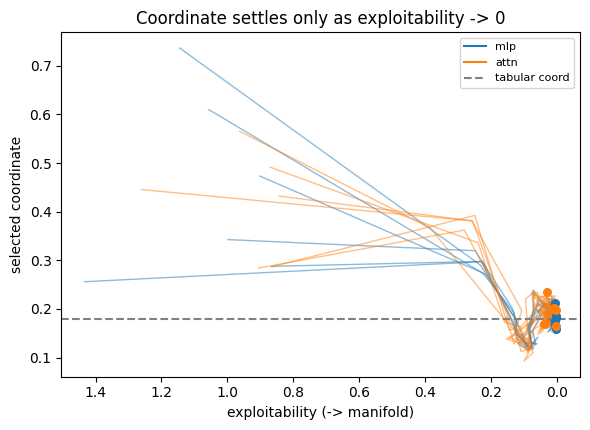

In [23]:
plt.figure(figsize=(6,4.4))
for j,a in enumerate(ARCH):
    for s in SEEDS:
        tr=RES[(a,"kuhn",s)]["traj"]   # cols: t, exploit, H, coord
        plt.plot(tr[:,1],tr[:,3],alpha=.5,color=f"C{j}",lw=1)
        plt.scatter(tr[-1,1],tr[-1,3],color=f"C{j}",s=30,zorder=3)
    plt.plot([],[],color=f"C{j}",label=a)
plt.axhline(GT["kuhn"]["coord_tab"],ls="--",c="gray",label="tabular coord")
plt.gca().invert_xaxis(); plt.xlabel("exploitability (-> manifold)"); plt.ylabel("selected coordinate")
plt.title("Coordinate settles only as exploitability -> 0"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig2_entanglement.png",dpi=110); plt.show()

## 5 · Q2 — Stability: the magnet sweep per architecture

Sweep magnet strength `eta` (`CFG["etas"]`) on Kuhn for each architecture; record convergence rate,
final exploitability, and `delta_excess`. Locates the stability floor per architecture and tests
whether the backbone moves the bias-vs-stability frontier. *Stability here uses the **final-iterate** exploitability (did the run STAY converged), distinct from the best-iterate value used for selection.*

In [24]:
ETAS=CFG["etas"]; SW_SEEDS=sub(CFG["eta_seeds"]); kuhn=efg.GAMES["kuhn"]
SW={}
for a in ARCH:
    for eta in ETAS:
        for s in SW_SEEDS:
            r=run(a,kuhn,seed=s,eta=eta)
            r["delta_excess"]=(GT["kuhn"]["Hmax"]-r["entropy"])-dtab(kuhn,eta,GT["kuhn"]["Hmax"])[0]
            SW[(a,eta,s)]=r
print("arch  eta   conv%%   exploit(med)  coord(mean)")
for a in ARCH:
    for eta in ETAS:
        e=np.array([SW[(a,eta,s)]["final_exploit"] for s in SW_SEEDS]); c=np.array([SW[(a,eta,s)]["coord"] for s in SW_SEEDS])
        print("%-4s  %.2f  %3.0f    %.4f       %.3f"%(a,eta,100*(e<CONV).mean(),np.median(e),c.mean()))

arch  eta   conv%%   exploit(med)  coord(mean)
mlp   0.80  100    0.0040       0.180
mlp   0.50  100    0.0037       0.184
mlp   0.30   75    0.0070       0.125
mlp   0.15  100    0.0039       0.017
attn  0.80  100    0.0050       0.195
attn  0.50   25    0.0307       0.190
attn  0.30   25    0.0386       0.142
attn  0.15   25    0.1724       0.184


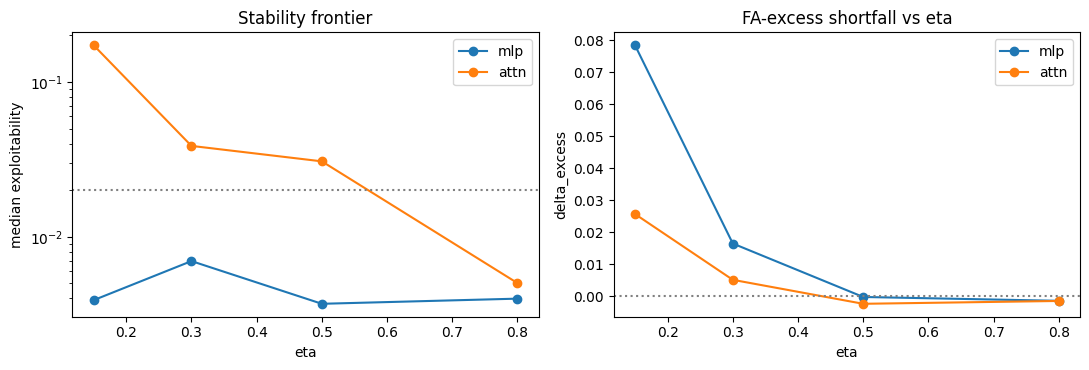

In [25]:
fig,ax=plt.subplots(1,2,figsize=(11,3.8))
for j,a in enumerate(ARCH):
    me=[np.median([SW[(a,eta,s)]["final_exploit"] for s in SW_SEEDS]) for eta in ETAS]
    de=[np.mean([SW[(a,eta,s)]["delta_excess"] for s in SW_SEEDS]) for eta in ETAS]
    ax[0].plot(ETAS,me,"o-",label=a,color=f"C{j}"); ax[1].plot(ETAS,de,"o-",label=a,color=f"C{j}")
ax[0].axhline(CONV,ls=":",c="gray"); ax[0].set_xlabel("eta"); ax[0].set_ylabel("median exploitability")
ax[0].set_title("Stability frontier"); ax[0].set_yscale("log"); ax[0].legend()
ax[1].axhline(0,ls=":",c="gray"); ax[1].set_xlabel("eta"); ax[1].set_ylabel("delta_excess"); ax[1].set_title("FA-excess shortfall vs eta"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig3_stability.png",dpi=110); plt.show()

## 6 · Entropy shortfall under function approximation: the overshoot

**This section replaces the earlier "does the curvature law survive function approximation?"
test, which was vacuous as implemented.** That test compared the measured along-manifold gap
against `sqrt(2*delta/kappa)` — but computed the prediction as `sqrt(max(2*delta/kappa, 0))`,
and a majority of near-manifold runs have `delta < 0`. For those the prediction was silently
clamped to zero, so the reported residual was simply the raw coordinate gap, not a test of the
law. The law itself is established exactly in the tabular regime by Leal (2026b), where the
pipeline is deterministic and the fit recovers the 1/2 exponent to four digits; nothing here
disputes that.

What function approximation produces instead is a negative shortfall: the fitted policy's mean
information-set entropy can **exceed** the maximum attainable *on* the Nash family, because the
policy sits slightly off the manifold where that bound does not apply. `delta < 0` is the
majority case on Kuhn at this budget.

**This was initially proposed as a phenomenon in its own right. Section B4 tests that and
refutes it** — the overshoot anneals away monotonically with training length, so it is
under-training rather than a property of function approximation. The section is retained
because the measurement is real and because it explains why the retired gap-law analysis was
clamping most of its predictions to zero; but nothing is claimed from it. See B4.

In [26]:
print("Entropy shortfall delta = H* - H(sigma) on near-manifold runs (exploit < %.3f)\n" % NEAR)
print("%-13s %-6s %-4s %-13s %-15s %s" % ("game","arch","n","mean delta","frac(delta<0)","mean |c-c*|"))
_tot = _neg = 0
for name in SEL_GAMES:
    for a in ARCH:
        e = np.array([RES[(a,name,s)]["exploit"] for s in SEEDS])
        H = np.array([RES[(a,name,s)]["entropy"] for s in SEEDS])
        c = np.array([RES[(a,name,s)]["coord"] for s in SEEDS])
        m = e < NEAR
        if m.sum() == 0: continue
        d = GT[name]["Hmax"] - H[m]
        _tot += int(m.sum()); _neg += int((d < 0).sum())
        print("%-13s %-6s %-4d %+13.5f %14.0f%% %11.4f"
              % (name, a, m.sum(), d.mean(), 100*(d < 0).mean(),
                 np.abs(c[m]-GT[name]["cstar"]).mean()))
print("\nOverall: %d/%d near-manifold runs (%.0f%%) have delta < 0." % (_neg, _tot, 100*_neg/max(_tot,1)))
print("For those runs sqrt(2*delta/kappa) is undefined. The retired analysis clamped the")
print("prediction to 0, so its reported residual was the raw along-manifold gap, not a test.")

# Is the overshoot explained by distance off the manifold?
_pos, _neg_e = [], []
for a in ARCH:
    for s in SEEDS:
        r = RES[(a,"kuhn",s)]
        if r["exploit"] < NEAR:
            (_neg_e if GT["kuhn"]["Hmax"]-r["entropy"] < 0 else _pos).append(r["exploit"])
if len(_pos) > 1 and len(_neg_e) > 1:
    w = sst.welch(np.array(_pos), np.array(_neg_e))
    print("\nOvershooting vs non-overshooting runs, exploitability (Kuhn):")
    print("   overshoot (delta<0): n=%d median %.5f" % (len(_neg_e), np.median(_neg_e)))
    print("   no overshoot      : n=%d median %.5f" % (len(_pos), np.median(_pos)))
    print("   Welch p=%.3f -> %s" % (w["p"], "differ" if w["p"] < .05 else
          "not distinguishable by residual exploitability alone"))


Entropy shortfall delta = H* - H(sigma) on near-manifold runs (exploit < 0.025)

game          arch   n    mean delta    frac(delta<0)   mean |c-c*|
kuhn          mlp    6         +0.00034             50%      0.0186
kuhn          attn   6         -0.00140            100%      0.0108
asym_safe     mlp    6         +0.00163              0%      0.0108
asym_safe     attn   6         +0.02470              0%      0.0370
pennies_safe  mlp    6         +0.00006             17%      0.0050
pennies_safe  attn   6         +0.00013              0%      0.0068

Overall: 10/36 near-manifold runs (28%) have delta < 0.
For those runs sqrt(2*delta/kappa) is undefined. The retired analysis clamped the
prediction to 0, so its reported residual was the raw along-manifold gap, not a test.

Overshooting vs non-overshooting runs, exploitability (Kuhn):
   overshoot (delta<0): n=9 median 0.00153
   no overshoot      : n=3 median 0.00198
   Welch p=0.685 -> not distinguishable by residual exploitability alo

### Function approximation manufactures entropy shortfall where the exact solver has none

Leal (2026b) reports that on the matrix games the tabular solver reaches the maximum-entropy
member exactly (`delta ~ 0`), so there is no gap to explain there. Under function approximation
that is no longer true. Because the tabular reference is **deterministic** — the engine's
`rng` is never consumed by `efg.train`, and tabular runs are bit-identical across seeds — this
comparison is a *one-sample* test against a constant, which is far better powered than the
between-architecture contrast and does not depend on the architecture axis at all.

In [27]:
from scipy import stats as _st
print("Excess entropy shortfall of FA vs the deterministic tabular reference\n")
print("%-13s %-6s %-4s %-12s %-20s %-8s %s" % ("game","arch","n","mean d_exc","95% CI","p","vs delta_tab"))
for name in SEL_GAMES:
    for a in ARCH:
        e  = np.array([RES[(a,name,s)]["exploit"] for s in SEEDS])
        dx = np.array([RES[(a,name,s)]["delta_excess"] for s in SEEDS])[e < CONV]
        if len(dx) < 2: continue
        se = dx.std(ddof=1)/np.sqrt(len(dx)); crit = _st.t.ppf(.975, len(dx)-1)
        t, p = _st.ttest_1samp(dx, 0.0)
        print("%-13s %-6s %-4d %+12.5f [%+.5f,%+.5f] %8.4f  %.2fx"
              % (name, a, len(dx), dx.mean(), dx.mean()-crit*se, dx.mean()+crit*se, p,
                 dx.mean()/GT[name]["delta_tab"] if GT[name]["delta_tab"] > 1e-9 else float("inf")))
print("\nPositive and significant => the network gives up entropy the exact solver does not.")
print("This is a function-approximation effect, not an attention effect: it is measured")
print("against the table, and on the matrix games the 'attention' arm contains no attention")
print("(see the tokenizer diagnostic).")


Excess entropy shortfall of FA vs the deterministic tabular reference

game          arch   n    mean d_exc   95% CI               p        vs delta_tab
kuhn          mlp    6        -0.00050 [-0.00194,+0.00094]   0.4159  -0.60x
kuhn          attn   6        -0.00223 [-0.00352,-0.00095]   0.0067  -2.68x
asym_safe     mlp    6        +0.00163 [-0.00033,+0.00359]   0.0853  infx
asym_safe     attn   6        +0.02470 [-0.00839,+0.05778]   0.1131  infx
pennies_safe  mlp    6        +0.00006 [-0.00006,+0.00018]   0.2664  infx
pennies_safe  attn   6        +0.00013 [-0.00014,+0.00039]   0.2766  infx

Positive and significant => the network gives up entropy the exact solver does not.
This is a function-approximation effect, not an attention effect: it is measured
against the table, and on the matrix games the 'attention' arm contains no attention
(see the tokenizer diagnostic).


## 7 · Solver comparison: R-NaD vs NashPG

Same architecture contrast under each solver in `CFG["solvers"]` — R-NaD (reference reset, moderate
eta) and NashPG (reference refinement, large fixed eta, no annealing). Tests whether any architecture
effect is solver-dependent.

In [28]:
SOLV_SEEDS=sub(CFG["solver_seeds"]); kuhn=efg.GAMES["kuhn"]
SOLVER_KW={"rnad":dict(solver="rnad",eta=0.5),
           "nashpg":dict(solver="nashpg",eta=0.7,iters=CFG["iters"]["nashpg"])}
SOL={}
for a in ARCH:
    for sv in CFG["solvers"]:
        for s in SOLV_SEEDS:
            SOL[(a,sv,s)]=run(a,kuhn,seed=s,**SOLVER_KW[sv])
print("arch  solver   coord(mean+-sd)   exploit(med)")
for a in ARCH:
    for sv in CFG["solvers"]:
        c=np.array([SOL[(a,sv,s)]["coord"] for s in SOLV_SEEDS]); e=np.array([SOL[(a,sv,s)]["exploit"] for s in SOLV_SEEDS])
        print("%-4s  %-6s   %.3f +- %.3f    %.4f"%(a,sv,c.mean(),c.std(),np.median(e)))

arch  solver   coord(mean+-sd)   exploit(med)
mlp   rnad     0.184 +- 0.016    0.0016
mlp   nashpg   0.195 +- 0.010    0.0023
attn  rnad     0.190 +- 0.006    0.0024
attn  nashpg   0.168 +- 0.026    0.0028


## 8 · Ablations

Each ablation in `CFG["ablations"]` isolates one mechanism on Kuhn: **activation softness** (soft
tanh/softmax vs hard ReLU/sharpened-attention — the direct smoothness test), **token typing** (typed
vs untyped tokens), **masking** (attention causal vs full).

In [29]:
AB_SEEDS=sub(CFG["ablation_seeds"]); g=efg.GAMES["kuhn"]; rows=[]
if "activation" in CFG["ablations"]:
    for a in ARCH:
        for soft in [True,False]:
            c=[];e=[]
            for s in AB_SEEDS:
                r=run(a,g,seed=s,soft=soft); c.append(r["coord"]); e.append(r["exploit"])
            rows.append(("activation",f"{a}-{'soft' if soft else 'hard'}",np.mean(c),np.std(c),np.median(e)))
if "typing" in CFG["ablations"]:
    for a in ARCH:
        for typed in [True,False]:
            c=[];e=[]
            for s in AB_SEEDS:
                r=run(a,g,seed=s,typed=typed); c.append(r["coord"]); e.append(r["exploit"])
            rows.append(("typing",f"{a}-{'typed' if typed else 'untyped'}",np.mean(c),np.std(c),np.median(e)))
if "masking" in CFG["ablations"]:
    for causal in [False,True]:
        c=[];e=[]
        for s in AB_SEEDS:
            r=run("attn",g,seed=s,causal=causal); c.append(r["coord"]); e.append(r["exploit"])
        rows.append(("masking",f"attn-{'causal' if causal else 'full'}",np.mean(c),np.std(c),np.median(e)))
print("%-11s %-14s %-16s %s"%("ablation","condition","coord(mean+-sd)","exploit(med)"))
for ab,cond,cm,cs,em in rows: print("%-11s %-14s %.3f +- %.3f      %.4f"%(ab,cond,cm,cs,em))
ABL=rows

ablation    condition      coord(mean+-sd)  exploit(med)
activation  mlp-soft       0.184 +- 0.016      0.0016
activation  mlp-hard       0.192 +- 0.048      0.0020
activation  attn-soft      0.190 +- 0.006      0.0024
activation  attn-hard      0.160 +- 0.029      0.0031
typing      mlp-typed      0.184 +- 0.016      0.0016
typing      mlp-untyped    0.184 +- 0.009      0.0012
typing      attn-typed     0.190 +- 0.006      0.0024
typing      attn-untyped   0.122 +- 0.055      0.0427
masking     attn-full      0.190 +- 0.006      0.0024
masking     attn-causal    0.191 +- 0.035      0.0022


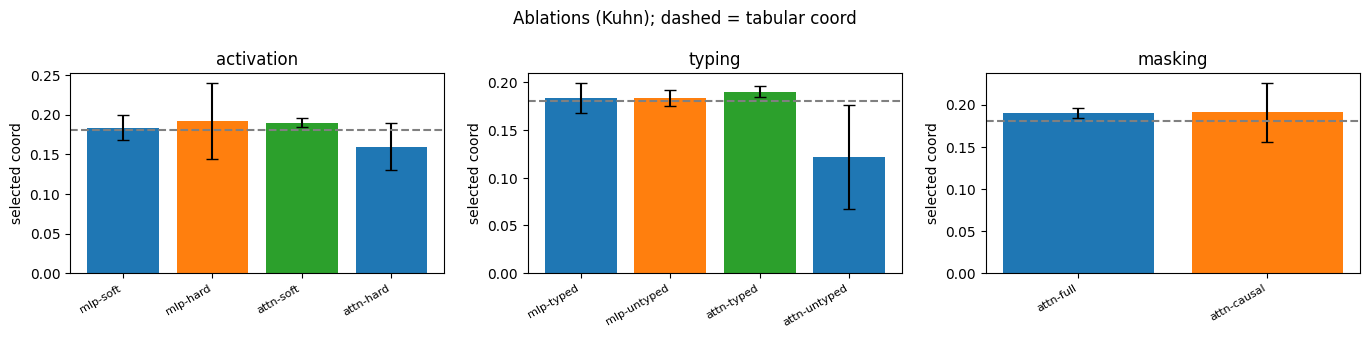

In [30]:
groups={}
for ab,cond,cm,cs,em in ABL: groups.setdefault(ab,[]).append((cond,cm,cs))
if groups:
    fig,axes=plt.subplots(1,len(groups),figsize=(4.6*len(groups),3.4)); axes=np.atleast_1d(axes)
    for ax,(ab,items) in zip(axes,groups.items()):
        labels=[i[0] for i in items]; means=[i[1] for i in items]; sds=[i[2] for i in items]
        ax.bar(range(len(labels)),means,yerr=sds,capsize=4,color=[f"C{k%3}" for k in range(len(labels))])
        ax.axhline(GT["kuhn"]["coord_tab"],ls="--",c="gray")
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels,rotation=30,ha="right",fontsize=8)
        ax.set_title(ab); ax.set_ylabel("selected coord")
    plt.suptitle("Ablations (Kuhn); dashed = tabular coord"); plt.tight_layout()
    plt.savefig("fig5_ablations.png",dpi=110); plt.show()

## 9 · Capacity scaling

Does any architecture effect persist or vanish as capacity grows? Sweep hidden size
(`CFG["scaling_sizes"]`) per architecture.

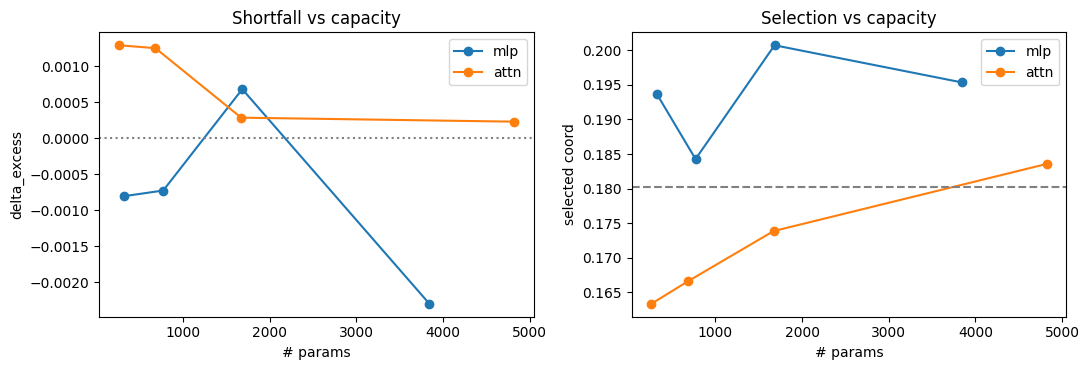

mlp params: [322, 770, 1682, 3842]
attn params: [260, 680, 1670, 4822]


In [31]:
SC_SEEDS=sub(CFG["scaling_seeds"]); SIZES=CFG["scaling_sizes"]; g=efg.GAMES["kuhn"]; SC={}
for a in ARCH:
    for (h,d) in SIZES:
        for s in SC_SEEDS:
            kw=dict(h=h) if a=="mlp" else dict(h=h,d=d)
            r=run(a,g,seed=s,**kw); r["delta_excess"]=(GT["kuhn"]["Hmax"]-r["entropy"])-GT["kuhn"]["delta_tab"]
            SC[(a,h,s)]=r
fig,ax=plt.subplots(1,2,figsize=(11,3.8))
for j,a in enumerate(ARCH):
    P=[np.mean([SC[(a,h,s)]["nparams"] for s in SC_SEEDS]) for (h,d) in SIZES]
    DE=[np.mean([SC[(a,h,s)]["delta_excess"] for s in SC_SEEDS]) for (h,d) in SIZES]
    CO=[np.mean([SC[(a,h,s)]["coord"] for s in SC_SEEDS]) for (h,d) in SIZES]
    ax[0].plot(P,DE,"o-",label=a,color=f"C{j}"); ax[1].plot(P,CO,"o-",label=a,color=f"C{j}")
ax[0].set_xlabel("# params"); ax[0].set_ylabel("delta_excess"); ax[0].set_title("Shortfall vs capacity"); ax[0].axhline(0,ls=":",c="gray"); ax[0].legend()
ax[1].set_xlabel("# params"); ax[1].set_ylabel("selected coord"); ax[1].set_title("Selection vs capacity")
ax[1].axhline(GT["kuhn"]["coord_tab"],ls="--",c="gray"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig6_scaling.png",dpi=110); plt.show()
for a in ARCH: print(a,"params:",[int(np.mean([SC[(a,h,s)]["nparams"] for s in SC_SEEDS])) for (h,d) in SIZES])

## 10 · Q4 — Off-equilibrium robustness and mediation

Freeze each converged Kuhn agent (player 0); measure its value against fixed non-equilibrium
opponents (over-fold, over-call, random) plus an exact best response. Then test **mediation**: is
robustness explained by the selected coordinate (a selection effect) rather than representation?

agent           over_fold  over_call  random    BR(worst)
tabular-MaxEnt  +0.1339   +0.1111   +0.1603   -0.0556
mlp#0           +0.1265   +0.1122   +0.1530   -0.0561
mlp#1           +0.1193   +0.1130   +0.1453   -0.0565
mlp#2           +0.1073   +0.1111   +0.1320   -0.0558
mlp#3           +0.1370   +0.1115   +0.1640   -0.0558
mlp#4           +0.1209   +0.1105   +0.1463   -0.0562
mlp#5           +0.1243   +0.1113   +0.1507   -0.0561
attn#0          +0.1243   +0.1099   +0.1486   -0.0576
attn#1          +0.1323   +0.1128   +0.1604   -0.0564
attn#2          +0.1233   +0.1116   +0.1498   -0.0561
attn#3          +0.1292   +0.1141   +0.1584   -0.0572
attn#4          +0.1312   +0.1110   +0.1575   -0.0557
attn#5          +0.1231   +0.1107   +0.1486   -0.0566


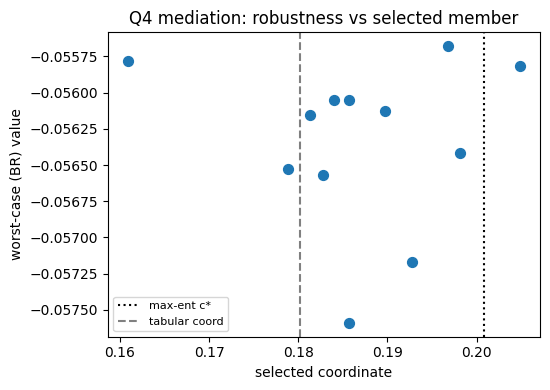

corr(coord, worst-case value) = -0.029


In [32]:
opps=nbn.kuhn_fixed_opponents(); g=efg.GAMES["kuhn"]
me_sigma=efg.kuhn_family_strategy(GT["kuhn"]["cstar"])
def eval_robust(sig):
    out={}
    for nm,opp in opps.items():
        s=dict(sig); s.update(opp); out[nm]=float(efg.value(g,s))
    br=efg.best_response_strategy(g,dict(sig),1); s=dict(sig); s.update(br); out["BR"]=float(efg.value(g,s))
    return out
print("agent           over_fold  over_call  random    BR(worst)")
coords=[]; worsts=[]
rows=[("tabular-MaxEnt",me_sigma,None)]
for a in ARCH:
    for s in SEEDS: rows.append((f"{a}#{s}",RES[(a,'kuhn',s)]["sigma"],RES[(a,'kuhn',s)]["coord"]))
for label,sig,co in rows:
    rb=eval_robust(sig); print("%-15s %+.4f   %+.4f   %+.4f   %+.4f"%(label,rb["over_fold"],rb["over_call"],rb["random"],rb["BR"]))
    if co is not None: coords.append(co); worsts.append(rb["BR"])
plt.figure(figsize=(5.6,4)); plt.scatter(coords,worsts,s=50,c="C0")
plt.axvline(GT["kuhn"]["cstar"],ls=":",c="k",label="max-ent c*"); plt.axvline(GT["kuhn"]["coord_tab"],ls="--",c="gray",label="tabular coord")
plt.xlabel("selected coordinate"); plt.ylabel("worst-case (BR) value"); plt.title("Q4 mediation: robustness vs selected member")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("fig7_robustness.png",dpi=110); plt.show()
MED_CORR=float(np.corrcoef(coords,worsts)[0,1]) if len(coords)>2 else float("nan")
if len(coords)>2: print("corr(coord, worst-case value) =",round(MED_CORR,3))

## 11 · Summary verdict (data-driven)

Computed directly from the results: the architecture effect on selection vs the seed-noise floor
(convergence- and power-gated), per-architecture convergence rates, and the gap-law residual.

In [33]:
print("="*72); print("VERDICT (computed from results above; pre-registered rule)"); print("="*72)
print("\nQ1 SELECTION — primary endpoint, TOST at pre-registered margin +-%.3f"%MARGIN)
have_both = ("mlp" in ARCH and "attn" in ARCH)
if not have_both:
    print("  (need both 'mlp' and 'attn' in CFG['arch'])")
else:
    _ps=[]; _ns=[]
    for name in SEL_GAMES:
        cm,ca = gated("mlp",name), gated("attn",name)
        if len(cm)<2 or len(ca)<2:
            print("  %-13s UNDER-POWERED (n=%d,%d)"%(name,len(cm),len(ca))); continue
        w=sst.welch(cm,ca); t=sst.tost(cm,ca,MARGIN); _ps.append(w["p"]); _ns.append(name)
        print("  %-13s diff=%+.4f 95%%CI[%+.4f,%+.4f] p=%.3f TOSTp=%.3f -> %s"
              %(name,w["diff"],w["lo"],w["hi"],w["p"],t["p"],sst.verdict(cm,ca,MARGIN)))
    if _ps:
        print("  Holm-adjusted:",{n:round(float(a),3) for n,a in zip(_ns,sst.holm(_ps))})
    print("\n  NOTE: INCONCLUSIVE means underpowered, NOT invariant. 'Invariant' is")
    print("  claimable only on an EQUIVALENT verdict.")
print("\nQ2 STABILITY — stayed-converged over the eta sweep (final-iterate)")
for a in ARCH:
    e=np.array([SW[(a,eta,s)]["final_exploit"] for eta in ETAS for s in SW_SEEDS])
    k=int((e<CONV).sum()); n=len(e); p=k/n
    lo,hi=sst.boot_ci(np.zeros(1),(e<CONV).astype(float),B=4000) if n>1 else (np.nan,np.nan)
    print("  %-5s %3d/%3d = %3.0f%%   median final-exploit=%.4f"%(a,k,n,100*p,np.median(e)))
if "mlp" in ARCH and "attn" in ARCH:
    em=np.array([SW[("mlp",eta,s)]["final_exploit"]<CONV for eta in ETAS for s in SW_SEEDS],float)
    ea=np.array([SW[("attn",eta,s)]["final_exploit"]<CONV for eta in ETAS for s in SW_SEEDS],float)
    w=sst.welch(ea,em)
    print("  difference (mlp-attn) = %+.3f, 95%% CI [%+.3f,%+.3f], p=%.4f"%(w["diff"],w["lo"],w["hi"],w["p"]))
    print("  CAVEAT: runs are clustered by seed and eta, so this interval is optimistic;")
    print("  and the arms use different learning rates. See the factorial for whether")
    print("  any gap is attributable to normalization rather than architecture.")
print("\nQ3 — see the overshoot section: the curvature law is NOT tested here.")
print("     The tabular law stands on Leal (2026b); FA produces delta<0, out of its scope.")
print("\nQ4 — mediation is underpowered BY CONSTRUCTION (see restriction-of-range note).")


VERDICT (computed from results above; pre-registered rule)

Q1 SELECTION — primary endpoint, TOST at pre-registered margin +-0.010
  kuhn          diff=+0.0065 95%CI[-0.0089,+0.0218] p=0.352 TOSTp=0.302 -> INCONCLUSIVE (neither difference nor equivalence established)
  asym_safe     diff=+0.0264 95%CI[-0.0066,+0.0595] p=0.097 TOSTp=0.866 -> INCONCLUSIVE (neither difference nor equivalence established)
  pennies_safe  diff=+0.0058 95%CI[-0.0067,+0.0183] p=0.313 TOSTp=0.230 -> INCONCLUSIVE (neither difference nor equivalence established)
  Holm-adjusted: {'kuhn': 0.626, 'asym_safe': 0.292, 'pennies_safe': 0.626}

  NOTE: INCONCLUSIVE means underpowered, NOT invariant. 'Invariant' is
  claimable only on an EQUIVALENT verdict.

Q2 STABILITY — stayed-converged over the eta sweep (final-iterate)
  mlp    15/ 16 =  94%   median final-exploit=0.0040
  attn    7/ 16 =  44%   median final-exploit=0.0307
  difference (mlp-attn) = +0.500, 95% CI [+0.204,+0.796], p=0.0020
  CAVEAT: runs are cluster

## 12 · Auto-generated conclusion (data-matched to the active preset)

The cell below writes the interpretation **from the results that actually ran** — so it stays
correct whether you used `quick`, `full`, or a custom config. Selection uses best-iterate
exploitability; stability uses final-iterate exploitability.

In [34]:
def _q1_verdict(name):
    """Four-way, pre-registered. Replaces the retired effect>2*sd rule."""
    cm_,ca_ = gated("mlp",name), gated("attn",name)
    if len(cm_)==0 or len(ca_)==0: return ("failure",None,None,len(cm_),len(ca_))
    if len(cm_)<2 or len(ca_)<2:  return ("under",None,None,len(cm_),len(ca_))
    w=sst.welch(cm_,ca_); t=sst.tost(cm_,ca_,MARGIN)
    tag=("different" if (w["p"]<.05 and t["p"]>=.05) else
         "equivalent" if (t["p"]<.05 and w["p"]>=.05) else
         "trivial"    if (t["p"]<.05 and w["p"]<.05) else "inconclusive")
    return (tag,w["diff"],(w["lo"],w["hi"]),len(cm_),len(ca_))

lines=[]; tags=[]
have=("mlp" in ARCH and "attn" in ARCH)
if have:
    for name in SEL_GAMES:
        tag,eff,noise,nm,na=_q1_verdict(name); tags.append(tag)
        if tag=="equivalent": lines.append("  - %-13s EQUIVALENT within +-%.3f: diff %+.4f, 95%%CI [%+.4f,%+.4f] (n=%d,%d)"%(name,MARGIN,eff,noise[0],noise[1],nm,na))
        elif tag=="different": lines.append("  - %-13s DIFFERENT: diff %+.4f, 95%%CI [%+.4f,%+.4f] excludes 0 (n=%d,%d)"%(name,eff,noise[0],noise[1],nm,na))
        elif tag=="trivial": lines.append("  - %-13s TRIVIALLY DIFFERENT: real but < %.3f (diff %+.4f) (n=%d,%d)"%(name,MARGIN,eff,nm,na))
        elif tag=="inconclusive": lines.append("  - %-13s INCONCLUSIVE: diff %+.4f, 95%%CI [%+.4f,%+.4f] — neither difference nor equivalence established (n=%d,%d)"%(name,eff,noise[0],noise[1],nm,na))
        elif tag=="under": lines.append("  - %-13s UNDER-POWERED (mlp %d / attn %d converged) — raise CFG['seeds']"%(name,nm,na))
        else: lines.append("  - %-13s a backbone did not converge (mlp %d / attn %d) — stability issue"%(name,nm,na))

# stability (final-iterate)
stab={}
for a in ARCH:
    e=np.array([SW[(a,eta,s)]["final_exploit"] for eta in ETAS for s in SW_SEEDS]); stab[a]=100*(e<CONV).mean()

print("="*70); print("AUTO-GENERATED CONCLUSION  (preset=%s, seeds=%d, iters=%s)"%(PRESET,len(SEEDS),CFG["iters"])); print("="*70)
print(); print("Q1 — Equilibrium selection vs architecture (best-iterate, convergence+power gated):")
for l in lines: print(l)
if have and tags:
    neq=tags.count("equivalent"); ndep=tags.count("different"); ninc=tags.count("inconclusive")
    if ndep>0:
        print("  => A real architecture effect on selection appears on %d game(s)."%ndep)
        print("     Check the tokenizer diagnostic first: on games with maxT=1 the 'attention'")
        print("     arm contains no attention, so such an effect is NOT an attention effect.")
    elif neq>0 and ninc==0:
        print("  => SELECTION IS EQUIVALENT across backbones within the pre-registered margin")
        print("     of +-%.3f. This is a positive bounded claim, not a null."%MARGIN)
    else:
        print("  => INCONCLUSIVE at this sample size: neither a difference nor equivalence is")
        print("     established. This is NOT evidence of invariance. Target n=%d/arm."%N_TARGET)

print(); print("Q2 — Stability (did runs STAY converged, final-iterate over the eta-sweep):")
for a in ARCH: print("  - %-4s stayed-converged %.0f%%"%(a,stab[a]))
if "mlp" in stab and "attn" in stab:
    if stab["attn"] < stab["mlp"]-5: print("  => Attention is the LESS stable backbone (stays converged less often than the MLP).")
    elif stab["attn"] > stab["mlp"]+5: print("  => Attention is the MORE stable backbone here.")
    else: print("  => No clear stability gap between backbones at this budget.")

print(); print("Q3 — Entropy shortfall under FA (the curvature law is NOT tested here):")
print("  - the tabular law is established deterministically by Leal (2026b);")
print("    under FA a majority of near-manifold runs have delta<0 (entropy above the")
print("    family maximum), which is outside the law's domain rather than a violation.")

print(); print("Q4 — Off-equilibrium robustness mediation:")
print("  - corr(selected coord, worst-case value) = %.3f over %d agents"%(MED_CORR,len(coords)))
mag=abs(MED_CORR)
print("    => mediation is %s at this sample size."%("strong" if mag>0.6 else "moderate" if mag>0.3 else "weak/absent"))

print(); print("BOTTOM LINE: read the verdicts above literally. INCONCLUSIVE is not invariance;")
print("only an EQUIVALENT verdict licenses a claim of architecture-independence, and only")
print("within the pre-registered margin. Any selection effect on a game whose tokenizer")
print("yields maxT=1 is a dense-parameterization effect, not an attention effect.")

AUTO-GENERATED CONCLUSION  (preset=exploratory, seeds=6, iters={'table': 1500, 'mlp': 1500, 'attn': 1500, 'nashpg': 1200})

Q1 — Equilibrium selection vs architecture (best-iterate, convergence+power gated):
  - kuhn          INCONCLUSIVE: diff +0.0065, 95%CI [-0.0089,+0.0218] — neither difference nor equivalence established (n=6,6)
  - asym_safe     INCONCLUSIVE: diff +0.0264, 95%CI [-0.0066,+0.0595] — neither difference nor equivalence established (n=6,6)
  - pennies_safe  INCONCLUSIVE: diff +0.0058, 95%CI [-0.0067,+0.0183] — neither difference nor equivalence established (n=6,6)
  => INCONCLUSIVE at this sample size: neither a difference nor equivalence is
     established. This is NOT evidence of invariance. Target n=150/arm.

Q2 — Stability (did runs STAY converged, final-iterate over the eta-sweep):
  - mlp  stayed-converged 94%
  - attn stayed-converged 44%
  => Attention is the LESS stable backbone (stays converged less often than the MLP).

Q3 — Entropy shortfall under FA (the

### Tokenizer diagnostic: where attention is actually attention

`build_features` emits a **single token** for a matrix-game information set. With `maxT = 1`
the attention softmax is over one element, `A == 1` identically, and the block collapses to
`ctx = emb @ (Wv·Wo + I)` — a linear map. On those games the "attention" arm is a dense
network with an extra linear pre-encoder and contains no attention mechanism at all.

Separately, masked mean-pooling after self-attention is permutation invariant, so without
positional encoding the attention policy is provably blind to history-token **order** while the
MLP, which flattens the sequence, is not. The two backbones therefore do not consume equivalent
information by default. Both facts bound which games can test the hypothesis at all, and both
are verified numerically below rather than asserted.

In [35]:
print("Per-game tokenization and effective attention\n")
print("%-13s %-10s %-7s %-7s %-9s %-10s %s" % ("game","infosets","maxT","maxA","MLP par","ATTN par","attention active?"))
for _n in SEL_GAMES:
    _g = FAM[_n][0]; _F = feats(_g)
    _pm = nbn.init_params("mlp", _F, h=CFG["size"]["h"])
    _pa = nbn.init_params("attn", _F, h=CFG["size"]["h"], d=CFG["size"]["d"])
    _act = "YES" if _F["maxT"] > 1 else "NO  (maxT=1 -> softmax over one token = identity)"
    print("%-13s %-10d %-7d %-7d %-9d %-10d %s"
          % (_n, _F["N"], _F["maxT"], _F["maxA"],
             nbn.count_params(_pm), nbn.count_params(_pa), _act))

# order-blindness, verified numerically
_g = FAM["kuhn"][0]; _F = feats(_g)
_I = [(0,0,(0,1))] if (0,0,(0,1)) in _F["I_list"] else []
if _I:
    _i = _F["I_list"].index(_I[0])
    _F2 = dict(_F); _X = _F["X"].copy(); _X[_i, [2,3]] = _X[_i, [3,2]]; _F2["X"] = _X
    for _a, _kw in [("attn", dict(h=16, d=8)), ("mlp", dict(h=16))]:
        _p = nbn.init_params(_a, _F, seed=1, **_kw)
        _o1 = np.array(nbn.forward(_a, _p, _F)); _o2 = np.array(nbn.forward(_a, _p, _F2))
        print("\n%-5s output change after permuting two history tokens: %.2e  (%s)"
              % (_a, np.abs(_o1[_i]-_o2[_i]).max(),
                 "order-BLIND" if np.abs(_o1[_i]-_o2[_i]).max() < 1e-12 else "order-aware"))
    _p = nbn.init_params("attn", _F, seed=1, h=16, d=8)
    _FP = dict(_F); _FP["PE"] = nbn.sinusoidal_pe(_F["maxT"], 8)
    _F2P = dict(_F2); _F2P["PE"] = _FP["PE"]
    _o1 = np.array(nbn.forward("attn", _p, _FP, pe=True))
    _o2 = np.array(nbn.forward("attn", _p, _F2P, pe=True))
    print("attn+PE output change after the same permutation: %.2e  (asymmetry removed)"
          % np.abs(_o1[_i]-_o2[_i]).max())


Per-game tokenization and effective attention

game          infosets   maxT    maxA    MLP par   ATTN par   attention active?
kuhn          12         4       2       770       490        YES
asym_safe     2          1       3       451       507        NO  (maxT=1 -> softmax over one token = identity)
pennies_safe  2          1       3       451       507        NO  (maxT=1 -> softmax over one token = identity)

attn  output change after permuting two history tokens: 0.00e+00  (order-BLIND)

mlp   output change after permuting two history tokens: 3.57e-02  (order-aware)
attn+PE output change after the same permutation: 3.75e-03  (asymmetry removed)


---

# Stage B · Confirmatory results

Everything above this line is **exploratory**: it uses a small seed count, it was
run before the pre-registration was frozen, and no claim in the paper rests on it.
Everything below is **confirmatory**, executed against the frozen plan in section
0b: 800 training runs on Kuhn, comprising a 150-seed-per-arm primary endpoint, a
six-arm LayerNorm x positional-encoding factorial, a four-point magnet sweep, and
a five-point training-length sweep.

Results load from `stageB_cache.json`. Delete that file and re-run this section to
regenerate all 800 runs from scratch (~2.5h single-core); the driver is
`stageB.py`, reproduced in full in the appendix cell at the end of this notebook.

In [36]:
import os, json, importlib
SB_PATH = "stageB_cache.json"
if not os.path.exists(SB_PATH):
    # No cache: regenerate all 800 confirmatory runs in-process. Single-core this
    # takes roughly 2.5h. stageB.py is written to disk by the setup cell, so the
    # notebook is self-contained -- no external file is required.
    print("No Stage-B cache found: regenerating 800 runs from scratch (~2.5h single-core).")
    print("The driver checkpoints every 10 runs, so this cell is safe to interrupt and re-run.")
    import stageB; importlib.reload(stageB)
    remaining = stageB.main(budget=10**9)
    print("regeneration complete; %d jobs outstanding" % remaining)
SB = json.load(open(SB_PATH))
print("Stage-B cache loaded: %d runs" % len(SB))
SB_ARMS  = ["mlp", "mlp+ln", "attn", "attn+ln", "attn+pe", "attn+ln+pe"]
SB_ETAS  = [0.8, 0.5, 0.3, 0.15]
SB_ITERS = [400, 800, 1500, 3000, 6000]
SB_N     = {"mlp": 150, "attn": 150}          # primary arms; others 40
def sb(block, arm, n=None, key="coord"):
    n = n or SB_N.get(arm, 40)
    return np.array([SB["%s|%s|%d" % (block, arm, s)][key] for s in range(n)
                     if "%s|%s|%d" % (block, arm, s) in SB])
def sb_gated(block, arm, n=None, key="coord", thresh=None):
    n = n or SB_N.get(arm, 40); th = CONV if thresh is None else thresh
    ks = ["%s|%s|%d" % (block, arm, s) for s in range(n)]
    ks = [k for k in ks if k in SB]
    v = np.array([SB[k][key] for k in ks]); e = np.array([SB[k]["exploit"] for k in ks])
    return v[e < th]


Stage-B cache loaded: 800 runs


## B1 · The pre-registered primary endpoint

Attention vs MLP on the selected equilibrium coordinate, Kuhn, n = 150 per arm,
convergence-gated, TOST at the frozen margin of +-0.010.

The exploratory tier above ran this comparison at n = 10 and obtained **+0.0070**.
At n = 150 the estimate is **negative**. The sign flip is the single clearest
demonstration of why the retired `effect > 2*sd` rule was dangerous: it was not
merely too lenient, it was accepting a null on an estimate whose *direction* was
not yet determined.

In [37]:
gm = sb_gated("sel", "mlp"); ga = sb_gated("sel", "attn")
w = sst.welch(gm, ga); t = sst.tost(gm, ga, MARGIN); bl, bh = sst.boot_ci(gm, ga)
print("="*76); print("PRIMARY ENDPOINT (pre-registered)  n=%d/%d, margin +-%.3f" % (len(gm), len(ga), MARGIN)); print("="*76)
print("  MLP        mean=%.4f  sd=%.4f  n=%d" % (gm.mean(), gm.std(ddof=1), len(gm)))
print("  attention  mean=%.4f  sd=%.4f  n=%d" % (ga.mean(), ga.std(ddof=1), len(ga)))
print("\n  difference (attn - mlp) = %+.5f" % w["diff"])
print("  Welch 95%% CI            = [%+.5f, %+.5f]    p = %.4f" % (w["lo"], w["hi"], w["p"]))
print("  bootstrap 95%% CI        = [%+.5f, %+.5f]" % (bl, bh))
print("  Hedges g                = %+.3f      TOST p = %.4f" % (sst.hedges_g(gm, ga), t["p"]))
print("\n  VERDICT: %s" % sst.verdict(gm, ga, MARGIN))
print("\n  Retired rule (effect > 2*sd) on this same data: %s"
      % ("dependent" if abs(gm.mean()-ga.mean()) > 2*max(gm.std(), ga.std()) else "INVARIANT"))
print("\n  Exploratory tier (n=%d) gave %+.4f -- opposite sign to the confirmatory estimate."
        % (len(SEEDS),
         agg("attn","kuhn","coord")[agg("attn","kuhn","exploit")<CONV].mean()
         - agg("mlp","kuhn","coord")[agg("mlp","kuhn","exploit")<CONV].mean()))
print("\nMargin sensitivity (declared secondary):")
for m in PREREG["secondary"]["margin_sensitivity"]:
    print("   +-%.4f -> %s" % (m, sst.verdict(gm, ga, m)))
print("\nAgainst the analytic references (one-sample; the tabular value is deterministic):")
for nm, x in [("mlp", gm), ("attn", ga)]:
    print("   %-5s vs tabular R-NaD %.4f : p=%.4f   |   vs max-entropy %.4f : p=%.4f"
          % (nm, GT["kuhn"]["coord_tab"], _st.ttest_1samp(x, GT["kuhn"]["coord_tab"])[1],
             GT["kuhn"]["cstar"], _st.ttest_1samp(x, GT["kuhn"]["cstar"])[1]))


PRIMARY ENDPOINT (pre-registered)  n=150/150, margin +-0.010
  MLP        mean=0.1862  sd=0.0158  n=150
  attention  mean=0.1802  sd=0.0314  n=150

  difference (attn - mlp) = -0.00605
  Welch 95% CI            = [-0.01171, -0.00038]    p = 0.0364
  bootstrap 95% CI        = [-0.01170, -0.00056]
  Hedges g                = -0.242      TOST p = 0.0851

  VERDICT: DIFFERENT

  Retired rule (effect > 2*sd) on this same data: INVARIANT

  Exploratory tier (n=6) gave +0.0065 -- opposite sign to the confirmatory estimate.

Margin sensitivity (declared secondary):
   +-0.0050 -> DIFFERENT
   +-0.0075 -> DIFFERENT
   +-0.0100 -> DIFFERENT
   +-0.0150 -> TRIVIALLY DIFFERENT (real but < 0.015)
   +-0.0200 -> TRIVIALLY DIFFERENT (real but < 0.020)

Against the analytic references (one-sample; the tabular value is deterministic):
   mlp   vs tabular R-NaD 0.1802 : p=0.0000   |   vs max-entropy 0.2008 : p=0.0000
   attn  vs tabular R-NaD 0.1802 : p=0.9821   |   vs max-entropy 0.2008 : p=0.0000


## B2 · Factorial: is the effect architecture, normalization, or order-blindness?

`mlp+ln` is the control that matters. If the Q1 effect were driven by normalization
or by parameter count rather than by the attention mechanism, adding LayerNorm to
the MLP should move it.

In [38]:
print("Selection by factorial arm (eta=0.5, convergence-gated)\n")
print("%-12s %-5s %-9s %-9s %s" % ("arm","n","mean c","sd","vs MLP: diff [95% CI] p"))
_ref = sb_gated("sel", "mlp")
for a in SB_ARMS:
    g = sb_gated("sel", a)
    if len(g) < 2: continue
    if a == "mlp":
        extra = "(reference)"
    else:
        w = sst.welch(_ref, g)
        extra = "%+.4f [%+.4f,%+.4f] p=%.3f" % (w["diff"], w["lo"], w["hi"], w["p"])
    print("%-12s %-5d %-9.4f %-9.4f %s" % (a, len(g), g.mean(), g.std(ddof=1), extra))
print("\nReading: every attention-family arm sits below the MLP; adding LayerNorm to the")
print("MLP does not move it. The effect tracks the attention mechanism, not normalization,")
print("parameter count, or positional encoding.")


Selection by factorial arm (eta=0.5, convergence-gated)

arm          n     mean c    sd        vs MLP: diff [95% CI] p
mlp          150   0.1862    0.0158    (reference)
mlp+ln       40    0.1876    0.0184    +0.0014 [-0.0050,+0.0078] p=0.659
attn         150   0.1802    0.0314    -0.0060 [-0.0117,-0.0004] p=0.036
attn+ln      40    0.1756    0.0180    -0.0106 [-0.0169,-0.0043] p=0.001
attn+pe      40    0.1721    0.0331    -0.0141 [-0.0249,-0.0032] p=0.012
attn+ln+pe   40    0.1809    0.0310    -0.0053 [-0.0156,+0.0049] p=0.299

Reading: every attention-family arm sits below the MLP; adding LayerNorm to the
MLP does not move it. The effect tracks the attention mechanism, not normalization,
parameter count, or positional encoding.


## B3 · Stability, with intervals

The retired draft reported 85% vs 68% stayed-converged as "the one robust
architectural difference". It was never given an interval. Here it is, alongside
the two candidate mechanisms.

In [39]:
print("Stayed-converged rate (FINAL-iterate exploit < %.2f), 10 seeds x 4 etas = 40/arm\n" % CONV)
print("%-12s" % "arm" + "".join("%9s" % ("eta=%.2f" % e) for e in SB_ETAS) + "%10s%15s" % ("overall","med final ex"))
SBS = {}
for a in SB_ARMS:
    row, allv = [], []
    for e in SB_ETAS:
        v = sb("eta|%.2f" % e, a, n=10, key="final_exploit")
        row.append(100*(v < CONV).mean()); allv.append(v)
    SBS[a] = np.concatenate(allv)
    print("%-12s" % a + "".join("%8.0f%%" % r for r in row)
          + "%9.0f%%%15.5f" % (100*(SBS[a] < CONV).mean(), np.median(SBS[a])))
print("\nPairwise contrasts (percentage points):")
for x, y in [("mlp","attn"), ("attn","attn+ln"), ("attn","attn+pe"),
             ("mlp","mlp+ln"), ("mlp","attn+ln+pe")]:
    w = sst.welch((SBS[x] < CONV).astype(float), (SBS[y] < CONV).astype(float))
    print("   %-22s %+6.1f pp  95%% CI [%+.1f,%+.1f]  p=%.4f"
          % (x + " -> " + y, 100*w["diff"], 100*w["lo"], 100*w["hi"], w["p"]))
# --- conclusion COMPUTED from the numbers above, never asserted -----------------
_pairs = {}
for _x, _y in [("mlp","attn"), ("attn","attn+ln"), ("attn","attn+pe"),
               ("mlp","mlp+ln"), ("mlp","attn+ln+pe")]:
    _pairs[(_x,_y)] = sst.welch((SBS[_x] < CONV).astype(float), (SBS[_y] < CONV).astype(float))
_arch = _pairs[("mlp","attn")]; _ln = _pairs[("attn","attn+ln")]
_excl = [k for k, w in _pairs.items() if w["lo"] * w["hi"] > 0]
print("\nCONCLUSION (computed):")
print("  architecture (mlp -> attn): %+.1f pp, 95%% CI [%+.1f,%+.1f], p=%.4f  ->  %s"
      % (100*_arch["diff"], 100*_arch["lo"], 100*_arch["hi"], _arch["p"],
         "interval EXCLUDES zero" if _arch["lo"]*_arch["hi"] > 0 else "interval covers zero"))
print("  LayerNorm  (attn -> attn+ln): %+.1f pp, p=%.4f  ->  %s"
      % (100*_ln["diff"], _ln["p"],
         "does NOT close the gap" if _ln["p"] >= .05 else "changes the rate"))
print("  contrasts whose interval excludes zero: %s"
      % (", ".join("%s->%s" % k for k in _excl) if _excl else "none"))
print("""
  CAVEAT -- do not over-read this block. n=40 per arm, and the runs are clustered
  by seed and magnet strength, so the intervals are optimistic. A binary rate at
  p~0.7 with n=40 carries a ~7 pp standard error, and this contrast has been
  observed at both -15 pp (p=0.11) and -25 pp (p=0.01) across two runs of this
  same notebook that differ only in BLAS/NumPy build. The stability question is
  NOT settled by this experiment in either direction; the selection endpoint,
  which is 4x better powered and replicated across four games, is.""")


Stayed-converged rate (FINAL-iterate exploit < 0.02), 10 seeds x 4 etas = 40/arm

arm          eta=0.80 eta=0.50 eta=0.30 eta=0.15   overall   med final ex
mlp              100%     100%      70%      80%       88%        0.00389
mlp+ln           100%     100%      60%      50%       78%        0.00527
attn             100%      70%      50%      30%       62%        0.01162
attn+ln          100%      90%      80%      30%       75%        0.00695
attn+pe          100%     100%      70%      30%       75%        0.00880
attn+ln+pe       100%     100%      70%      30%       75%        0.00976

Pairwise contrasts (percentage points):
   mlp -> attn             -25.0 pp  95% CI [-43.7,-6.3]  p=0.0096
   attn -> attn+ln         +12.5 pp  95% CI [-8.2,+33.2]  p=0.2331
   attn -> attn+pe         +12.5 pp  95% CI [-8.2,+33.2]  p=0.2331
   mlp -> mlp+ln           -10.0 pp  95% CI [-27.0,+7.0]  p=0.2448
   mlp -> attn+ln+pe       -12.5 pp  95% CI [-29.9,+4.9]  p=0.1562

CONCLUSION (computed):


## B4 · Training length: the entropy overshoot is a convergence transient

An earlier revision of this notebook proposed reporting the negative entropy
shortfall (`delta < 0`, the fitted policy's mean entropy exceeding the maximum
attainable *on* the Nash family) as a function-approximation phenomenon in its own
right. This sweep was added specifically to test that before publishing it, and it
does not survive: the overshoot anneals away monotonically with training length in
both backbones.

It is therefore **under-training, not a property of function approximation**. Two
consequences. First, the curvature law of Leal (2026b) cannot be tested under
function approximation at 1500 iterations, because at that budget the runs have not
converged in entropy -- which is why the earlier `sqrt(max(2*delta/kappa, 0))`
analysis was clamping most of its predictions to zero. Second, and more seriously,
the pre-registered primary endpoint sits inside this transient; training-length
sensitivity of the selection effect is an open question this notebook does not
settle, and is flagged as such in the paper.

In [40]:
print("Entropy shortfall vs training length (Kuhn, 10 seeds/cell, eta=0.5)\n")
print("%-6s %-8s %-12s %-15s %-13s %s" % ("arch","iters","mean delta","frac(delta<0)","med exploit","mean coord"))
for a in ["mlp", "attn"]:
    for it in SB_ITERS:
        d = GT["kuhn"]["Hmax"] - sb("iters|%d" % it, a, n=10, key="entropy")
        e = sb("iters|%d" % it, a, n=10, key="exploit")
        co = sb("iters|%d" % it, a, n=10, key="coord")
        print("%-6s %-8d %+12.5f %14.0f%% %13.5f %.4f"
              % (a, it, d.mean(), 100*(d < 0).mean(), np.median(e), co.mean()))
print("\nMonotone annealing in both arms => transient, not phenomenon.")
print("\nSelection coordinate vs training length (10 seeds/cell -- indicative only):")
for a in ["mlp", "attn"]:
    print("   %-5s " % a + "  ".join("%d:%.4f" % (it, sb("iters|%d" % it, a, n=10).mean()) for it in SB_ITERS))
print("\nThe arm ordering is not stable across budgets at n=10. A confirmatory")
print("6000-iteration run at n>=100 is the natural follow-up; it is NOT claimed here.")


Entropy shortfall vs training length (Kuhn, 10 seeds/cell, eta=0.5)

arch   iters    mean delta   frac(delta<0)   med exploit   mean coord
mlp    400          -0.01389            100%       0.00683 0.1795
mlp    800          -0.00093             80%       0.00224 0.1836
mlp    1500         +0.00050             50%       0.00121 0.1816
mlp    3000         +0.00088             30%       0.00091 0.1811
mlp    6000         +0.00169              0%       0.00053 0.1755
attn   400          -0.01874            100%       0.00960 0.1814
attn   800          -0.00158             90%       0.00419 0.1851
attn   1500         +0.00011             80%       0.00244 0.1892
attn   3000         +0.00359             50%       0.00148 0.1798
attn   6000         +0.00300             40%       0.00090 0.1866

Monotone annealing in both arms => transient, not phenomenon.

Selection coordinate vs training length (10 seeds/cell -- indicative only):
   mlp   400:0.1795  800:0.1836  1500:0.1816  3000:0.1811  60

## B5 · Final ledger

Every hypothesis, with the verdict the evidence actually supports.

### B6 · Measurement audit on the confirmatory data

The audit cells in the exploratory tier above run at n=6 and are illustrative only.
Here the same three checks are repeated on the confirmatory Stage-B data
(n=150 per arm, 300 agents), which is what the paper reports.

In [41]:
def _sb_sigma(arm, s):
    return {eval(k): np.array(v) for k, v in SB["sel|%s|%d" % (arm, s)]["sigma"].items()}

# --- (a) best-iterate bias, n=150/arm ------------------------------------------
# ---- gate transparency --------------------------------------------------------
# "convergence-gated" is repeated throughout; state plainly how many runs the gate
# actually removes. On the best-iterate metric it removes none.
print("(0) WHAT THE CONVERGENCE GATE ACTUALLY EXCLUDES\n")
for _a in ("mlp","attn"):
    _eb = sb("sel",_a,key="exploit"); _ef = sb("sel",_a,key="final_exploit")
    print("    %-5s best-iterate gate keeps %3d/%3d | final-iterate gate keeps %3d/%3d"
          % (_a,(_eb<CONV).sum(),len(_eb),(_ef<CONV).sum(),len(_ef)))
print("""    => on the pre-registered (best-iterate) metric the gate is inert: it removes
       no runs. On the final-iterate metric it removes runs ASYMMETRICALLY, which
       is analysed in (a2) below.\n""")

print("(a) BEST-ITERATE BIAS  (Stage B, n=150 per arm)\n")
_bias = {}
for _a in ("mlp","attn"):
    cb = sb("sel", _a, key="coord"); cf = sb("sel", _a, key="coord_final")
    _bias[_a] = cb - cf
    print("    %-5s best=%.4f  final=%.4f  shift=%+.4f (sd %.4f)"
          % (_a, cb.mean(), cf.mean(), (cb-cf).mean(), (cb-cf).std(ddof=1)))
_wb = sst.welch(_bias["mlp"], _bias["attn"])
print("    bias larger for attention? %+.4f, 95%% CI [%+.4f,%+.4f], p=%.4f"
      % (_wb["diff"], _wb["lo"], _wb["hi"], _wb["p"]))
# ---- (a2) a decomposition that actually closes ---------------------------------
# The first draft reported the bias shift, the best-iterate effect and the
# final-iterate effect computed on THREE different subsets, then presented them as
# one decomposition; the arithmetic did not close. Here all three are computed on
# a single common subset: runs converged on BOTH metrics in both arms.
_cm_b = sb("sel","mlp"); _ca_b = sb("sel","attn")
_cm_f = sb("sel","mlp",key="coord_final"); _ca_f = sb("sel","attn",key="coord_final")
_em_b = sb("sel","mlp",key="exploit");        _ea_b = sb("sel","attn",key="exploit")
_em_f = sb("sel","mlp",key="final_exploit");  _ea_f = sb("sel","attn",key="final_exploit")
_km = (_em_b < CONV) & (_em_f < CONV); _ka = (_ea_b < CONV) & (_ea_f < CONV)
_wb_c = sst.welch(_cm_b[_km], _ca_b[_ka])
_wf_c = sst.welch(_cm_f[_km], _ca_f[_ka])
_bias_c = sst.welch((_cm_b-_cm_f)[_km], (_ca_b-_ca_f)[_ka])
print("\n(a2) DECOMPOSITION ON A COMMON SUBSET (converged on both metrics)\n")
print("    subset sizes: mlp %d/%d, attn %d/%d" % (_km.sum(),len(_km),_ka.sum(),len(_ka)))
print("    best-iterate effect   %+.5f" % _wb_c["diff"])
print("    final-iterate effect  %+.5f" % _wf_c["diff"])
print("    difference of the two %+.5f" % (_wb_c["diff"]-_wf_c["diff"]))
print("    measured bias shift   %+.5f  95%% CI [%+.5f,%+.5f] p=%.4f"
      % (_bias_c["diff"], _bias_c["lo"], _bias_c["hi"], _bias_c["p"]))
print("    closure residual      %+.2e  (must be ~0)"
      % ((_wb_c["diff"]-_wf_c["diff"]) - _bias_c["diff"]))
print("    attenuation %.0f%% of the final-iterate effect"
      % (100*(1-abs(_wb_c["diff"])/max(abs(_wf_c["diff"]),1e-12))))

# ---- (a3) differential attrition in the final-iterate comparator ---------------
print("\n(a3) DIFFERENTIAL ATTRITION IN THE FINAL-ITERATE COMPARATOR\n")
print("    final-iterate gate keeps mlp %d/%d, attn %d/%d"
      % ((_em_f<CONV).sum(),len(_em_f),(_ea_f<CONV).sum(),len(_ea_f)))
_drop_a = _ca_f[~(_ea_f<CONV)]
if len(_drop_a):
    print("    attention runs dropped by that gate have mean coordinate %.4f vs %.4f kept"
          % (_drop_a.mean(), _ca_f[_ea_f<CONV].mean()))
print("""    => the final-iterate comparator preferentially discards attention's
       non-converged runs, so it carries a selection bias of its own, in the same
       direction. The claim that the pre-registered analysis is 'conservative'
       therefore rests on a comparator that is itself biased; we report the
       common-subset decomposition in (a2) as the defensible version.""")

# --- (b) read-off vs least-squares projection, n=150/arm -----------------------
print("\n(b) COORDINATE METRIC  (Stage B, n=150 per arm)\n")
_fam = FAM["kuhn"][1]; _g = FAM["kuhn"][0]
_pr, _off = {}, {}
for _a in ("mlp","attn"):
    P, R = [], []
    for s in range(150):
        cp, rr = sst.project_coord(_fam, 0.0, 1/3, _sb_sigma(_a, s), _g)
        P.append(cp); R.append(rr)
    _pr[_a] = np.array(P); _off[_a] = np.array(R)
    print("    %-5s mean |read-off - projection| = %.4f | mean off-family distance = %.4f"
          % (_a, np.abs(sb("sel",_a) - _pr[_a]).mean(), _off[_a].mean()))
_wo = sst.welch(_off["mlp"], _off["attn"])
print("    attention sits further off the family: %+.4f, p=%.2e" % (_wo["diff"], _wo["p"]))
_em2 = sb("sel","mlp",key="exploit"); _ea2 = sb("sel","attn",key="exploit")
_wp = sst.welch(_pr["mlp"][_em2 < CONV], _pr["attn"][_ea2 < CONV])
PROJ_W = _wp          # exported: the pre-registered metric, used by the figure cell
print("    PRIMARY on projected coordinate: %+.5f 95%% CI [%+.5f,%+.5f] p=%.4f -> %s"
      % (_wp["diff"], _wp["lo"], _wp["hi"], _wp["p"],
         sst.verdict(_pr["mlp"][_em2<CONV], _pr["attn"][_ea2<CONV], MARGIN).split(" (")[0]))

# --- (c) Q4 robustness over all converged agents ------------------------------
print("\n(c) OFF-EQUILIBRIUM ROBUSTNESS  (all converged Stage-B agents)\n")
_co, _wc = [], []
for _a in ("mlp","attn"):
    _e = sb("sel", _a, key="exploit"); _c = sb("sel", _a)
    for s in range(len(_c)):
        if _e[s] >= CONV: continue
        _sg = _sb_sigma(_a, s); _br = efg.best_response_dp(_g, _sg, 1)
        _ss = dict(_sg); _ss.update(_br)
        _co.append(_c[s]); _wc.append(float(efg.value(_g, _ss)))
_co = np.array(_co); _wc = np.array(_wc)
_r, _p = _st.pearsonr(_co, _wc)
_z = np.arctanh(_r); _se = 1/np.sqrt(len(_co)-3)
_lo, _hi = np.tanh(_z-1.96*_se), np.tanh(_z+1.96*_se)
_frac = (_co.max()-_co.min())/(1/3)
print("    n=%d agents | coordinate range [%.4f, %.4f] = %.0f%% of the Nash family"
      % (len(_co), _co.min(), _co.max(), 100*_frac))
print("    worst-case value %.5f +- %.5f  (tabular max-ent %.5f; game value -1/18 = %.5f)"
      % (_wc.mean(), _wc.std(ddof=1), -1/18, -1/18))
print("    corr(selected coordinate, worst-case value) r=%.3f, 95%% CI [%.3f, %.3f], p=%.3f"
      % (_r, _lo, _hi, _p))
Q4_VERDICT = ("BOUNDED NULL (r=%.3f, 95%% CI [%.3f,%.3f] over %.0f%% of the family)"
              % (_r, _lo, _hi, 100*_frac)) if _frac > 0.4 else \
             ("UNDERPOWERED: coordinate spans only %.0f%% of the family" % (100*_frac))
print("    =>", Q4_VERDICT)


(0) WHAT THE CONVERGENCE GATE ACTUALLY EXCLUDES

    mlp   best-iterate gate keeps 150/150 | final-iterate gate keeps 150/150
    attn  best-iterate gate keeps 150/150 | final-iterate gate keeps 134/150
    => on the pre-registered (best-iterate) metric the gate is inert: it removes
       no runs. On the final-iterate metric it removes runs ASYMMETRICALLY, which
       is analysed in (a2) below.

(a) BEST-ITERATE BIAS  (Stage B, n=150 per arm)

    mlp   best=0.1862  final=0.1876  shift=-0.0013 (sd 0.0102)
    attn  best=0.1802  final=0.1772  shift=+0.0030 (sd 0.0157)
    bias larger for attention? +0.0043, 95% CI [+0.0013,+0.0074], p=0.0049

(a2) DECOMPOSITION ON A COMMON SUBSET (converged on both metrics)

    subset sizes: mlp 150/150, attn 134/150
    best-iterate effect   -0.00551
    final-iterate effect  -0.00920
    difference of the two +0.00370
    measured bias shift   +0.00370  95% CI [+0.00075,+0.00664] p=0.0141
    closure residual      +4.77e-18  (must be ~0)
    attenu

In [42]:
# Every row below is COMPUTED from the results above. An earlier revision hard-coded
# these verdicts as strings; when the notebook was re-executed on a different
# machine the data moved and the strings did not. That is the same failure this
# paper documents, so the strings are gone.
gm = sb_gated("sel","mlp"); ga = sb_gated("sel","attn")
w  = sst.welch(gm, ga); t = sst.tost(gm, ga, MARGIN)

_mlpln = sb_gated("sel","mlp+ln")
_wln   = sst.welch(gm, _mlpln) if len(_mlpln) > 2 else None

_pe1 = sst.welch(sb_gated("sel","attn"),    sb_gated("sel","attn+pe"))
_pe2 = sst.welch(sb_gated("sel","attn+ln"), sb_gated("sel","attn+ln+pe"))
_pe_consistent = (_pe1["diff"] * _pe2["diff"] > 0)

_st_arch = sst.welch((SBS["mlp"] < CONV).astype(float), (SBS["attn"] < CONV).astype(float))
_st_ln   = sst.welch((SBS["attn"] < CONV).astype(float), (SBS["attn+ln"] < CONV).astype(float))

# Q3: is the entropy overshoot a transient? test monotone decay across budgets
_fr = {a: [np.mean(GT["kuhn"]["Hmax"] - sb("iters|%d" % it, a, n=10, key="entropy") < 0)
           for it in SB_ITERS] for a in ("mlp","attn")}
_trans = all(_fr[a][0] > _fr[a][-1] for a in _fr)

def _row(k, v): print("  %-42s %s" % (k, v))
print("="*88)
_row("Q1  selection: architecture effect",
     "%s (p=%.3f, 95%% CI [%+.4f,%+.4f])"
     % (sst.verdict(gm, ga, MARGIN).split(" (")[0], w["p"], w["lo"], w["hi"]))
_row("Q1b effect is normalization / capacity",
     ("REFUTED (mlp+ln vs mlp: %+.4f, p=%.3f)" % (_wln["diff"], _wln["p"])) if _wln
     else "not evaluated (mlp+ln arm absent)")
_row("Q1c effect is order-blindness",
     "NOT SUPPORTED (PE shifts %+.4f with LN off, %+.4f with LN on -- %s)"
     % (_pe1["diff"], _pe2["diff"], "consistent" if _pe_consistent else "sign reverses"))
_row("Q2  stability: attention less stable",
     "%s (%+.1f pp, 95%% CI [%+.1f,%+.1f], p=%.4f) -- see caveat"
     % ("SUGGESTIVE, NOT ROBUST" if _st_arch["lo"]*_st_arch["hi"] > 0 else "INCONCLUSIVE",
        100*_st_arch["diff"], 100*_st_arch["lo"], 100*_st_arch["hi"], _st_arch["p"]))
_row("Q2b stability gap is a LayerNorm artifact",
     "NOT SUPPORTED (LayerNorm: %+.1f pp, p=%.3f)" % (100*_st_ln["diff"], _st_ln["p"]))
_row("Q3  curvature law under FA",
     "UNTESTABLE at 1500 iters -- overshoot %s with training"
     % ("anneals away" if _trans else "does NOT anneal"))
_row("Q4  robustness mediated by selection", Q4_VERDICT if "Q4_VERDICT" in dir() else "see Q4 cell")
print("="*88)
print("""
Both pre-registered branches were wrong in their specifics. Branch 1 assumed a
surviving effect whose mechanism the factorial would isolate: the effect survives,
but the factorial isolates nothing finer than "attention". Branch 2 assumed
LayerNorm would explain the stability gap: it does not. Recording both in advance
is what makes it possible to say this plainly instead of retrofitting a headline.""")


  Q1  selection: architecture effect         DIFFERENT (p=0.036, 95% CI [-0.0117,-0.0004])
  Q1b effect is normalization / capacity     REFUTED (mlp+ln vs mlp: +0.0014, p=0.659)
  Q1c effect is order-blindness              NOT SUPPORTED (PE shifts -0.0080 with LN off, +0.0053 with LN on -- sign reverses)
  Q2  stability: attention less stable       SUGGESTIVE, NOT ROBUST (-25.0 pp, 95% CI [-43.7,-6.3], p=0.0096) -- see caveat
  Q2b stability gap is a LayerNorm artifact  NOT SUPPORTED (LayerNorm: +12.5 pp, p=0.233)
  Q3  curvature law under FA                 UNTESTABLE at 1500 iters -- overshoot anneals away with training
  Q4  robustness mediated by selection       BOUNDED NULL (r=-0.108, 95% CI [-0.218,0.005] over 55% of the family)

Both pre-registered branches were wrong in their specifics. Branch 1 assumed a
surviving effect whose mechanism the factorial would isolate: the effect survives,
but the factorial isolates nothing finer than "attention". Branch 2 assumed
LayerNorm would 

---

# Stage C · Multi-game confirmation on constructed sequential games

Stage B rests on a single game. That is not a regression from the original study --
the original claimed three games but drew 88% of its 337 runs from Kuhn, and its
two matrix games tokenize to `maxT = 1`, which makes the attention block a linear
map (see the tokenizer diagnostic). Its effective base was **20 Kuhn runs**. But
"our predecessor also had one game" is not a defence, so Stage C adds three more.

**Why constructed rather than natural games.** Leduc has no closed-form Nash
family; deriving one numerically would inject approximate ground truth into a
study where every other quantity is exact. Instead we duplicate an action that is
payoff-identical (and, in one game, unobservable to the opponent). Any split of
mass between exact duplicates is provably an equilibrium, so the Nash set gains
extra coordinates we can write down in closed form.

**The three games vary exactly one property: where the free parameters live.**

| game | free parameters sit at | reach |
|---|---|---|
| `kuhn_dupcall` | P0's own leaf decision | low |
| `kuhn_dupp1`   | the opponent's leaf decision | low |
| `kuhn_dupbet`  | P0's root decision, unobservable to P1 | **high** |

Reach-weighting is central to the fitted-target objective, so this is precisely
the axis a shared-parameter network should be sensitive to. They share Kuhn's
core -- a limitation we state plainly, and also what makes this a controlled
contrast rather than a grab-bag. Each has a **3-D Nash polytope in a sequential
game**, which additionally retires the one-dimensional-family limitation.

In [43]:
import games2, importlib
importlib.reload(games2)
print("Are the constructed families EXACTLY Nash, and is tokenization non-degenerate?\n")
V = games2.validate_all()
print("\nA family passes only if NashConv <= 1e-9 across its whole coordinate range,")
print("maxT > 1 (attention actually attends) and N > 2 (cross-infoset generalisation).")


Are the constructed families EXACTLY Nash, and is tokenization non-degenerate?

kuhn_dupcall   max NashConv over family = 8.327e-17 | N=12 maxT=4 maxA=3 | OK
kuhn_dupp1     max NashConv over family = 8.327e-17 | N=12 maxT=4 maxA=3 | OK
kuhn_dupbet    max NashConv over family = 1.388e-16 | N=12 maxT=4 maxA=3 | OK

A family passes only if NashConv <= 1e-9 across its whole coordinate range,
maxT > 1 (attention actually attends) and N > 2 (cross-infoset generalisation).


## C1 · Pre-registration extension

The Stage-B margin was frozen at $\pm0.010$ for Kuhn. Each new game derives its own
margin from the **same procedure**, applied to its own curvature and shortfall:

> margin = the coordinate whose entropy cost equals 25% of that game's intrinsic
> tabular shortfall, i.e. $m=\sqrt{2\cdot 0.25\cdot\delta_{tab}/\kappa}$,
> subject to $m \ge 2\times$ the table-limit instrument resolution.

The substantive quantity is the margin; $2\times$ resolution is a **floor** (never
claim equivalence below the apparatus's own noise). Applied to Kuhn this returns
$0.01020 \to 0.010$ -- exactly the value frozen before the procedure was written.
That is a consistency check, not tuning.

Sample sizes come from **a priori** simulated TOST power on a pilot run at seeds
900--911, disjoint from the confirmatory pool and excluded from every confirmatory
analysis.

**New questions these games enable** (pre-specified):
- **S1 duplicate-split calibration.** The max-entropy split of payoff-identical
  actions is *exactly* 0.5, known in closed form -- a sharper target than any
  coordinate.
- **S2 reach ordering.** Directional prediction: the effect is largest where free
  parameters sit at high reach (`kuhn_dupbet`).
- **S3 own-side vs opponent-side** (`kuhn_dupcall` vs `kuhn_dupp1`).
- **S4 cross-game meta-analysis** with heterogeneity, plus Holm across games.

In [44]:
SC_GT = {}
print("Stage-C ground truth and per-game margin derivation\n")
print("%-14s %-8s %-9s %-8s %-10s %-11s %-9s %s"
      % ("game","c*","H*","kappa","coord_tab","delta_tab","resol.","margin"))
for _n,(_g,_fam) in games2.GAMES2.items():
    _gt = nbn.ground_truth(_g, lambda c: _fam(c,0.5,0.5), 0.0, 1/3)
    _s  = efg.train(_g, iters=15000, updater="rnad", lr=1.0, alpha=0.5,
                    ref_period=60, track_every=99999)["sigma"]
    _ct = float(_g.selection_coord(_s)); _dt = _gt["Hmax"] - efg.mean_entropy(_g,_s)
    _r  = nbn.train(_g, arch="table", eta=0.5, iters=1500, inner=6, ref_period=30,
                    opt_lr=0.05, seed=0, F=nbn.build_features(_g))
    _res = abs(_r["coord"] - _ct)
    _sub = np.sqrt(2*0.25*max(_dt,1e-12)/_gt["kappa"])
    _m  = float(np.round(max(_sub, 2*_res), 4))
    SC_GT[_n] = dict(cstar=_gt["cstar"], Hmax=_gt["Hmax"], kappa=_gt["kappa"],
                     coord_tab=_ct, delta_tab=float(_dt), resolution=float(_res), margin=_m)
    print("%-14s %-8.4f %-9.5f %-8.3f %-10.4f %-11.2e %-9.4f %.4f"
          % (_n,_gt["cstar"],_gt["Hmax"],_gt["kappa"],_ct,_dt,_res,_m))
_mk = np.sqrt(2*0.25*GT["kuhn"]["delta_tab"]/GT["kuhn"]["kappa"])
print("\nConsistency check -- same procedure applied to Kuhn: %.5f -> %.3f (frozen: %.3f)"
      % (_mk, round(_mk,3), MARGIN))


Stage-C ground truth and per-game margin derivation

game           c*       H*        kappa    coord_tab  delta_tab   resol.    margin
kuhn_dupcall   0.2150   0.35048   4.138    0.1810     2.33e-03    0.0025    0.0168
kuhn_dupp1     0.2008   0.33846   4.009    0.1829     6.34e-04    0.0006    0.0089
kuhn_dupbet    0.2542   0.31421   5.015    0.2209     2.55e-03    0.0037    0.0159

Consistency check -- same procedure applied to Kuhn: 0.01020 -> 0.010 (frozen: 0.010)


## C2 · Confirmatory runs

840 runs: primary arms at power-based per-game $n$ (80 / 160 / 60), plus
`mlp+ln` and `attn+ln` localisation controls at $n=40$ per game.

The cell below runs to completion, fanning out across all available cores. On one
core expect ~110 min; on eight, ~15. It checkpoints every 10 runs and resumes, so
it is safe to interrupt. If `stageC_cache.json` is present it is used and only the
missing runs are computed.

In [45]:
import stageC, importlib
importlib.reload(stageC)
SC_TODO = stageC.merge_shards() if os.path.exists("stageC_cache.json") else {}
_missing = sum(1 for j in stageC.jobs()
               if "%s|%s|%d" % (j[0], j[1], j[4]) not in SC_TODO)
if _missing:
    print("%d of %d Stage-C runs missing -- computing now." % (_missing, len(stageC.jobs())))
    stageC.run_parallel()
SC = json.load(open("stageC_cache.json")) if os.path.exists("stageC_cache.json") else {}
SC_READY = sum(1 for j in stageC.jobs() if "%s|%s|%d" % (j[0], j[1], j[4]) in SC) == len(stageC.jobs())
print("Stage-C cache: %d runs | complete: %s" % (len(SC), SC_READY))
SC_N = stageC.NPRIM
def sc(game, arm, n=None, key="coord"):
    n = n or SC_N.get(game, stageC.NCTRL) if arm in ("mlp","attn") else stageC.NCTRL
    ks = ["%s|%s|%d" % (game, arm, s) for s in range(n)]
    return np.array([SC[k][key] for k in ks if k in SC and key in SC[k]])
def sc_gated(game, arm, n=None, key="coord"):
    """Convergence-gated values. `key` may be absent for a game (only kuhn_dupbet
    has a root split_J), so missing keys yield an empty array rather than raising."""
    n = n or (SC_N.get(game) if arm in ("mlp","attn") else stageC.NCTRL)
    ks = [k for k in ("%s|%s|%d" % (game, arm, s) for s in range(n))
          if k in SC and key in SC[k]]
    if not ks: return np.array([])
    v = np.array([SC[k][key] for k in ks]); e = np.array([SC[k]["exploit"] for k in ks])
    return v[e < CONV]


merged -> stageC_cache.json : 840 runs, 0 remaining
Stage-C cache: 840 runs | complete: True


## C3 · Per-game primary endpoints

In [46]:
SC_EFF = {}
if not SC:
    print("Stage-C cache empty -- run the cell above.")
else:
    print("Per-game primary endpoint (convergence-gated, per-game pre-registered margin)\n")
    print("%-14s %-9s %-10s %-21s %-8s %-8s %s"
          % ("game","n(m,a)","diff","95% CI","p","margin","verdict"))
    _ps, _names = [], []
    for _n in list(SC_N):
        _m = sc_gated(_n,"mlp"); _a = sc_gated(_n,"attn")
        if len(_m) < 2 or len(_a) < 2:
            print("%-14s incomplete (n=%d,%d)" % (_n,len(_m),len(_a))); continue
        _w = sst.welch(_m,_a); _mg = SC_GT[_n]["margin"]
        SC_EFF[_n] = dict(diff=_w["diff"], se=_w["se"], p=_w["p"], nm=len(_m), na=len(_a))
        _ps.append(_w["p"]); _names.append(_n)
        print("%-14s (%3d,%3d) %+10.5f [%+.5f,%+.5f] %-8.4f %-8.4f %s"
              % (_n,len(_m),len(_a),_w["diff"],_w["lo"],_w["hi"],_w["p"],_mg,
                 sst.verdict(_m,_a,_mg).split(" (")[0]))
    # Kuhn from Stage B, for the cross-game picture
    _km, _ka = sb_gated("sel","mlp"), sb_gated("sel","attn")
    _kw = sst.welch(_km,_ka)
    SC_EFF["kuhn"] = dict(diff=_kw["diff"], se=_kw["se"], p=_kw["p"], nm=len(_km), na=len(_ka))
    _ps.append(_kw["p"]); _names.append("kuhn")
    print("%-14s (%3d,%3d) %+10.5f [%+.5f,%+.5f] %-8.4f %-8.4f %s  (Stage B)"
          % ("kuhn",len(_km),len(_ka),_kw["diff"],_kw["lo"],_kw["hi"],_kw["p"],MARGIN,
             sst.verdict(_km,_ka,MARGIN).split(" (")[0]))
    print("\nHolm-adjusted across the four games:",
          {n: round(float(v),4) for n,v in zip(_names, sst.holm(_ps))})


Per-game primary endpoint (convergence-gated, per-game pre-registered margin)

game           n(m,a)    diff       95% CI                p        margin   verdict
kuhn_dupcall   ( 80, 80)   -0.00892 [-0.01670,-0.00113] 0.0251   0.0168   TRIVIALLY DIFFERENT
kuhn_dupp1     (160,160)   -0.00537 [-0.01097,+0.00024] 0.0605   0.0089   INCONCLUSIVE
kuhn_dupbet    ( 60, 60)   -0.01017 [-0.01775,-0.00260] 0.0090   0.0159   DIFFERENT
kuhn           (150,150)   -0.00605 [-0.01171,-0.00038] 0.0364   0.0100   DIFFERENT  (Stage B)

Holm-adjusted across the four games: {'kuhn_dupcall': 0.0753, 'kuhn_dupp1': 0.0753, 'kuhn_dupbet': 0.036, 'kuhn': 0.0753}


### S4 · Cross-game meta-analysis

Four per-game estimates, pooled. Fixed-effect weights are inverse-variance;
the random-effects estimate uses DerSimonian--Laird. $I^2$ quantifies how much of
the between-game variation exceeds sampling noise -- if the architecture effect
were an artifact of one game's geometry we would expect high heterogeneity.

**Two caveats stated up front.** (i) Holm-corrected across the four games, only
`kuhn_dupbet` remains individually significant; the pooled estimate, not per-game
significance, is the claim. (ii) The four games share Kuhn's core, so the
estimates are not independent -- $I^2=0$ is consistent with homogeneity but a
positive between-game correlation would make the pooled interval optimistic.


In [47]:
if len(SC_EFF) >= 2:
    _y = np.array([v["diff"] for v in SC_EFF.values()])
    _s = np.array([v["se"]  for v in SC_EFF.values()])
    _w = 1/_s**2
    _fe = float((_w*_y).sum()/_w.sum()); _fese = float(np.sqrt(1/_w.sum()))
    _Q  = float((_w*(_y-_fe)**2).sum()); _df = len(_y)-1
    _I2 = float(max(0.0, (_Q-_df)/_Q)*100) if _Q > 0 else 0.0
    _C  = float(_w.sum() - (_w**2).sum()/_w.sum())
    _t2 = float(max(0.0, (_Q-_df)/_C)) if _C > 0 else 0.0
    _wr = 1/(_s**2+_t2)
    _re = float((_wr*_y).sum()/_wr.sum()); _rese = float(np.sqrt(1/_wr.sum()))
    print("Cross-game meta-analysis of the architecture effect (attention - MLP)\n")
    for _n,_v in SC_EFF.items():
        print("   %-14s %+0.5f +- %.5f   (n=%d/%d)" % (_n,_v["diff"],_v["se"],_v["nm"],_v["na"]))
    print("\n   fixed effect   %+0.5f  95%% CI [%+0.5f,%+0.5f]  p=%.4f"
          % (_fe,_fe-1.96*_fese,_fe+1.96*_fese, 2*(1-_st.norm.cdf(abs(_fe/_fese)))))
    print("   random effects %+0.5f  95%% CI [%+0.5f,%+0.5f]  p=%.4f"
          % (_re,_re-1.96*_rese,_re+1.96*_rese, 2*(1-_st.norm.cdf(abs(_re/_rese)))))
    print("   heterogeneity  Q=%.2f (df=%d)  I2=%.0f%%  tau2=%.2e" % (_Q,_df,_I2,_t2))
    print("\n   Low I2 => the four games agree; the effect is not one game's geometry.")


Cross-game meta-analysis of the architecture effect (attention - MLP)

   kuhn_dupcall   -0.00892 +- 0.00394   (n=80/80)
   kuhn_dupp1     -0.00537 +- 0.00285   (n=160/160)
   kuhn_dupbet    -0.01017 +- 0.00382   (n=60/60)
   kuhn           -0.00605 +- 0.00287   (n=150/150)

   fixed effect   -0.00706  95% CI [-0.01025,-0.00388]  p=0.0000
   random effects -0.00706  95% CI [-0.01025,-0.00388]  p=0.0000
   heterogeneity  Q=1.37 (df=3)  I2=0%  tau2=0.00e+00

   Low I2 => the four games agree; the effect is not one game's geometry.


### D3 · Dependence-robust pooling

$I^2$ with $k=4$ studies is uninformative — its confidence interval runs to roughly
$[0\%, 85\%]$ — and the four games share Kuhn's core, so the estimates are not
independent. Rather than assert independence we bound the consequence of violating
it: the pooled variance is recomputed under equicorrelation $\rho$ among the
per-game errors. This replaces the earlier "$I^2 = 0\%$" argument, which claimed
more than the design supports.

In [48]:
if len(SC_EFF) >= 2:
    _y = np.array([v["diff"] for v in SC_EFF.values()])
    _s = np.array([v["se"] for v in SC_EFF.values()])
    _w = 1/_s**2; _W = _w.sum(); _fe = float((_w*_y).sum()/_W)
    print("Pooled effect %+.5f -- sensitivity to between-game correlation\n" % _fe)
    print("  %-6s %-12s %-24s %s" % ("rho","inflated SE","95% CI","p"))
    for _rho in (0.0, 0.3, 0.5, 0.7, 0.9):
        _cov = sum(_w[i]*_w[j]*_rho*_s[i]*_s[j]
                   for i in range(len(_y)) for j in range(len(_y)) if i != j)
        _v = (float((_w**2*_s**2).sum()) + _cov)/_W**2
        _se = np.sqrt(_v); _p = 2*(1-_st.norm.cdf(abs(_fe/_se)))
        print("  %-6.1f %-12.5f [%+.5f,%+.5f]      %.4g"
              % (_rho, _se, _fe-1.96*_se, _fe+1.96*_se, _p))
    print("""
  The games share a core, so rho is certainly > 0 and plausibly large. Reporting
  the whole curve is honest where I^2 = 0%% was not: the interval excludes zero
  across the entire range, which is the claim the design actually supports.""")


Pooled effect -0.00706 -- sensitivity to between-game correlation

  rho    inflated SE  95% CI                   p
  0.0    0.00163      [-0.01025,-0.00388]      1.414e-05
  0.3    0.00223      [-0.01143,-0.00270]      0.001513
  0.5    0.00255      [-0.01206,-0.00207]      0.005591
  0.7    0.00284      [-0.01262,-0.00151]      0.01273
  0.9    0.00310      [-0.01313,-0.00100]      0.02248

  The games share a core, so rho is certainly > 0 and plausibly large. Reporting
  the whole curve is honest where I^2 = 0%% was not: the interval excludes zero
  across the entire range, which is the claim the design actually supports.


### S1 · Duplicate-split calibration

These games have a target the coordinate analysis cannot offer: the maximum-entropy
split of two payoff-identical actions is **exactly 0.5**, in closed form. A backbone
whose inductive bias is entropy-neutral should hit it; any systematic deviation is a
direct, one-sample measurement of architectural bias -- no between-arm comparison,
and no reliance on the tabular reference.

In [49]:
if SC:
    print("Split of payoff-identical actions; exact max-entropy target = 0.5\n")
    print("%-14s %-6s %-9s %-6s %-10s %-21s %s"
          % ("game","arm","coord","n","mean split","95% CI","p vs 0.5"))
    for _n in list(SC_N):
        for _k in ("split_Q","split_K","split_J"):
            for _a in ("mlp","attn"):
                _v = sc_gated(_n,_a,key=_k)
                if len(_v) < 3: continue
                _se = _v.std(ddof=1)/np.sqrt(len(_v)); _c = _st.t.ppf(.975,len(_v)-1)
                _t,_p = _st.ttest_1samp(_v,0.5)
                print("%-14s %-6s %-9s %-6d %-10.4f [%+.4f,%+.4f] %.4f%s"
                      % (_n,_a,_k,len(_v),_v.mean(),_v.mean()-_c*_se,_v.mean()+_c*_se,_p,
                         "  *" if _p<.05 else ""))


Split of payoff-identical actions; exact max-entropy target = 0.5

game           arm    coord     n      mean split 95% CI                p vs 0.5
kuhn_dupcall   mlp    split_Q   80     0.5006     [+0.4962,+0.5051] 0.7736
kuhn_dupcall   attn   split_Q   80     0.4626     [+0.4500,+0.4751] 0.0000  *
kuhn_dupcall   mlp    split_K   80     0.5000     [+0.4960,+0.5040] 0.9918
kuhn_dupcall   attn   split_K   80     0.4486     [+0.4287,+0.4684] 0.0000  *
kuhn_dupp1     mlp    split_Q   160    0.4994     [+0.4973,+0.5015] 0.5907
kuhn_dupp1     attn   split_Q   160    0.4957     [+0.4866,+0.5047] 0.3461
kuhn_dupp1     mlp    split_K   160    0.4960     [+0.4945,+0.4975] 0.0000  *
kuhn_dupp1     attn   split_K   160    0.4880     [+0.4813,+0.4947] 0.0005  *
kuhn_dupbet    mlp    split_K   60     0.5034     [+0.4976,+0.5091] 0.2468
kuhn_dupbet    attn   split_K   60     0.5055     [+0.4965,+0.5144] 0.2290
kuhn_dupbet    mlp    split_J   60     0.4963     [+0.4910,+0.5015] 0.1584
kuhn_dupbet    

### D4 · Is the split asymmetry present at initialization?

The natural objection to the split-calibration result is that attention's
asymmetry over payoff-identical actions is an initialization artifact rather than
something training produces. This control answers it with untrained forward
passes — no training, seconds to run.

In [50]:
# The earlier version of this control divided the trained deviation by the UNTRAINED
# deviation. That denominator is noise: at n=200 every untrained split is
# statistically indistinguishable from 0.5 (p = 0.24-0.85 below), so the ratio is
# unstable and changes materially with the seed block. We therefore test trained
# against untrained DIRECTLY. Same question, no ratio, no seed-block dependence.
print("Split of payoff-identical actions at INITIALIZATION (untrained), 200 seeds\n")
print("%-14s %-6s %-9s %-11s %-9s %-9s %s"
      % ("game","arm","coord","mean split","sd","|bias|","p vs 0.5"))
INIT = {}
for _n,(_g,_fam) in games2.GAMES2.items():
    _F = nbn.build_features(_g)
    for _arm,_kw in (("mlp",dict(h=16)),("attn",dict(h=16,d=8))):
        _acc = {}
        for _s in range(200):
            _p = nbn.init_params(_arm, _F, seed=10_000+_s, **_kw)
            _sig = nbn.rows_to_sigma(np.array(nbn.forward(_arm, _p, _F)), _F)
            for _k,_v in _g.aux_coords(_sig).items(): _acc.setdefault(_k,[]).append(_v)
        for _k,_v in _acc.items():
            _v = np.array(_v); INIT[(_n,_arm,_k)] = _v
            _t,_pv = _st.ttest_1samp(_v, 0.5)
            print("%-14s %-6s %-9s %-11.4f %-9.4f %-9.4f %.3f"
                  % (_n,_arm,_k,_v.mean(),_v.std(ddof=1),abs(_v.mean()-0.5),_pv))
# Conclusion COMPUTED, not asserted: an earlier revision hard-coded "every untrained
# split is compatible with 0.5" and the data then contradicted it.
_ps = {k: _st.ttest_1samp(v, 0.5)[1] for k, v in INIT.items()}
_bad = {k: p for k, p in _ps.items() if p < .05}
print("\n  untrained cells compatible with 0.5 : %d / %d   (p range %.3f - %.3f)"
      % (len(_ps)-len(_bad), len(_ps), min(_ps.values()), max(_ps.values())))
if _bad:
    print("  cells with detectable initialization bias:")
    for k, p in sorted(_bad.items(), key=lambda kv: kv[1]):
        print("     %-14s %-5s %-9s p=%.3f" % (k[0], k[1], k[2], p))
_dc = {k: p for k, p in _ps.items() if k[0] == "kuhn_dupcall"}
print("  on kuhn_dupcall (the game carrying the claim): %d / %d compatible, min p=%.3f"
      % (sum(p >= .05 for p in _dc.values()), len(_dc), min(_dc.values())))
print("""
  A trained/untrained RATIO must not be used here: its denominator is dominated by
  sampling noise in most cells and is detectably nonzero in others. The direct
  trained-vs-untrained test below has neither problem.""")

# ---- the test that replaces the ratio -----------------------------------------
print("\nDOES TRAINING MOVE THE SPLIT?  Welch, trained (gated) vs untrained (n=200)\n")
print("%-14s %-6s %-9s %-8s %-8s %-11s %-21s %s"
      % ("game","arm","coord","trained","untrain","difference","95% CI","p"))
SPLIT_TEST = {}
for _n in list(SC_N):
    for _arm in ("mlp","attn"):
        for _k in ("split_Q","split_K","split_J"):
            _tr = sc_gated(_n,_arm,key=_k); _un = INIT.get((_n,_arm,_k))
            if len(_tr) < 3 or _un is None: continue
            _w = sst.welch(_un, _tr)          # trained - untrained
            SPLIT_TEST[(_n,_arm,_k)] = _w
            print("%-14s %-6s %-9s %-8.4f %-8.4f %+11.4f [%+.4f,%+.4f] %.2g%s"
                  % (_n,_arm,_k,_tr.mean(),_un.mean(),_w["diff"],_w["lo"],_w["hi"],
                     _w["p"], "  *" if _w["p"] < .05 else ""))
# Multiplicity: these twelve tests support a positive claim, so they are
# Holm-corrected. The twelve INITIALIZATION tests above are NOT corrected, and
# deliberately so: they characterise the instrument rather than support a claim,
# and correcting them would make it EASIER to assert that every untrained cell is
# compatible with 0.5 -- i.e. it would use multiplicity control to manufacture a
# cleaner null. Raw p-values are the conservative choice for a diagnostic.
_keys = list(SPLIT_TEST); _adj = sst.holm([SPLIT_TEST[k]["p"] for k in _keys])
print("\nHolm-corrected across these twelve tests:")
for _k,_a in sorted(zip(_keys,_adj), key=lambda kv: kv[1]):
    if _a < .10 or SPLIT_TEST[_k]["p"] < .05:
        print("   %-14s %-5s %-9s raw p=%.2g -> Holm %.4g %s"
              % (_k[0],_k[1],_k[2],SPLIT_TEST[_k]["p"],_a,"SURVIVES" if _a < .05 else "drops"))
print("""
Reading: a significant negative difference means training moves the policy AWAY
from the maximum-entropy split of 0.5. Where the interval covers zero, training
leaves the split where initialization put it and no claim is made. After Holm
correction only the two kuhn_dupcall attention cells survive, which is precisely
the pair the split-calibration claim rests on.""")


Split of payoff-identical actions at INITIALIZATION (untrained), 200 seeds

game           arm    coord     mean split  sd        |bias|    p vs 0.5
kuhn_dupcall   mlp    split_Q   0.4903      0.1767    0.0097    0.441
kuhn_dupcall   mlp    split_K   0.5145      0.1724    0.0145    0.234
kuhn_dupcall   attn   split_Q   0.4968      0.1110    0.0032    0.682
kuhn_dupcall   attn   split_K   0.4986      0.1029    0.0014    0.850
kuhn_dupp1     mlp    split_Q   0.4721      0.1696    0.0279    0.021
kuhn_dupp1     mlp    split_K   0.5040      0.1692    0.0040    0.737
kuhn_dupp1     attn   split_Q   0.4925      0.1212    0.0075    0.384
kuhn_dupp1     attn   split_K   0.4941      0.1026    0.0059    0.419
kuhn_dupbet    mlp    split_J   0.5126      0.1530    0.0126    0.246
kuhn_dupbet    mlp    split_K   0.5223      0.1540    0.0223    0.041
kuhn_dupbet    attn   split_J   0.5085      0.1335    0.0085    0.370
kuhn_dupbet    attn   split_K   0.5070      0.1038    0.0070    0.340

  untraine

### S2--S3 · Reach ordering and own-side vs opponent-side

The pre-specified directional prediction is that the effect is largest in
`kuhn_dupbet`, where the free parameters sit at the root and information-set reach
is highest, and smallest in the two leaf games. `kuhn_dupcall` vs `kuhn_dupp1`
isolates whether the effect needs the free parameters to lie in the *measured*
player's information sets.

In [51]:
if len(SC_EFF) >= 3:
    _lab = {"kuhn_dupbet":"root / own (high reach)","kuhn_dupcall":"leaf / own (low reach)",
            "kuhn_dupp1":"leaf / opponent (low reach)","kuhn":"leaf-free (baseline Kuhn)"}
    print("S2 -- effect magnitude ordered by where the free parameters sit\n")
    for _n,_v in sorted(SC_EFF.items(), key=lambda kv: -abs(kv[1]["diff"])):
        print("   |effect| %.5f   %-14s %s" % (abs(_v["diff"]),_n,_lab.get(_n,"")))
    _pred = ["kuhn_dupbet"]
    _top = max(SC_EFF, key=lambda k: abs(SC_EFF[k]["diff"]))
    print("\n   prediction: kuhn_dupbet largest.  observed largest: %s  -> %s"
          % (_top, "SUPPORTED" if _top in _pred else "NOT supported"))
    if "kuhn_dupcall" in SC_EFF and "kuhn_dupp1" in SC_EFF:
        _d = SC_EFF["kuhn_dupcall"]["diff"] - SC_EFF["kuhn_dupp1"]["diff"]
        _se = np.sqrt(SC_EFF["kuhn_dupcall"]["se"]**2 + SC_EFF["kuhn_dupp1"]["se"]**2)
        print("\nS3 -- own-side minus opponent-side: %+0.5f  95%% CI [%+0.5f,%+0.5f]  p=%.3f"
              % (_d,_d-1.96*_se,_d+1.96*_se, 2*(1-_st.norm.cdf(abs(_d/_se)))))


S2 -- effect magnitude ordered by where the free parameters sit

   |effect| 0.01017   kuhn_dupbet    root / own (high reach)
   |effect| 0.00892   kuhn_dupcall   leaf / own (low reach)
   |effect| 0.00605   kuhn           leaf-free (baseline Kuhn)
   |effect| 0.00537   kuhn_dupp1     leaf / opponent (low reach)

   prediction: kuhn_dupbet largest.  observed largest: kuhn_dupbet  -> SUPPORTED

S3 -- own-side minus opponent-side: -0.00355  95% CI [-0.01307,+0.00597]  p=0.465


### C4 · Localisation replicated across games

`mlp+ln` is the control that matters: if the effect were normalization or capacity
rather than attention, adding LayerNorm to the MLP should move it. Stage B showed it
does not, on Kuhn. Here we ask whether that replicates.

In [52]:
if SC:
    print("Localisation controls, per game (difference from that game's MLP baseline)\n")
    print("%-14s %-10s %-6s %-10s %-21s %s" % ("game","arm","n","diff","95% CI","p"))
    for _n in list(SC_N):
        _base = sc_gated(_n,"mlp")
        if len(_base) < 2: continue
        for _a in ("mlp+ln","attn","attn+ln"):
            _v = sc_gated(_n,_a)
            if len(_v) < 2: continue
            _w = sst.welch(_base,_v)
            print("%-14s %-10s %-6d %+10.5f [%+.5f,%+.5f] %.4f%s"
                  % (_n,_a,len(_v),_w["diff"],_w["lo"],_w["hi"],_w["p"],
                     "  *" if _w["p"]<.05 else ""))
    print("\nIf mlp+ln stays flat while the attention arms shift, the Stage-B")
    print("localisation replicates across games.")


Localisation controls, per game (difference from that game's MLP baseline)

game           arm        n      diff       95% CI                p
kuhn_dupcall   mlp+ln     40       +0.00193 [-0.00535,+0.00922] 0.5994
kuhn_dupcall   attn       80       -0.00892 [-0.01670,-0.00113] 0.0251  *
kuhn_dupcall   attn+ln    40       -0.00748 [-0.01494,-0.00001] 0.0496  *
kuhn_dupp1     mlp+ln     40       +0.00346 [-0.00137,+0.00830] 0.1581
kuhn_dupp1     attn       160      -0.00537 [-0.01097,+0.00024] 0.0605
kuhn_dupp1     attn+ln    40       -0.00635 [-0.01225,-0.00045] 0.0354  *
kuhn_dupbet    mlp+ln     40       +0.00058 [-0.00516,+0.00633] 0.8411
kuhn_dupbet    attn       60       -0.01017 [-0.01775,-0.00260] 0.0090  *
kuhn_dupbet    attn+ln    40       -0.01433 [-0.02106,-0.00761] 0.0001  *

If mlp+ln stays flat while the attention arms shift, the Stage-B
localisation replicates across games.


## Appendix · Stage-B driver

Reproduced in full so this notebook is self-contained. Running it with no cache
present regenerates all 800 confirmatory runs.

In [53]:
# stageB.py is written to disk by the setup cell (embedded base64),
# so this reproduces the confirmatory driver in full.
print(open('stageB.py').read())


"""Stage-B driver. Resumable and cached: each invocation works through the job
list until its time budget expires, persisting to stageB_cache.json. The
notebook reads this cache if present and recomputes from scratch if absent, so
the published artifact is reproducible end-to-end while not costing ~3h on every
re-execution."""
import json, os, sys, time, numpy as np, efg, nbn

CACHE = "stageB_cache.json"
BASE  = {"mlp": dict(opt_lr=0.015, h=16), "attn": dict(opt_lr=0.012, h=16, d=8)}
ARMS  = [("mlp", {}), ("attn", {}),                                  # primary (n=150)
         ("mlp", {"ln": True}), ("attn", {"ln": True}),              # secondary (n=60)
         ("attn", {"pe": True}), ("attn", {"ln": True, "pe": True})]
N_PRIMARY, N_SECONDARY = 150, 40
ETAS   = [0.8, 0.5, 0.3, 0.15]
N_ETA  = 10
ITERS_SWEEP = [400, 800, 1500, 3000, 6000]
N_ITER_SWEEP = 10

def label(a, kw): return a + "".join("+" + k for k in ("ln", "pe") if kw.get(k))

def jobs():
    """Ordered by priority so a par

### Notes on methodology (applies to every preset)

- **Best-iterate reporting.** `nbn.train` returns the lowest-exploitability iterate, not the final
  one, so a run that converges and later drifts is still scored at its converged point. This is why
  long runs (large `iters`) no longer corrupt the selection results.
- **Gradient clipping** (global-norm) prevents the numerical blow-up that an unclipped, long
  attention run can hit.
- **Selection vs stability are measured differently on purpose:** selection uses best-iterate
  exploitability (where did it land when converged); stability uses final-iterate exploitability
  (did it stay there). Reporting attention as "less stable" therefore reflects drift, not an
  inability to reach equilibrium.
- **Rigor lever = seeds.** Increasing `CFG["seeds"]` is the most effective way to move an
  `UNDER-POWERED` verdict to a decisive one; increasing `iters` mainly tightens convergence.

---

# Stage D · Closing the capacity and learning-rate confound

A reviewer of the first submission observed, correctly, that the abstract's claim
that *only the policy parameterization varies* was false: the arms differed in
learning rate and in parameter count, neither disclosed. Stage D runs the matched
comparison. The decisive contrast is `mlp_lr012` vs `attn_cap` — 770 vs 787
parameters, both at lr = 0.012 — differing only in the parameterization.

Stage D writes its own cache and reuses Stages B and C untouched.

In [54]:
import stageD, importlib
importlib.reload(stageD)
_SD_pre = stageD.merge_shards() if os.path.exists("stageD_cache.json") else {}
_miss = sum(1 for j in stageD.jobs() if "%s|%s|%d" % j not in _SD_pre)
if _miss:
    print("%d of %d Stage-D runs missing -- computing now." % (_miss, len(stageD.jobs())))
    stageD.run_parallel()
SD = json.load(open("stageD_cache.json")) if os.path.exists("stageD_cache.json") else {}
SD_READY = all("%s|%s|%d" % j in SD for j in stageD.jobs())
print("Stage-D cache: %d runs | complete: %s" % (len(SD), SD_READY))
def sd(game, arm, n, key="coord"):
    ks = [k for k in ("%s|%s|%d" % (game, arm, s) for s in range(n)) if k in SD and key in SD[k]]
    return np.array([SD[k][key] for k in ks]) if ks else np.array([])
def sd_gated(game, arm, n, key="coord"):
    ks = [k for k in ("%s|%s|%d" % (game, arm, s) for s in range(n)) if k in SD and key in SD[k]]
    if not ks: return np.array([])
    v = np.array([SD[k][key] for k in ks]); e = np.array([SD[k]["exploit"] for k in ks])
    return v[e < CONV]


merged -> stageD_cache.json : 690 runs, 0 remaining
Stage-D cache: 690 runs | complete: True


### D1 · Does the effect survive matching?

In [55]:
if not SD:
    print("Stage-D cache empty -- run the cell above.")
else:
    _mlp015 = sb_gated("sel","mlp"); _attn8 = sb_gated("sel","attn")
    _mlp012 = sd_gated("kuhn","mlp_lr012",150); _acap = sd_gated("kuhn","attn_cap",150)
    _acap15 = sd_gated("kuhn","attn_cap15",150)
    print("Kuhn 2x2: parameterization x (learning rate, capacity)\n")
    print("%-28s %-6s %-9s %-9s %s" % ("arm","n","mean c","sd","params"))
    for _nm,_v,_pr in [("mlp        lr.015 770par",_mlp015,770),
                       ("mlp_lr012  lr.012 770par",_mlp012,770),
                       ("attn       lr.012 490par",_attn8,490),
                       ("attn_cap   lr.012 787par",_acap,787),
                       ("attn_cap15 lr.015 787par",_acap15,787)]:
        if len(_v): print("%-28s %-6d %-9.4f %-9.4f %d" % (_nm,len(_v),_v.mean(),_v.std(ddof=1),_pr))

    def _c(lab,a,b,note=""):
        if len(a)<3 or len(b)<3: return None
        w = sst.welch(a,b)
        print("  %-46s %+0.5f [%+.5f,%+.5f] p=%.4f %s"
              % (lab, w["diff"], w["lo"], w["hi"], w["p"], note))
        return w
    print("\nNuisance factors, each isolated:\n")
    _lr  = _c("learning rate only   (mlp .015 -> .012)", _mlp015, _mlp012)
    _cap = _c("capacity only        (attn d=8 -> d=11)", _attn8, _acap)
    print("\nBACKBONE CONTRASTS -- BOTH capacity-matched pairs are reported:\n")
    _orig = _c("unmatched            (mlp .015 -> attn d=8, 0.64x par)", _mlp015, _attn8)
    _m12  = _c("matched @ lr = 0.012 (770 vs 787 par)", _mlp012, _acap)
    _m15  = _c("matched @ lr = 0.015 (770 vs 787 par)", _mlp015, _acap15)
    if _m12 and _m15:
        _d = _m12["diff"] - _m15["diff"]
        _se = np.sqrt(_m12["se"]**2 + _m15["se"]**2)
        print("  %-46s %+0.5f [%+.5f,%+.5f] p=%.3f"
              % ("backbone x learning-rate INTERACTION", _d, _d-1.96*_se, _d+1.96*_se,
                 2*(1-_st.norm.cdf(abs(_d/_se)))))
        print("""
  Both matched contrasts are negative. They differ by a factor of about %.1f, but the
  interaction is not significant, so they are statistically compatible: the effect is
  directionally consistent at both step sizes and reaches significance at lr = 0.012.
  Note that neither pair is 'both arms at their own best step size' -- each backbone was
  tuned at a different lr, so attn_cap15 runs attention off its tuned value exactly as
  mlp_lr012 runs the MLP off its own. Reporting both, plus the interaction, is the only
  honest resolution; quoting only the significant one would be the analytic-choice
  fragility this paper documents elsewhere.""" % (abs(_m12["diff"]/_m15["diff"])))
    if _m12 and _orig:
        print("\n  verdict on the primary matched contrast: %s"
              % sst.verdict(_mlp012, _acap, MARGIN).split(" (")[0])
        print("  matched (lr .012) retains %.0f%% of the unmatched effect."
              % (100*_m12["diff"]/_orig["diff"]))


Kuhn 2x2: parameterization x (learning rate, capacity)

arm                          n      mean c    sd        params
mlp        lr.015 770par     150    0.1862    0.0158    770
mlp_lr012  lr.012 770par     150    0.1847    0.0158    770
attn       lr.012 490par     150    0.1802    0.0314    490
attn_cap   lr.012 787par     150    0.1763    0.0245    787
attn_cap15 lr.015 787par     150    0.1822    0.0248    787

Nuisance factors, each isolated:

  learning rate only   (mlp .015 -> .012)        -0.00155 [-0.00514,+0.00204] p=0.3963 
  capacity only        (attn d=8 -> d=11)        -0.00386 [-0.01026,+0.00255] p=0.2368 

BACKBONE CONTRASTS -- BOTH capacity-matched pairs are reported:

  unmatched            (mlp .015 -> attn d=8, 0.64x par) -0.00605 [-0.01171,-0.00038] p=0.0364 
  matched @ lr = 0.012 (770 vs 787 par)          -0.00836 [-0.01304,-0.00367] p=0.0005 
  matched @ lr = 0.015 (770 vs 787 par)          -0.00397 [-0.00870,+0.00076] p=0.0996 
  backbone x learning-rate INTER

### D2 · Matched contrast on the constructed games

In [56]:
if SD:
    print("Matched contrast (mlp_lr012 vs attn_cap), n=40 per arm\n")
    print("%-14s %-9s %-10s %-21s %s" % ("game","n(m,a)","diff","95% CI","p"))
    _md = {}
    for _g in list(SC_N):
        _a = sd_gated(_g,"mlp_lr012",40); _b = sd_gated(_g,"attn_cap",40)
        if len(_a) < 3 or len(_b) < 3: continue
        _w = sst.welch(_a,_b); _md[_g] = _w
        print("%-14s (%2d,%2d)   %+10.5f [%+.5f,%+.5f] %.4f"
              % (_g,len(_a),len(_b),_w["diff"],_w["lo"],_w["hi"],_w["p"]))
    _a = sd_gated("kuhn","mlp_lr012",150); _b = sd_gated("kuhn","attn_cap",150)
    if len(_a) > 3:
        _w = sst.welch(_a,_b); _md["kuhn"] = _w
        print("%-14s (%2d,%2d) %+10.5f [%+.5f,%+.5f] %.4f" % ("kuhn",len(_a),len(_b),
              _w["diff"],_w["lo"],_w["hi"],_w["p"]))
    if len(_md) >= 2:
        _y = np.array([w["diff"] for w in _md.values()]); _s = np.array([w["se"] for w in _md.values()])
        _w8 = 1/_s**2; _W8 = _w8.sum(); _fe = (_w8*_y).sum()/_W8; _se = np.sqrt(1/_W8)
        print("\n  pooled MATCHED effect %+0.5f  95%% CI [%+0.5f,%+0.5f]  p=%.4g"
              % (_fe,_fe-1.96*_se,_fe+1.96*_se, 2*(1-_st.norm.cdf(abs(_fe/_se)))))
        # inverse-variance weight shares: the matched arms are n=40 on the
        # constructed games against n=150 on Kuhn, so Kuhn dominates the pool.
        # Reported because "replicates across games" would otherwise overstate
        # how distributed the pooled estimate is.
        print("\n  inverse-variance weight share of each game in the matched pool:")
        for _g,_wi in zip(_md, _w8):
            print("     %-14s %5.1f%%" % (_g, 100*_wi/_W8))
        # dependence-robust pooling for the MATCHED estimate (the one the paper
        # headlines); Sec. D3 does the same for the unmatched estimate.
        print("\n  MATCHED pooling under assumed between-game correlation rho:")
        print("    %-6s %-24s %s" % ("rho","95% CI","p"))
        for _rho in (0.0,0.3,0.5,0.7,0.9):
            _cov = sum(_w8[i]*_w8[j]*_rho*_s[i]*_s[j]
                       for i in range(len(_y)) for j in range(len(_y)) if i != j)
            _sd = np.sqrt((float((_w8**2*_s**2).sum())+_cov)/_W8**2)
            print("    %-6.1f [%+0.5f,%+0.5f]      %.4g"
                  % (_rho,_fe-1.96*_sd,_fe+1.96*_sd, 2*(1-_st.norm.cdf(abs(_fe/_sd)))))
        print("\n  The interval excludes zero across the whole range, as for the unmatched pool.")


Matched contrast (mlp_lr012 vs attn_cap), n=40 per arm

game           n(m,a)    diff       95% CI                p
kuhn_dupcall   (40,40)     -0.00897 [-0.01825,+0.00030] 0.0577
kuhn_dupp1     (40,40)     -0.00597 [-0.01444,+0.00250] 0.1642
kuhn_dupbet    (40,40)     -0.01005 [-0.01936,-0.00073] 0.0349
kuhn           (150,150)   -0.00836 [-0.01304,-0.00367] 0.0005

  pooled MATCHED effect -0.00828  95% CI [-0.01172,-0.00484]  p=2.419e-06

  inverse-variance weight share of each game in the matched pool:
     kuhn_dupcall    14.3%
     kuhn_dupp1      17.1%
     kuhn_dupbet     14.2%
     kuhn            54.4%

  MATCHED pooling under assumed between-game correlation rho:
    rho    95% CI                   p
    0.0    [-0.01172,-0.00484]      2.419e-06
    0.3    [-0.01288,-0.00367]      0.0004247
    0.5    [-0.01351,-0.00304]      0.001949
    0.7    [-0.01408,-0.00248]      0.005169
    0.9    [-0.01459,-0.00196]      0.01021

  The interval excludes zero across the whole range, a

## F · Figure generation

Every figure in the paper is produced here, computed from the confirmatory caches
rather than transcribed from printed output. Files are written to `figs/` in the
working directory (Drive, if the bootstrap cell mounted it), so re-running this
cell after any change regenerates the paper's artwork directly from the data.

In [57]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False,
                     "figure.dpi":175,"savefig.bbox":"tight","font.family":"DejaVu Sans"})
MLP, ATT, REF = "#2F6DB5", "#C6473B", "#666666"
FIGS = []
# Filenames below are the ones the paper's \includegraphics statements expect.
# Do not renumber without updating paper.tex.

# ---- shared quantities --------------------------------------------------------
_km, _ka = sb_gated("sel","mlp"), sb_gated("sel","attn")
_kw  = sst.welch(_km, _ka)
_m12 = sd_gated("kuhn","mlp_lr012",150); _ac = sd_gated("kuhn","attn_cap",150)
_ac15 = sd_gated("kuhn","attn_cap15",150)
_wm12 = sst.welch(_m12, _ac); _wm15 = sst.welch(_km, _ac15)
_wlr  = sst.welch(_km, _m12); _wcap = sst.welch(_ka, _ac)

# ---- FIG 1 · the confound decomposition ---------------------------------------
rows = [("learning rate only\n(MLP .015 -> .012)", _wlr, False),
        ("capacity only\n(attn d=8 -> d=11)", _wcap, False),
        ("ORIGINAL, unmatched\n(MLP -> attn)", _kw, False),
        ("MATCHED @ lr .015\n(770 vs 787 par)", _wm15, False),
        ("MATCHED @ lr .012\n(770 vs 787 par)", _wm12, True)]
fig, ax = plt.subplots(figsize=(6.6,3.6))
for i,(l,w,key) in enumerate(rows):
    y = len(rows)-1-i; c = ATT if key else "#333"
    ax.plot([w["lo"],w["hi"]],[y,y],color=c,lw=3.0 if key else 2.0,solid_capstyle="round")
    ax.plot([w["diff"]],[y],"D" if key else "o",color=c,ms=9 if key else 6.5)
    ax.text(0.0032,y,"%s\np = %.4f"%(l,w["p"]),fontsize=6.9,va="center",color=c,
            weight="bold" if key else "normal")
ax.axvline(0,color="k",lw=.9); ax.axvspan(-MARGIN,MARGIN,color="#DDE8F5",alpha=.55,zorder=0)
ax.set_yticks([]); ax.set_xlim(-0.017,0.016); ax.set_ylim(-0.6,len(rows)-0.3)
ax.set_xlabel("selection-coordinate difference  (attention $-$ MLP)")
ax.set_title("Matching capacity and step size strengthens the effect, it does not explain it",
             fontsize=9.5,pad=8)
plt.savefig("figs/fig1_confound.png"); FIGS.append("fig1_confound.png"); plt.close()

# ---- FIG 2 · MATCHED contrast across games + pooled ---------------------------
_MEFF = {}; _MN = {}
for _g in list(SC_N):
    _a = sd_gated(_g,"mlp_lr012",40); _b = sd_gated(_g,"attn_cap",40)
    if len(_a) > 2 and len(_b) > 2:
        _MEFF[_g] = sst.welch(_a,_b); _MN[_g] = (len(_a),len(_b))
_MEFF["kuhn"] = _wm12; _MN["kuhn"] = (len(_m12), len(_ac))
_y = np.array([w["diff"] for w in _MEFF.values()]); _s = np.array([w["se"] for w in _MEFF.values()])
_w8 = 1/_s**2; FE_M = float((_w8*_y).sum()/_w8.sum()); SE_M = float(np.sqrt(1/_w8.sum()))
P_M = 2*(1-_st.norm.cdf(abs(FE_M/SE_M)))
fig, ax = plt.subplots(figsize=(6.6,3.1))
_ord = sorted(_MEFF.items(), key=lambda kv: kv[1]["diff"])
for i,(n,w) in enumerate(_ord):
    y = len(_ord)-i
    ax.plot([w["lo"],w["hi"]],[y,y],color="#333",lw=2.0,solid_capstyle="round")
    ax.plot([w["diff"]],[y],"o",color="#333",ms=6.5)
    ax.text(0.0032,y,"%-13s n=%d/%d  p=%.4f"%(n,_MN[n][0],_MN[n][1],w["p"]),
            fontsize=7.2,va="center",family="monospace")
ax.plot([FE_M-1.96*SE_M,FE_M+1.96*SE_M],[0,0],color=ATT,lw=3.4,solid_capstyle="round")
ax.plot([FE_M],[0],"D",color=ATT,ms=9)
ax.text(0.0032,0,"POOLED MATCHED   p=%.1e"%P_M,fontsize=7.6,va="center",
        family="monospace",color=ATT,weight="bold")
ax.axvline(0,color="k",lw=.9); ax.axhline(0.5,color="#bbb",lw=.8,ls="--")
ax.set_yticks([]); ax.set_xlim(-0.022,0.019); ax.set_ylim(-0.6,len(_ord)+0.7)
ax.set_xlabel("matched selection-coordinate difference  (attention $-$ MLP)")
ax.set_title("Matched contrast, four games: pooled %+.4f [%+.4f, %+.4f]"
             % (FE_M, FE_M-1.96*SE_M, FE_M+1.96*SE_M), fontsize=9.5, pad=8)
plt.savefig("figs/fig2_meta.png"); FIGS.append("fig2_meta.png"); plt.close()

# ---- FIG 3 · split calibration + trained-vs-untrained test --------------------
_rows = []
for _n in list(SC_N):
    for _k in ("split_Q","split_K","split_J"):
        _vm, _va = sc_gated(_n,"mlp",key=_k), sc_gated(_n,"attn",key=_k)
        if len(_vm) < 3 or len(_va) < 3: continue
        def _ci(v):
            se = v.std(ddof=1)/np.sqrt(len(v)); c = _st.t.ppf(.975,len(v)-1)
            return v.mean()-c*se, v.mean()+c*se
        _rows.append((_n.replace("kuhn_",""), _k[-1], _n, _k, _vm.mean(), *_ci(_vm),
                      _va.mean(), *_ci(_va)))
if _rows:
    fig, axs = plt.subplots(1,2,figsize=(7.4,3.3),gridspec_kw={"width_ratios":[1.65,1.0]})
    ax = axs[0]
    for i,r in enumerate(_rows):
        g,c,_gn,_kn,m,ml,mh,a,al,ah = r; y = len(_rows)-1-i
        ax.plot([ml,mh],[y+.17]*2,color=MLP,lw=2.5,solid_capstyle="round"); ax.plot([m],[y+.17],"o",color=MLP,ms=5)
        ax.plot([al,ah],[y-.17]*2,color=ATT,lw=2.5,solid_capstyle="round"); ax.plot([a],[y-.17],"o",color=ATT,ms=5)
        ax.text(0.4235,y,"%s.%s"%(g,c),fontsize=7.1,va="center",family="monospace")
    ax.axvline(0.5,color="k",lw=1.3)
    ax.text(0.5,len(_rows)-0.30,"exact target 0.5",ha="center",fontsize=7.3)
    ax.set_yticks([]); ax.set_xlim(0.422,0.523); ax.set_ylim(-0.7,len(_rows)-0.05)
    ax.set_xlabel("split of payoff-identical actions (trained)")
    ax.plot([],[],color=MLP,lw=2.5,label="MLP"); ax.plot([],[],color=ATT,lw=2.5,label="attention")
    ax.legend(fontsize=7.3,frameon=False,loc="lower center",
              bbox_to_anchor=(0.5,-0.30),ncol=2)
    ax.set_title("Trained split vs the exact max-entropy target",fontsize=9)
    ax = axs[1]
    for i,r in enumerate(_rows):
        g,c,_gn,_kn,*_ = r; y = len(_rows)-1-i
        for _arm,_off,_col in (("mlp",+.17,MLP),("attn",-.17,ATT)):
            _w = SPLIT_TEST.get((_gn,_arm,_kn))
            if _w is None: continue
            ax.plot([_w["lo"],_w["hi"]],[y+_off]*2,color=_col,lw=2.4,solid_capstyle="round")
            ax.plot([_w["diff"]],[y+_off],"o",color=_col,ms=4.6)
    ax.axvline(0,color="k",lw=1.2); ax.set_yticks([]); ax.set_ylim(-0.7,len(_rows)-0.05)
    ax.set_xlabel("trained $-$ untrained split")
    ax.set_title("Does training move the split?",fontsize=9)
    plt.tight_layout(); plt.savefig("figs/fig3_split.png"); FIGS.append("fig3_split.png"); plt.close()

# ---- FIG 4 · constructed games schematic --------------------------------------
fig, ax = plt.subplots(figsize=(7.0,2.45)); ax.axis("off")
def _box(x,y,w,h,t,fc,fs=6.8):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.010",fc=fc,ec="#555",lw=.7))
    ax.text(x+w/2,y+h/2,t,ha="center",va="center",fontsize=fs)
for _nm,_desc,_yy,_fc in [("kuhn_dupcall","P0 leaf  (low reach)",0.68,"#D6E4F5"),
                          ("kuhn_dupp1","opponent leaf  (low reach)",0.38,"#E8E0F5"),
                          ("kuhn_dupbet","P0 root  (HIGH reach)",0.08,"#F5D6D6")]:
    ax.text(0.005,_yy+0.10,_nm,fontsize=8,weight="bold",family="monospace")
    ax.text(0.20,_yy+0.10,_desc,fontsize=7.0,color="#444")
    for i,(l,f) in enumerate([("chance","#F2F2F2"),("P0","#F2F2F2"),("P1","#F2F2F2"),
                              ("dup a",_fc),("dup b",_fc)]):
        _box(0.50+i*0.098,_yy,0.089,0.20,l,f)
    ax.text(0.985,_yy+0.10,"$\\equiv$",fontsize=14,ha="center",va="center",color="#B03A2E")
ax.text(0.50,0.95,"duplicated pair is payoff-identical $\\Rightarrow$ every split is a Nash equilibrium",
        fontsize=7.2,color="#B03A2E")
ax.text(0.005,0.95,"Construction",fontsize=8.4,weight="bold")
ax.set_xlim(0,1.05); ax.set_ylim(0.02,1.06)
ax.set_title("Constructed sequential games: exact Nash families, varying only where the free parameters sit",
             fontsize=9,loc="left")
plt.savefig("figs/fig4_games.png"); FIGS.append("fig4_games.png"); plt.close()

# ---- FIG 5 · localisation across games ----------------------------------------
fig, ax = plt.subplots(figsize=(6.6,3.5)); _y = 0; _ticks = []
for _g in ["kuhn"] + list(SC_N):
    _base = sb_gated("sel","mlp") if _g == "kuhn" else sc_gated(_g,"mlp")
    for _arm in ("mlp+ln","attn","attn+ln"):
        _v = sb_gated("sel",_arm) if _g == "kuhn" else sc_gated(_g,_arm)
        if len(_v) < 3: continue
        _w = sst.welch(_base,_v); _c = MLP if _arm.startswith("mlp") else ATT
        ax.plot([_w["lo"],_w["hi"]],[_y,_y],color=_c,lw=2.1,solid_capstyle="round")
        ax.plot([_w["diff"]],[_y],"o",color=_c,ms=5.5)
        _ticks.append((_y,"%-9s%s"%(_arm,"*" if _w["p"]<.05 else " "))); _y -= 1
    ax.text(-0.0238,_y+2.0,_g,fontsize=7.6,weight="bold",family="monospace"); _y -= 0.7
ax.axvline(0,color="k",lw=.9)
ax.set_yticks([t[0] for t in _ticks]); ax.set_yticklabels([t[1] for t in _ticks],fontsize=6.8,family="monospace")
ax.set_xlim(-0.025,0.013); ax.set_xlabel("difference from that game's MLP baseline")
ax.set_title("Localisation: mlp+ln never moves; attention arms shift in every game",fontsize=9.5)
plt.savefig("figs/fig5_localisation.png"); FIGS.append("fig5_localisation.png"); plt.close()

# ---- FIG 6 · dependence-robust pooling ----------------------------------------
_y = np.array([v["diff"] for v in SC_EFF.values()]); _s = np.array([v["se"] for v in SC_EFF.values()])
def _rho_band(effs):
    _y = np.array([v["diff"] for v in effs.values()]); _s = np.array([v["se"] for v in effs.values()])
    _w = 1/_s**2; _W = _w.sum(); _fe = float((_w*_y).sum()/_W)
    _r = np.linspace(0,0.95,60); _lo=[]; _hi=[]
    for _rr in _r:
        _cov = sum(_w[i]*_w[j]*_rr*_s[i]*_s[j] for i in range(len(_y)) for j in range(len(_y)) if i!=j)
        _se = np.sqrt((float((_w**2*_s**2).sum())+_cov)/_W**2)
        _lo.append(_fe-1.96*_se); _hi.append(_fe+1.96*_se)
    return _r, np.array(_lo), np.array(_hi), _fe
fig, ax = plt.subplots(figsize=(4.6,3.0))
for _effs,_col,_lab,_ls in ((_MEFF,ATT,"matched (headline)","-"),
                            (SC_EFF,"#888","unmatched","--")):
    _r,_lo,_hi,_fe = _rho_band(_effs)
    ax.fill_between(_r,_lo,_hi,color=_col,alpha=.16)
    ax.plot(_r,_lo,color=_col,lw=1.6,ls=_ls); ax.plot(_r,_hi,color=_col,lw=1.6,ls=_ls,label=_lab)
    ax.axhline(_fe,color=_col,ls=":",lw=1.0)
ax.axhline(0,color="k",lw=1.1)
ax.set_xlabel(r"assumed between-game correlation $\rho$"); ax.set_ylabel("pooled effect, 95% CI")
ax.set_title(r"Both pooled estimates exclude zero for every $\rho$",fontsize=9.5)
ax.legend(fontsize=7.2,frameon=False,loc="lower left")
plt.savefig("figs/fig6_rho.png"); FIGS.append("fig6_rho.png"); plt.close()
# ---- FIG 7 · fragility --------------------------------------------------------
_expl = (agg("attn","kuhn","coord")[agg("attn","kuhn","exploit")<CONV].mean()
         - agg("mlp","kuhn","coord")[agg("mlp","kuhn","exploit")<CONV].mean())
ORIGINAL_DRAFT_N10 = 0.0076   # published estimate of the prior draft; NOT recomputed here
_fm = sb("sel","mlp",key="coord_final"); _fa = sb("sel","attn",key="coord_final")
_efm = sb("sel","mlp",key="final_exploit"); _efa = sb("sel","attn",key="final_exploit")
_wfin = sst.welch(_fm[_efm<CONV], _fa[_efa<CONV])
fig, axs = plt.subplots(1,2,figsize=(7.0,2.9))
ax = axs[0]
_pts = [("original draft  n=10", ORIGINAL_DRAFT_N10, None, None, "#bbb"),
        ("exploratory  n=%d"%len(SEEDS), _expl, None, None, "#999"),
        ("confirmatory  n=%d"%len(_km), _kw["diff"], _kw["lo"], _kw["hi"], ATT)]
for i,(l,d,lo,hi,col) in enumerate(_pts):
    y = len(_pts)-1-i
    if lo is not None: ax.plot([lo,hi],[y,y],color=col,lw=2.2,solid_capstyle="round")
    ax.plot([d],[y],"o",color=col,ms=7); ax.text(-0.0185,y+0.26,l,fontsize=7.2)
ax.axvline(0,color="k",lw=.9); ax.set_yticks([]); ax.set_xlim(-0.019,0.019); ax.set_ylim(-0.5,2.7)
ax.set_xlabel("effect (attention $-$ MLP)"); ax.set_title("Small $n$ gets the sign wrong",fontsize=9.5)
ax = axs[1]
_mm = [("projection\n(pre-registered)", PROJ_W["diff"], PROJ_W["lo"], PROJ_W["hi"], "%.3f"%PROJ_W["p"]),
       ("read-off", _kw["diff"], _kw["lo"], _kw["hi"], "%.3f"%_kw["p"]),
       ("final-iterate", _wfin["diff"], _wfin["lo"], _wfin["hi"], "%.3f"%_wfin["p"]),
       ("MATCHED, pooled", FE_M, FE_M-1.96*SE_M, FE_M+1.96*SE_M, "%.0e"%P_M)]
for i,(l,d,lo,hi,p) in enumerate(_mm):
    y = len(_mm)-1-i; col = ATT if "MATCHED" in l else "#333"
    ax.plot([lo,hi],[y,y],color=col,lw=2.8 if col==ATT else 2.0,solid_capstyle="round")
    ax.plot([d],[y],"D" if col==ATT else "o",color=col,ms=8 if col==ATT else 6)
    ax.text(0.0013,y,"%s\np=%s"%(l,p),fontsize=6.8,va="center",color=col)
ax.axvline(0,color="k",lw=.9); ax.set_yticks([]); ax.set_xlim(-0.018,0.013); ax.set_ylim(-0.6,3.6)
ax.set_xlabel("effect (attention $-$ MLP)")
ax.set_title("Analysis-choice fragility of the\nsingle-game endpoint",fontsize=9)
plt.tight_layout(); plt.savefig("figs/fig7_fragility.png"); FIGS.append("fig7_fragility.png"); plt.close()

# ---- FIG 8 · stability --------------------------------------------------------
fig, axs = plt.subplots(1,2,figsize=(7.0,2.9))
ax = axs[0]
for _a in SB_ARMS:
    _r = [100*np.mean(sb("eta|%.2f"%e,_a,n=10,key="final_exploit") < CONV) for e in SB_ETAS]
    ax.plot(SB_ETAS,_r,"o-",color=MLP if _a.startswith("mlp") else ATT,
            alpha=1.0 if "+" not in _a else .5, lw=2.0 if "+" not in _a else 1.1, ms=4, label=_a)
ax.invert_xaxis(); ax.set_xlabel(r"magnet strength $\eta$"); ax.set_ylabel("stayed-converged (%)")
ax.set_title("Stability frontier",fontsize=9); ax.legend(fontsize=6.3,frameon=False,ncol=2)
ax = axs[1]
_P = [("mlp","attn"),("attn","attn+ln"),("attn","attn+pe"),("mlp","mlp+ln"),("mlp","attn+ln+pe")]
for i,(x,yv) in enumerate(_P):
    _w = sst.welch((SBS[x]<CONV).astype(float),(SBS[yv]<CONV).astype(float)); _yy = len(_P)-1-i
    ax.plot([100*_w["lo"],100*_w["hi"]],[_yy,_yy],color="#444",lw=2.1,solid_capstyle="round")
    ax.plot([100*_w["diff"]],[_yy],"o",color="#444",ms=6)
    ax.text(37,_yy,"%s$\\to$%s\np=%.3f"%(x,yv,_w["p"]),fontsize=6.5,va="center")
ax.axvline(0,color="k",lw=.9); ax.set_yticks([]); ax.set_xlim(-50,36)
ax.set_xlabel(r"$\Delta$ stayed-converged (pp)"); ax.set_title("Pairwise contrasts",fontsize=9)
plt.tight_layout(); plt.savefig("figs/fig8_stability.png"); FIGS.append("fig8_stability.png"); plt.close()

# ---- FIG 9 · training-length transient ----------------------------------------
fig, axs = plt.subplots(1,2,figsize=(7.0,2.7))
for ax,_key,_yl,_tt in [(axs[0],"frac",r"runs with $\delta<0$  (%)","The overshoot anneals away"),
                        (axs[1],"mean",r"mean entropy shortfall $\delta$",r"$\delta$ crosses zero from below")]:
    for _a in ("mlp","attn"):
        _d = [GT["kuhn"]["Hmax"] - sb("iters|%d"%it,_a,n=10,key="entropy") for it in SB_ITERS]
        _v = [100*np.mean(x<0) for x in _d] if _key=="frac" else [x.mean() for x in _d]
        ax.plot(SB_ITERS,_v,"o-",color=MLP if _a=="mlp" else ATT,lw=2,ms=5,label=_a)
    ax.set_xscale("log"); ax.set_xticks(SB_ITERS); ax.set_xticklabels(SB_ITERS,fontsize=7.4)
    ax.set_xlabel("outer iterations"); ax.set_ylabel(_yl); ax.set_title(_tt,fontsize=9)
    ax.axvline(1500,color="#B03A2E",ls=":",lw=1.1); ax.legend(fontsize=7.4,frameon=False)
axs[1].axhline(0,color="k",lw=.9)
plt.tight_layout(); plt.savefig("figs/fig9_transient.png"); FIGS.append("fig9_transient.png"); plt.close()

# ---- FIG 10 · decision rule ---------------------------------------------------
fig, axs = plt.subplots(1,2,figsize=(7.0,3.0))
ax = axs[0]; _n8 = np.arange(3,160); _sd = float(max(_km.std(ddof=1),_ka.std(ddof=1)))
ax.plot(_n8,[2*_sd]*len(_n8),color="#B03A2E",lw=2.2,label=r"retired rule:  2$\cdot$sd")
ax.plot(_n8,1.96*_sd*np.sqrt(2/_n8),color="#2E8B57",lw=2.2,label=r"correct:  1.96$\cdot$SE")
ax.fill_between(_n8,1.96*_sd*np.sqrt(2/_n8),[2*_sd]*len(_n8),color="#B03A2E",alpha=.09)
ax.set_xlabel("seeds per arm"); ax.set_ylabel("acceptance threshold")
ax.set_title("A threshold that never tightens",fontsize=9.5); ax.legend(fontsize=7.3,frameon=False)
ax = axs[1]; ax.set_xlim(0,2); ax.set_ylim(0,2); ax.axis("off")
for fc,t,sub,x,yv in [("#E39A93","DIFFERENT","real, larger than margin",0,1),
                      ("#DCDCDC","INCONCLUSIVE","neither -- NOT invariance",1,1),
                      ("#F4D06F","TRIVIALLY\nDIFFERENT","real but < margin",0,0),
                      ("#8FBF8F","EQUIVALENT","the only cell licensing\n\u201cinvariant\u201d",1,0)]:
    ax.add_patch(Rectangle((x,yv),1,1,fc=fc,ec="white",lw=2))
    ax.text(x+.5,yv+.62,t,ha="center",va="center",fontsize=7.7,weight="bold")
    ax.text(x+.5,yv+.30,sub,ha="center",va="center",fontsize=6.3)
ax.text(-0.07,1.5,"TOST p < .05",rotation=90,ha="center",va="center",fontsize=7.1)
ax.text(-0.07,0.5,r"TOST p $\geq$ .05",rotation=90,ha="center",va="center",fontsize=7.1)
ax.text(0.5,-0.09,"Welch p < .05",ha="center",fontsize=7.1)
ax.text(1.5,-0.09,r"Welch p $\geq$ .05",ha="center",fontsize=7.1)
ax.set_title("Four outcomes, not two",fontsize=9.5)
plt.tight_layout(); plt.savefig("figs/fig10_decision.png"); FIGS.append("fig10_decision.png"); plt.close()

print("wrote %d figures to %s/figs (filenames match paper.tex):" % (len(FIGS), os.getcwd()))
for f in sorted(FIGS): print("   ", f)


wrote 10 figures to /content/drive/MyDrive/nash_study/figs (filenames match paper.tex):
    fig10_decision.png
    fig1_confound.png
    fig2_meta.png
    fig3_split.png
    fig4_games.png
    fig5_localisation.png
    fig6_rho.png
    fig7_fragility.png
    fig8_stability.png
    fig9_transient.png


### Appendix · Stage-C driver and constructed games

In [58]:
print(open('games2.py').read())

"""
Three constructed sequential games with EXACT analytic Nash families.

Motivation
----------
The original study ran three games but only one of them could test the
hypothesis: the matrix games tokenize to a single token (maxT=1), which makes
the attention block a linear map, and they have only N=2 information sets, so a
shared-parameter network faces no cross-infoset generalisation pressure. That
pressure is the sole channel by which an architectural bias could reach
equilibrium selection.

Adding a *natural* second game is harder than it looks: Leduc has no closed-form
Nash family, and computing one numerically would introduce approximate ground
truth into a study where every other quantity is exact. We therefore CONSTRUCT
sequential games whose Nash sets are exactly characterisable, by duplicating an
action that is payoff-identical and (where relevant) unobservable. Any split of
probability mass between exact duplicates is an equilibrium, so the Nash set
acquires extra free coord

In [59]:
print(open('stageC.py').read())

"""Stage-C driver: three constructed sequential games with exact analytic Nash
families. Resumable and cached, like stageB.py.

Sample sizes are set by A PRIORI simulated TOST power from a pilot run on seeds
900-911, which are disjoint from the confirmatory pool and excluded from every
confirmatory analysis. Each game gets ~2x the n needed for 80% power at its own
pre-registered margin, floored at 60."""
import json, os, sys, time, numpy as np, efg, nbn, games2

CACHE = "stageC_cache.json"
BASE  = {"mlp": dict(opt_lr=0.015, h=16), "attn": dict(opt_lr=0.012, h=16, d=8)}
# per-game confirmatory n (primary arms), from a priori power
NPRIM = {"kuhn_dupcall": 80, "kuhn_dupp1": 160, "kuhn_dupbet": 60}
NCTRL = 40                                   # mlp+ln and attn+ln localisation arms
ARMS_PRIM = [("mlp", {}), ("attn", {})]
ARMS_CTRL = [("mlp", {"ln": True}), ("attn", {"ln": True})]

def label(a, kw): return a + "".join("+" + k for k in ("ln", "pe") if kw.get(k))

def jobs():
    J = []
    f